In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

from pathlib import Path
import os

# Research dataset directory
BASE_DIR = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research"
)

ORIGINAL_DIR = BASE_DIR / "datasets" / "original"

# Expected original archives
EXPECTED_FILES = [
    "AFruitDB_original.zip",
    "Bangladeshi_Fruit_Grade_original.zip"
]

print("Research directory:", BASE_DIR)
print("Original dataset directory:", ORIGINAL_DIR)
print("\nDataset archive verification:\n")

for filename in EXPECTED_FILES:
    filepath = ORIGINAL_DIR / filename

    if filepath.exists():
        size_mb = filepath.stat().st_size / (1024 ** 2)

        print(f"FOUND: {filename}")
        print(f"Size: {size_mb:.2f} MB")
        print("-" * 45)
    else:
        print(f"MISSING: {filename}")
        print("-" * 45)


Research directory: /content/drive/MyDrive/Fruit_Freshness_Research
Original dataset directory: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/original

Dataset archive verification:

FOUND: AFruitDB_original.zip
Size: 3001.81 MB
---------------------------------------------
FOUND: Bangladeshi_Fruit_Grade_original.zip
Size: 2599.94 MB
---------------------------------------------


In [ ]:

import zipfile

for filename in EXPECTED_FILES:
    filepath = ORIGINAL_DIR / filename

    print(f"\nChecking: {filename}")

    try:
        with zipfile.ZipFile(filepath, "r") as archive:
            bad_file = archive.testzip()

            if bad_file is None:
                print("RESULT: ZIP integrity check PASSED")
            else:
                print("RESULT: CORRUPTED MEMBER:", bad_file)

    except zipfile.BadZipFile:
        print("RESULT: INVALID ZIP ARCHIVE")



Checking: AFruitDB_original.zip
RESULT: ZIP integrity check PASSED

Checking: Bangladeshi_Fruit_Grade_original.zip
RESULT: ZIP integrity check PASSED


In [ ]:

import zipfile
from collections import Counter
from pathlib import Path
import pandas as pd

archives = {
    "AFruitDB": ORIGINAL_DIR / "AFruitDB_original.zip",
    "Expanded": ORIGINAL_DIR / "Bangladeshi_Fruit_Grade_original.zip"
}

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

inventory_results = []

for dataset_name, archive_path in archives.items():

    print("\n" + "=" * 65)
    print("DATASET:", dataset_name)
    print("=" * 65)

    with zipfile.ZipFile(archive_path, "r") as zf:

        files = [
            info for info in zf.infolist()
            if not info.is_dir()
        ]

        extensions = Counter(
            Path(info.filename).suffix.lower()
            for info in files
        )

        image_files = [
            info for info in files
            if Path(info.filename).suffix.lower()
            in IMAGE_EXTENSIONS
        ]

        total_uncompressed = sum(
            info.file_size for info in files
        )

        total_compressed = sum(
            info.compress_size for info in files
        )

        top_level = Counter(
            info.filename.split("/")[0]
            for info in files
        )

        print("Total files:", len(files))
        print("Image files:", len(image_files))
        print("Other files:", len(files) - len(image_files))

        print("\nFile extensions:")
        for ext, count in extensions.most_common():
            print(f"  {ext or '[no extension]'}: {count}")

        print("\nTop-level folders:")
        for folder, count in top_level.most_common(20):
            print(f"  {folder}: {count}")

        print("\nUncompressed size:",
              round(total_uncompressed / (1024**3), 2), "GB")

        print("Compressed member size:",
              round(total_compressed / (1024**3), 2), "GB")

        print("\nFirst 20 archive entries:")
        for info in files[:20]:
            print(" ", info.filename)

        inventory_results.append({
            "dataset": dataset_name,
            "total_files": len(files),
            "image_files": len(image_files),
            "other_files": len(files) - len(image_files),
            "uncompressed_GB": round(
                total_uncompressed / (1024**3), 2
            ),
            "compressed_GB": round(
                total_compressed / (1024**3), 2
            ),
            "extensions": dict(extensions)
        })

inventory_df = pd.DataFrame(inventory_results)

print("\n\nFINAL INVENTORY SUMMARY")
display(inventory_df)



DATASET: AFruitDB
Total files: 1
Image files: 0
Other files: 1

File extensions:
  .zip: 1

Top-level folders:
  A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research: 1

Uncompressed size: 2.93 GB
Compressed member size: 2.93 GB

First 20 archive entries:
  A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip

DATASET: Expanded
Total files: 3757
Image files: 3756
Other files: 1

File extensions:
  .jpg: 3756
  .ini: 1

Top-level folders:
  Bangladeshi Fruit Grade classification: 3757

Uncompressed size: 2.6 GB
Compressed member size: 2.54 GB

First 20 archive entries:
  Bangladeshi Fruit Grade classification/Fruit grade/desktop.ini
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172513.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172505.jpg
  Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172456.jpg
  Banglades

,dataset,total_files,image_files,other_files,uncompressed_GB,compressed_GB,extensions
0,AFruitDB,1,0,1,2.93,2.93,{'.zip': 1}
1,Expanded,3757,3756,1,2.60,2.54,"{'.ini': 1, '.jpg': 3756}"


In [ ]:

AUDIT_DIR = BASE_DIR / "datasets" / "audit"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)

inventory_path = AUDIT_DIR / "archive_inventory.csv"

inventory_df.to_csv(inventory_path, index=False)

print("Inventory saved to:")
print(inventory_path)


Inventory saved to:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/archive_inventory.csv


In [ ]:

import zipfile
import io
from pathlib import Path
from collections import Counter

afruit_path = ORIGINAL_DIR / "AFruitDB_original.zip"

with zipfile.ZipFile(afruit_path, "r") as outer_zip:

    nested_name = next(
        name for name in outer_zip.namelist()
        if name.lower().endswith(".zip")
    )

    print("Nested archive:", nested_name)

    # Read nested ZIP into memory for inspection
    nested_bytes = outer_zip.read(nested_name)

    with zipfile.ZipFile(io.BytesIO(nested_bytes), "r") as inner_zip:

        files = [
            info for info in inner_zip.infolist()
            if not info.is_dir()
        ]

        image_extensions = {
            ".jpg", ".jpeg", ".png",
            ".bmp", ".webp", ".tif", ".tiff"
        }

        image_files = [
            info for info in files
            if Path(info.filename).suffix.lower()
            in image_extensions
        ]

        extensions = Counter(
            Path(info.filename).suffix.lower()
            for info in files
        )

        print("\nINNER ARCHIVE INVENTORY")
        print("=" * 55)

        print("Total files:", len(files))
        print("Image files:", len(image_files))
        print("Other files:", len(files) - len(image_files))

        print("\nExtensions:")
        for ext, count in extensions.most_common():
            print(ext, ":", count)

        print("\nTop-level folders:")
        folders = Counter(
            info.filename.split("/")[0]
            for info in files
        )

        for folder, count in folders.most_common(30):
            print(folder, ":", count)

        print("\nFirst 30 files:")
        for info in files[:30]:
            print(info.filename)


Nested archive: A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip

INNER ARCHIVE INVENTORY
Total files: 3167
Image files: 3167
Other files: 0

Extensions:
.jpg : 3167

Top-level folders:
Fruits Grade : 3167

First 30 files:
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172415.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172429.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172432.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172439.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172444.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172456.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172500.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172505.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172509.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172513.jpg
Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172516.jpg
Fruits Grade/Fr

In [ ]:

expanded_path = (
    ORIGINAL_DIR / "Bangladeshi_Fruit_Grade_original.zip"
)

class_counts = Counter()

with zipfile.ZipFile(expanded_path, "r") as zf:

    for name in zf.namelist():

        path = Path(name)

        if path.suffix.lower() not in {
            ".jpg", ".jpeg", ".png",
            ".bmp", ".webp", ".tif", ".tiff"
        }:
            continue

        parts = path.parts

        # Expected structure:
        # Root / Fruit grade / Fruit / Grade / Image.jpg

        if len(parts) >= 5:
            fruit = parts[-3]
            grade = parts[-2]

            class_counts[(fruit, grade)] += 1

print("FRUIT-GRADE DISTRIBUTION")
print("=" * 55)

for (fruit, grade), count in sorted(class_counts.items()):
    print(f"{fruit:20s} | {grade:15s} | {count:5d}")

print("\nTotal classified images:", sum(class_counts.values()))
print("Total detected combinations:", len(class_counts))


FRUIT-GRADE DISTRIBUTION
Apple                | 1st grade       |   198
Apple                | 2nd grade       |   172
Apple                | 3rd grade       |   112
Banana               | 1st grade       |   243
Banana               | 2nd grade       |   239
Banana               | 3rd grade       |   129
Burmese_grape        | 1st grade       |   308
Burmese_grape        | 2nd grade       |   157
Burmese_grape        | 3rd grade       |   165
Jujube               | 1st grade       |   149
Jujube               | 2nd grade       |   164
Jujube               | 3rd grade       |   150
Mango                | 1st grade       |   251
Mango                | 2nd grade       |   250
Mango                | 3rd grade       |   117
Papayas              | 1st grade       |   151
Papayas              | 2nd grade       |   147
Papayas              | 3rd grade       |   152
Tomatoes             | 1st grade       |   145
Tomatoes             | 2nd grade       |   231
Tomatoes             | 3rd grade   

In [ ]:

import zipfile
import hashlib
import tempfile
import shutil
import pandas as pd
from pathlib import Path
from collections import Counter

# Calculate SHA-256 without extracting images
def calculate_sha256(zip_file, member):
    sha256 = hashlib.sha256()

    with zip_file.open(member, "r") as image_file:
        while True:
            chunk = image_file.read(1024 * 1024)

            if not chunk:
                break

            sha256.update(chunk)

    return sha256.hexdigest()


def build_manifest(zip_file, dataset_name, prefix_depth=0):

    records = []

    image_extensions = {
        ".jpg", ".jpeg", ".png",
        ".bmp", ".webp", ".tif", ".tiff"
    }

    members = [
        info for info in zip_file.infolist()
        if not info.is_dir()
        and Path(info.filename).suffix.lower()
        in image_extensions
    ]

    print(f"\nProcessing {dataset_name}: {len(members)} images")

    for index, info in enumerate(members, start=1):

        path = Path(info.filename)
        parts = path.parts

        records.append({
            "dataset": dataset_name,
            "filename": path.name,
            "relative_path": str(path),
            "fruit": parts[-3],
            "grade": parts[-2],
            "file_size": info.file_size,
            "sha256": calculate_sha256(zip_file, info)
        })

        if index % 250 == 0 or index == len(members):
            print(f"Processed {index}/{len(members)}")

    return pd.DataFrame(records)


# Check temporary disk space before handling nested archive
free_gb = shutil.disk_usage("/content").free / (1024**3)

print(f"Available temporary disk: {free_gb:.2f} GB")

if free_gb < 4:
    raise RuntimeError(
        "Insufficient temporary disk space. "
        "Stop here and share the available disk figure."
    )


# Open AFruitDB nested archive using temporary disk storage
outer_path = ORIGINAL_DIR / "AFruitDB_original.zip"
expanded_path = ORIGINAL_DIR / "Bangladeshi_Fruit_Grade_original.zip"

with tempfile.TemporaryFile() as nested_temp:

    with zipfile.ZipFile(outer_path, "r") as outer_zip:

        nested_name = next(
            name for name in outer_zip.namelist()
            if name.lower().endswith(".zip")
        )

        with outer_zip.open(nested_name) as source:
            shutil.copyfileobj(
                source, nested_temp, length=8 * 1024 * 1024
            )

    nested_temp.seek(0)

    with zipfile.ZipFile(nested_temp, "r") as afruit_zip:

        afruit_manifest = build_manifest(
            afruit_zip, "AFruitDB"
        )

    # Open expanded dataset
    with zipfile.ZipFile(expanded_path, "r") as expanded_zip:

        expanded_manifest = build_manifest(
            expanded_zip, "Expanded"
        )


# Combine manifests
all_manifest = pd.concat(
    [afruit_manifest, expanded_manifest],
    ignore_index=True
)

# Compare filenames
filename_matches = pd.merge(
    afruit_manifest,
    expanded_manifest,
    on="filename",
    suffixes=("_afruit", "_expanded")
)

# Compare exact SHA-256 fingerprints
hash_matches = pd.merge(
    afruit_manifest,
    expanded_manifest,
    on="sha256",
    suffixes=("_afruit", "_expanded")
)

# Find same filenames with different content
same_name_different_hash = filename_matches[
    filename_matches["sha256_afruit"]
    != filename_matches["sha256_expanded"]
]

# Save reports
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

afruit_manifest.to_csv(
    AUDIT_DIR / "afruitdb_image_manifest.csv",
    index=False
)

expanded_manifest.to_csv(
    AUDIT_DIR / "expanded_image_manifest.csv",
    index=False
)

hash_matches.to_csv(
    AUDIT_DIR / "cross_dataset_exact_duplicates.csv",
    index=False
)

filename_matches.to_csv(
    AUDIT_DIR / "cross_dataset_filename_matches.csv",
    index=False
)

all_manifest.to_csv(
    AUDIT_DIR / "combined_image_manifest.csv",
    index=False
)

# Summary
print("\n" + "=" * 60)
print("CROSS-DATASET DUPLICATE AUDIT")
print("=" * 60)

print("AFruitDB images:", len(afruit_manifest))
print("Expanded images:", len(expanded_manifest))

print("Shared filenames:", len(filename_matches))
print("Exact SHA-256 matches:", len(hash_matches))
print(
    "Same filename but different content:",
    len(same_name_different_hash)
)

print("\nSample exact matches:")
display(
    hash_matches[
        ["filename_afruit", "fruit_afruit",
         "grade_afruit", "grade_expanded"]
    ].head(15)
)

print("\nAudit reports saved in:", AUDIT_DIR)


Available temporary disk: 102.13 GB

Processing AFruitDB: 3167 images
Processed 250/3167
Processed 500/3167
Processed 750/3167
Processed 1000/3167
Processed 1250/3167
Processed 1500/3167
Processed 1750/3167
Processed 2000/3167
Processed 2250/3167
Processed 2500/3167
Processed 2750/3167
Processed 3000/3167
Processed 3167/3167

Processing Expanded: 3756 images
Processed 250/3756
Processed 500/3756
Processed 750/3756
Processed 1000/3756
Processed 1250/3756
Processed 1500/3756
Processed 1750/3756
Processed 2000/3756
Processed 2250/3756
Processed 2500/3756
Processed 2750/3756
Processed 3000/3756
Processed 3250/3756
Processed 3500/3756
Processed 3750/3756
Processed 3756/3756

CROSS-DATASET DUPLICATE AUDIT
AFruitDB images: 3167
Expanded images: 3756
Shared filenames: 3172
Exact SHA-256 matches: 2058
Same filename but different content: 1114

Sample exact matches:


,filename_afruit,fruit_afruit,grade_afruit,grade_expanded
0,IMG_20230930_172415.jpg,Apple,1st grade,1st grade
1,IMG_20230930_172429.jpg,Apple,1st grade,1st grade
2,IMG_20230930_172432.jpg,Apple,1st grade,1st grade
3,IMG_20230930_172439.jpg,Apple,1st grade,1st grade
4,IMG_20230930_172444.jpg,Apple,1st grade,1st grade
5,IMG_20230930_172456.jpg,Apple,1st grade,1st grade
6,IMG_20230930_172500.jpg,Apple,1st grade,1st grade
7,IMG_20230930_172505.jpg,Apple,1st grade,1st grade
8,IMG_20230930_172509.jpg,Apple,1st grade,1st grade
9,IMG_20230930_172513.jpg,Apple,1st grade,1st grade



Audit reports saved in: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit


In [ ]:

import pandas as pd
from pathlib import Path

AUDIT_DIR = BASE_DIR / "datasets" / "audit"

afruit = pd.read_csv(
    AUDIT_DIR / "afruitdb_image_manifest.csv"
)

expanded = pd.read_csv(
    AUDIT_DIR / "expanded_image_manifest.csv"
)

# 1. Unique hashes in each dataset
afruit_hashes = set(afruit["sha256"])
expanded_hashes = set(expanded["sha256"])

shared_hashes = afruit_hashes & expanded_hashes

print("=" * 65)
print("UNIQUE IMAGE HASH ANALYSIS")
print("=" * 65)

print("AFruitDB total files:", len(afruit))
print("AFruitDB unique hashes:", len(afruit_hashes))
print("AFruitDB internal duplicate files:",
      len(afruit) - len(afruit_hashes))

print("\nExpanded total files:", len(expanded))
print("Expanded unique hashes:", len(expanded_hashes))
print("Expanded internal duplicate files:",
      len(expanded) - len(expanded_hashes))

print("\nUnique hashes shared across datasets:",
      len(shared_hashes))

# 2. Filename uniqueness
print("\n" + "=" * 65)
print("FILENAME ANALYSIS")
print("=" * 65)

print("AFruitDB unique filenames:",
      afruit["filename"].nunique())

print("Expanded unique filenames:",
      expanded["filename"].nunique())

print("Shared unique filenames:",
      len(set(afruit["filename"]) & set(expanded["filename"])))

# 3. Compare labels for identical hashes
afruit_shared = afruit[afruit["sha256"].isin(shared_hashes)]
expanded_shared = expanded[
    expanded["sha256"].isin(shared_hashes)
]

afruit_labels = (
    afruit_shared.groupby("sha256")
    .apply(lambda g: set(zip(g["fruit"], g["grade"])),
           include_groups=False)
)

expanded_labels = (
    expanded_shared.groupby("sha256")
    .apply(lambda g: set(zip(g["fruit"], g["grade"])),
           include_groups=False)
)

label_conflicts = []

for h in sorted(shared_hashes):
    a_labels = afruit_labels[h]
    e_labels = expanded_labels[h]

    if a_labels != e_labels:
        label_conflicts.append({
            "sha256": h,
            "afruit_labels": str(a_labels),
            "expanded_labels": str(e_labels)
        })

conflicts_df = pd.DataFrame(label_conflicts)

print("\n" + "=" * 65)
print("ANNOTATION CONSISTENCY")
print("=" * 65)

print("Shared unique hashes:", len(shared_hashes))
print("Hashes with different label sets:",
      len(conflicts_df))

if not conflicts_df.empty:
    display(conflicts_df.head(20))

# 4. Save unique overlap report
unique_overlap = pd.DataFrame({
    "sha256": sorted(shared_hashes)
})

unique_overlap.to_csv(
    AUDIT_DIR / "unique_cross_dataset_overlap.csv",
    index=False
)

conflicts_df.to_csv(
    AUDIT_DIR / "cross_dataset_label_conflicts.csv",
    index=False
)

print("\nReports saved successfully.")


UNIQUE IMAGE HASH ANALYSIS
AFruitDB total files: 3167
AFruitDB unique hashes: 3164
AFruitDB internal duplicate files: 3

Expanded total files: 3756
Expanded unique hashes: 3753
Expanded internal duplicate files: 3

Unique hashes shared across datasets: 2049

FILENAME ANALYSIS
AFruitDB unique filenames: 3164
Expanded unique filenames: 3753
Shared unique filenames: 3163

ANNOTATION CONSISTENCY
Shared unique hashes: 2049
Hashes with different label sets: 0

Reports saved successfully.


In [ ]:
import pandas as pd
from pathlib import Path

AUDIT_DIR = BASE_DIR / "datasets" / "audit"

afruit = pd.read_csv(AUDIT_DIR / "afruitdb_image_manifest.csv")
expanded = pd.read_csv(AUDIT_DIR / "expanded_image_manifest.csv")

def find_internal_duplicates(df, dataset_name):
    duplicates = df[df.duplicated("sha256", keep=False)].copy()
    duplicates = duplicates.sort_values(["sha256", "relative_path"])

    print(f"\n{dataset_name}")
    print("Files involved in duplicate groups:", len(duplicates))
    print("Distinct duplicate hashes:", duplicates["sha256"].nunique())

    if not duplicates.empty:
        display(
            duplicates[
                ["sha256", "filename", "relative_path", "fruit", "grade", "file_size"]
            ]
        )

    return duplicates

afruit_duplicates = find_internal_duplicates(afruit, "AFruitDB")
expanded_duplicates = find_internal_duplicates(expanded, "Expanded dataset")

# Save the detailed duplicate-file report
internal_duplicates = pd.concat(
    [
        afruit_duplicates.assign(dataset="AFruitDB"),
        expanded_duplicates.assign(dataset="Expanded dataset")
    ],
    ignore_index=True
)

output_path = AUDIT_DIR / "internal_duplicate_files.csv"
internal_duplicates.to_csv(output_path, index=False)

print("\nSaved:", output_path)


AFruitDB
Files involved in duplicate groups: 6
Distinct duplicate hashes: 3


,sha256,filename,relative_path,fruit,grade,file_size
1839,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1849405
2017,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,IMG_20230819_192104.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1849405
1840,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1686237
2018,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,IMG_20230819_192107.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1686237
1838,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,Mango,1st grade,1761064
2016,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,IMG_20230819_192101.jpg,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,Mango,2nd grade,1761064



Expanded dataset
Files involved in duplicate groups: 6
Distinct duplicate hashes: 3


,sha256,filename,relative_path,fruit,grade,file_size
2433,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1849405
2610,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,IMG_20230819_192104.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1849405
2434,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1686237
2612,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,IMG_20230819_192107.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1686237
2432,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,1st grade,1761064
2608,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,IMG_20230819_192101.jpg,Bangladeshi Fruit Grade classification/Fruit g...,Mango,2nd grade,1761064



Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/internal_duplicate_files.csv


In [ ]:
import pandas as pd
from pathlib import Path

AUDIT_DIR = BASE_DIR / "datasets" / "audit"

afruit = pd.read_csv(AUDIT_DIR / "afruitdb_image_manifest.csv")
expanded = pd.read_csv(AUDIT_DIR / "expanded_image_manifest.csv")

# Identify hashes that have more than one fruit/grade label
def find_conflicting_hashes(df):
    labels = (
        df.assign(label=df["fruit"].astype(str) + " | " + df["grade"].astype(str))
          .groupby("sha256")["label"]
          .nunique()
    )
    return set(labels[labels > 1].index)

afruit_conflicts = find_conflicting_hashes(afruit)
expanded_conflicts = find_conflicting_hashes(expanded)

# Use the union to ensure no ambiguous image is retained
ambiguous_hashes = afruit_conflicts | expanded_conflicts

# Save a detailed record of the excluded files
conflict_report = pd.concat([
    afruit[afruit["sha256"].isin(ambiguous_hashes)].assign(dataset="AFruitDB"),
    expanded[expanded["sha256"].isin(ambiguous_hashes)].assign(dataset="Expanded")
], ignore_index=True)

conflict_report.to_csv(
    AUDIT_DIR / "ambiguous_label_images.csv", index=False
)

# Create derived manifests; original manifests remain unchanged
afruit_clean = afruit[~afruit["sha256"].isin(ambiguous_hashes)].copy()
expanded_clean = expanded[~expanded["sha256"].isin(ambiguous_hashes)].copy()

afruit_clean.to_csv(AUDIT_DIR / "afruitdb_clean_manifest.csv", index=False)
expanded_clean.to_csv(AUDIT_DIR / "expanded_clean_manifest.csv", index=False)

# Recalculate exact overlap after exclusion
afruit_clean_hashes = set(afruit_clean["sha256"])
expanded_clean_hashes = set(expanded_clean["sha256"])
clean_shared_hashes = afruit_clean_hashes & expanded_clean_hashes

print("=" * 55)
print("AMBIGUOUS LABEL AUDIT")
print("=" * 55)
print("AFruitDB conflicting hashes:", len(afruit_conflicts))
print("Expanded conflicting hashes:", len(expanded_conflicts))
print("Total distinct ambiguous hashes:", len(ambiguous_hashes))

print("\n" + "=" * 55)
print("CLEAN MANIFEST COUNTS")
print("=" * 55)
print("AFruitDB remaining files:", len(afruit_clean))
print("AFruitDB remaining unique hashes:", afruit_clean["sha256"].nunique())
print("Expanded remaining files:", len(expanded_clean))
print("Expanded remaining unique hashes:", expanded_clean["sha256"].nunique())

print("\nShared unique hashes after exclusion:", len(clean_shared_hashes))

print("\nReports saved in:", AUDIT_DIR)

AMBIGUOUS LABEL AUDIT
AFruitDB conflicting hashes: 3
Expanded conflicting hashes: 3
Total distinct ambiguous hashes: 3

CLEAN MANIFEST COUNTS
AFruitDB remaining files: 3161
AFruitDB remaining unique hashes: 3161
Expanded remaining files: 3750
Expanded remaining unique hashes: 3750

Shared unique hashes after exclusion: 2046

Reports saved in: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit


In [ ]:
!pip -q install ImageHash

In [ ]:
import zipfile
import io
import pandas as pd
import imagehash
from PIL import Image
from pathlib import Path
from tqdm.auto import tqdm

AUDIT_DIR = BASE_DIR / "datasets" / "audit"
ORIGINAL_DIR = BASE_DIR / "datasets" / "original"

AFRUIT_ZIP = ORIGINAL_DIR / "AFruitDB_original.zip"
EXPANDED_ZIP = ORIGINAL_DIR / "Bangladeshi_Fruit_Grade_original.zip"

# Load cleaned manifests
afruit = pd.read_csv(AUDIT_DIR / "afruitdb_clean_manifest.csv")
expanded = pd.read_csv(AUDIT_DIR / "expanded_clean_manifest.csv")

# Open AFruitDB's nested ZIP inside its outer ZIP
outer = zipfile.ZipFile(AFRUIT_ZIP)
nested_zip_names = [
    name for name in outer.namelist()
    if name.lower().endswith(".zip")
]

if len(nested_zip_names) != 1:
    raise RuntimeError(
        f"Expected exactly one nested ZIP in AFruitDB archive; found {len(nested_zip_names)}"
    )

nested_bytes = outer.read(nested_zip_names[0])
afruit_archive = zipfile.ZipFile(io.BytesIO(nested_bytes))

# Open the expanded dataset ZIP
expanded_archive = zipfile.ZipFile(EXPANDED_ZIP)

def generate_phash_manifest(df, archive, dataset_name):
    records = []
    errors = []

    for row in tqdm(
        df.itertuples(index=False),
        total=len(df),
        desc=f"Hashing {dataset_name}"
    ):
        try:
            image_bytes = archive.read(row.relative_path)

            with Image.open(io.BytesIO(image_bytes)) as img:
                img = img.convert("RGB")
                phash = str(imagehash.phash(img, hash_size=8))

            records.append({
                "dataset": dataset_name,
                "filename": row.filename,
                "relative_path": row.relative_path,
                "fruit": row.fruit,
                "grade": row.grade,
                "sha256": row.sha256,
                "phash": phash
            })

        except Exception as e:
            errors.append({
                "dataset": dataset_name,
                "relative_path": row.relative_path,
                "error": str(e)
            })

    result = pd.DataFrame(records)
    error_df = pd.DataFrame(errors)

    print(f"\n{dataset_name}:")
    print("Successfully hashed:", len(result))
    print("Errors:", len(error_df))

    return result, error_df

afruit_phash, afruit_errors = generate_phash_manifest(
    afruit, afruit_archive, "AFruitDB"
)

expanded_phash, expanded_errors = generate_phash_manifest(
    expanded, expanded_archive, "Expanded"
)

# Save results
afruit_phash.to_csv(AUDIT_DIR / "afruitdb_phash_manifest.csv", index=False)
expanded_phash.to_csv(AUDIT_DIR / "expanded_phash_manifest.csv", index=False)

all_errors = pd.concat(
    [afruit_errors, expanded_errors],
    ignore_index=True
)
all_errors.to_csv(AUDIT_DIR / "phash_processing_errors.csv", index=False)

print("\nSaved pHash manifests and error report in:", AUDIT_DIR)

# Close archives
outer.close()
afruit_archive.close()
expanded_archive.close()

Hashing AFruitDB:   0%|          | 0/3161 [00:00<?, ?it/s]


AFruitDB:
Successfully hashed: 3161
Errors: 0


Hashing Expanded:   0%|          | 0/3750 [00:00<?, ?it/s]


Expanded:
Successfully hashed: 3750
Errors: 0

Saved pHash manifests and error report in: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit


In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path

AUDIT_DIR = BASE_DIR / "datasets" / "audit"

a = pd.read_csv(AUDIT_DIR / "afruitdb_phash_manifest.csv")
e = pd.read_csv(AUDIT_DIR / "expanded_phash_manifest.csv")

def prepare(df):
    df = df.copy().reset_index(drop=True)
    df["phash_int"] = df["phash"].apply(lambda x: int(x, 16))
    return df

a = prepare(a)
e = prepare(e)

popcount = np.array(
    [bin(i).count("1") for i in range(256)],
    dtype=np.uint8
)

def compare_pairs(left, right, comparison, within=False, max_distance=4):
    left_hashes = np.array(left["phash_int"], dtype=np.uint64)
    right_hashes = np.array(right["phash_int"], dtype=np.uint64)

    records = []

    for start in range(0, len(left), 128):
        end = min(start + 128, len(left))

        xor = left_hashes[start:end, None] ^ right_hashes[None, :]
        distances = np.zeros(xor.shape, dtype=np.uint8)

        for shift in range(0, 64, 8):
            distances += popcount[
                ((xor >> np.uint64(shift)) & 255).astype(np.uint8)
            ]

        valid = distances <= max_distance

        # Exclude byte-identical images: those were already audited
        valid &= (
            left["sha256"].to_numpy()[start:end, None]
            != right["sha256"].to_numpy()[None, :]
        )

        if within:
            rows = np.arange(start, end)[:, None]
            cols = np.arange(len(right))[None, :]
            valid &= rows < cols

        rows, cols = np.where(valid)

        for i, j in zip(rows, cols):
            L = left.iloc[start + i]
            R = right.iloc[j]

            records.append({
                "comparison": comparison,
                "hamming_distance": int(distances[i, j]),
                "left_filename": L["filename"],
                "left_path": L["relative_path"],
                "left_fruit": L["fruit"],
                "left_grade": L["grade"],
                "left_sha256": L["sha256"],
                "right_filename": R["filename"],
                "right_path": R["relative_path"],
                "right_fruit": R["fruit"],
                "right_grade": R["grade"],
                "right_sha256": R["sha256"]
            })

    return pd.DataFrame(records)

cross = compare_pairs(a, e, "AFruitDB_vs_Expanded")

afruit_internal = compare_pairs(
    a, a, "AFruitDB_internal", within=True
)

expanded_internal = compare_pairs(
    e, e, "Expanded_internal", within=True
)

# Deduplicate cross-dataset pairs using unordered SHA-256 pairs
cross["pair_key"] = cross.apply(
    lambda r: tuple(sorted([r["left_sha256"], r["right_sha256"]])),
    axis=1
)
cross = cross.drop_duplicates("pair_key").drop(columns="pair_key")

# Save reports
cross.to_csv(AUDIT_DIR / "cross_dataset_phash_candidates.csv", index=False)
afruit_internal.to_csv(AUDIT_DIR / "afruitdb_internal_phash_candidates.csv", index=False)
expanded_internal.to_csv(AUDIT_DIR / "expanded_internal_phash_candidates.csv", index=False)

print("Cross-dataset candidates:", len(cross))
print("AFruitDB internal candidates:", len(afruit_internal))
print("Expanded internal candidates:", len(expanded_internal))

print("\nCross-dataset candidates by distance:")
print(cross["hamming_distance"].value_counts().sort_index())

print("\nSaved candidate reports in:", AUDIT_DIR)

Cross-dataset candidates: 1246
AFruitDB internal candidates: 96
Expanded internal candidates: 169

Cross-dataset candidates by distance:
hamming_distance
0    997
2    152
4     97
Name: count, dtype: int64

Saved candidate reports in: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit



Contact sheet 1: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/phash_contact_sheets/cross_dataset_page_1.png


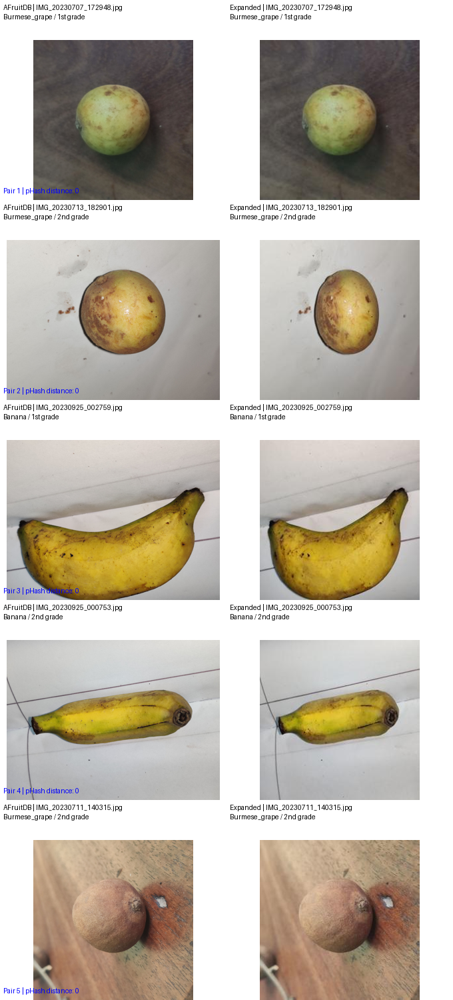


Contact sheet 2: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/phash_contact_sheets/cross_dataset_page_2.png


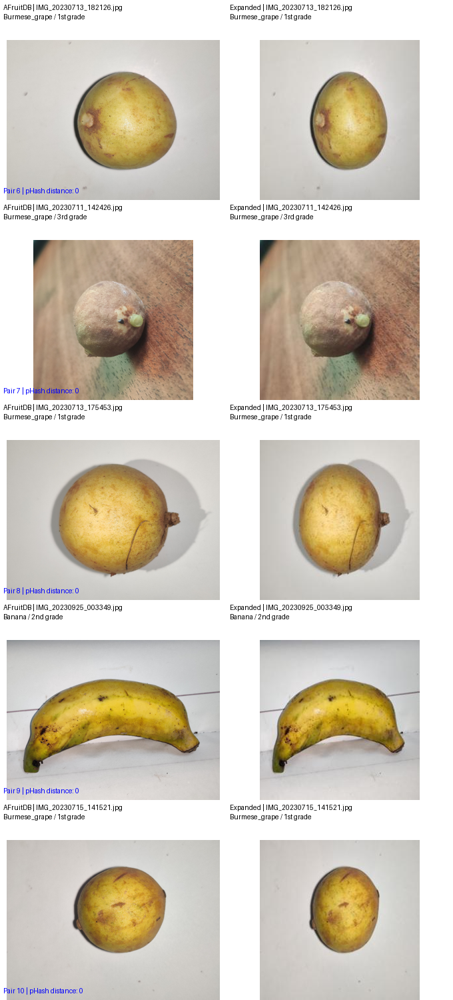


Contact sheet 3: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/phash_contact_sheets/cross_dataset_page_3.png


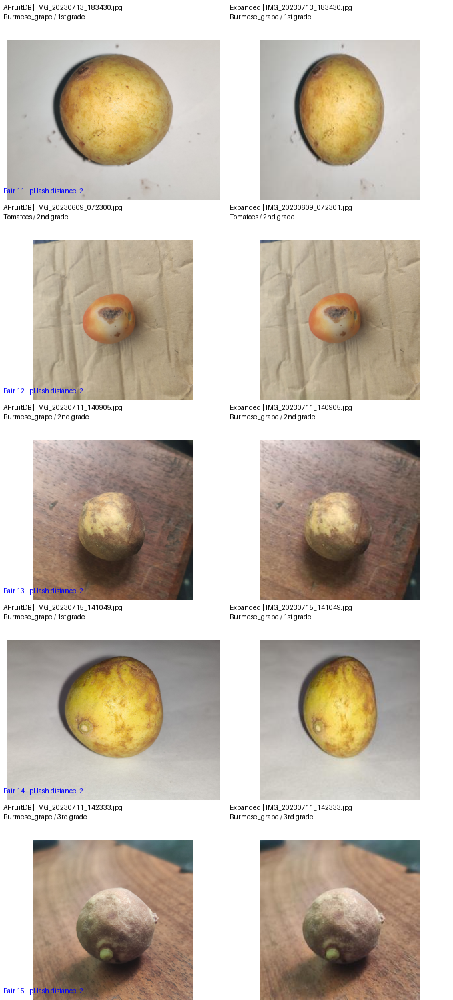


Contact sheet 4: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/phash_contact_sheets/cross_dataset_page_4.png


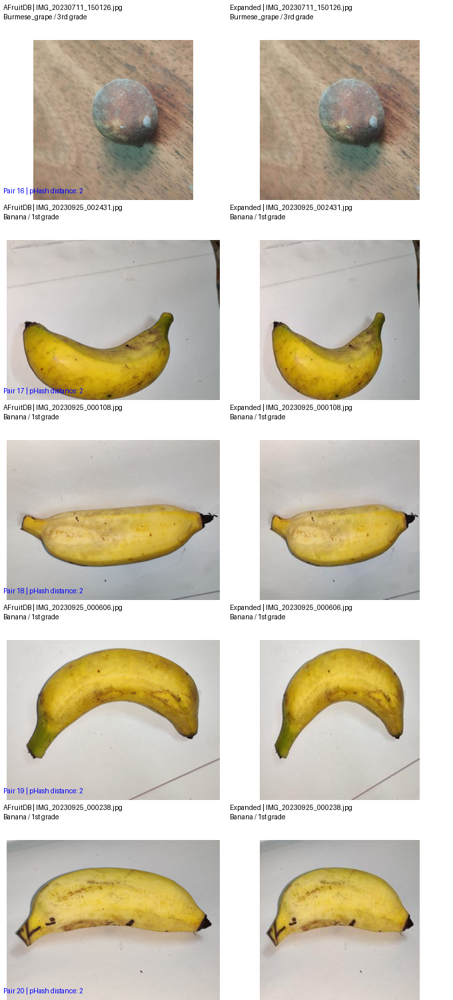


Sample metadata saved.


In [ ]:
import zipfile
import io
import pandas as pd
from PIL import Image, ImageDraw
from pathlib import Path
from IPython.display import display

AUDIT_DIR = BASE_DIR / "datasets" / "audit"
ORIGINAL_DIR = BASE_DIR / "datasets" / "original"

# Load cross-dataset candidate pairs
candidates = pd.read_csv(
    AUDIT_DIR / "cross_dataset_phash_candidates.csv"
)

# Select a reproducible sample
sample_0 = (
    candidates[candidates["hamming_distance"] == 0]
    .sample(n=min(10, len(candidates[candidates["hamming_distance"] == 0])),
            random_state=42)
)

sample_2 = (
    candidates[candidates["hamming_distance"] == 2]
    .sample(n=min(10, len(candidates[candidates["hamming_distance"] == 2])),
            random_state=42)
)

sample = pd.concat([sample_0, sample_2]).reset_index(drop=True)

# Open AFruitDB nested ZIP
outer = zipfile.ZipFile(ORIGINAL_DIR / "AFruitDB_original.zip")

nested_name = [
    n for n in outer.namelist() if n.lower().endswith(".zip")
][0]

afruit_archive = zipfile.ZipFile(
    io.BytesIO(outer.read(nested_name))
)

# Open expanded dataset ZIP
expanded_archive = zipfile.ZipFile(
    ORIGINAL_DIR / "Bangladeshi_Fruit_Grade_original.zip"
)

def get_image(archive, path):
    data = archive.read(path)
    img = Image.open(io.BytesIO(data)).convert("RGB")
    img.thumbnail((320, 240))
    return img

def make_contact_sheet(rows, page_number):
    row_height = 300
    image_width = 340
    label_height = 60

    sheet = Image.new(
        "RGB",
        (image_width * 2, row_height * len(rows)),
        "white"
    )

    draw = ImageDraw.Draw(sheet)

    for i, row in enumerate(rows):
        y = i * row_height

        img_a = get_image(afruit_archive, row["left_path"])
        img_b = get_image(expanded_archive, row["right_path"])

        # Center images in their respective columns
        x_a = (image_width - img_a.width) // 2
        x_b = image_width + (image_width - img_b.width) // 2

        sheet.paste(img_a, (x_a, y + label_height))
        sheet.paste(img_b, (x_b, y + label_height))

        label_a = (
            f"AFruitDB | {row['left_filename']}\n"
            f"{row['left_fruit']} / {row['left_grade']}"
        )

        label_b = (
            f"Expanded | {row['right_filename']}\n"
            f"{row['right_fruit']} / {row['right_grade']}"
        )

        draw.text((5, y + 5), label_a, fill="black")
        draw.text((image_width + 5, y + 5), label_b, fill="black")

        draw.text(
            (5, y + row_height - 20),
            f"Pair {page_number * 5 + i + 1} | "
            f"pHash distance: {row['hamming_distance']}",
            fill="blue"
        )

    return sheet

# Five pairs per page
contact_dir = AUDIT_DIR / "phash_contact_sheets"
contact_dir.mkdir(exist_ok=True)

for page in range((len(sample) + 4) // 5):
    page_rows = sample.iloc[page * 5:(page + 1) * 5]

    sheet = make_contact_sheet(page_rows.to_dict("records"), page)

    output = contact_dir / f"cross_dataset_page_{page + 1}.png"
    sheet.save(output)

    print(f"\nContact sheet {page + 1}: {output}")
    display(sheet)

# Save the sampled pair metadata too
sample.to_csv(
    AUDIT_DIR / "cross_dataset_visual_review_sample.csv",
    index=False
)

print("\nSample metadata saved.")

In [ ]:
import pandas as pd

AUDIT_DIR = BASE_DIR / "datasets" / "audit"

afruit_internal = pd.read_csv(
    AUDIT_DIR / "afruitdb_internal_phash_candidates.csv"
)

print("Total AFruitDB candidate pairs:", len(afruit_internal))

print("\nCandidates by pHash distance:")
print(
    afruit_internal["hamming_distance"]
    .value_counts()
    .sort_index()
)

print("\nCandidates with different grade labels:")
grade_conflicts = afruit_internal[
    afruit_internal["left_grade"] != afruit_internal["right_grade"]
]

print("Count:", len(grade_conflicts))

display(
    grade_conflicts[
        [
            "hamming_distance",
            "left_filename",
            "left_fruit",
            "left_grade",
            "right_filename",
            "right_fruit",
            "right_grade"
        ]
    ].head(20)
)

Total AFruitDB candidate pairs: 96

Candidates by pHash distance:
hamming_distance
0    17
2    16
4    63
Name: count, dtype: int64

Candidates with different grade labels:
Count: 17


,hamming_distance,left_filename,left_fruit,left_grade,right_filename,right_fruit,right_grade
0,4,IMG_20230930_212548.jpg,Apple,2nd grade,IMG_20230713_182846.jpg,Burmese_grape,1st grade
4,4,IMG_20230925_001157.jpg,Banana,1st grade,IMG_20230925_000958.jpg,Banana,2nd grade
5,4,IMG_20230925_002937.jpg,Banana,1st grade,IMG_20230925_002932.jpg,Banana,2nd grade
8,4,IMG_20230713_181036.jpg,Burmese_grape,1st grade,IMG_20230713_180615.jpg,Burmese_grape,2nd grade
10,4,IMG_20230713_181128.jpg,Burmese_grape,1st grade,IMG_20230715_142935.jpg,Burmese_grape,3rd grade
17,4,IMG_20230714_114724.jpg,Burmese_grape,1st grade,IMG_20230713_182811.jpg,Burmese_grape,2nd grade
20,4,IMG_20230714_120653.jpg,Burmese_grape,1st grade,IMG_20230713_182734.jpg,Burmese_grape,2nd grade
21,2,IMG_20230715_141147.jpg,Burmese_grape,1st grade,IMG_20230713_183204.jpg,Burmese_grape,2nd grade
22,2,IMG_20230715_141438.jpg,Burmese_grape,1st grade,IMG_20230713_183523.jpg,Burmese_grape,2nd grade
24,4,IMG_20230715_142531.jpg,Burmese_grape,1st grade,IMG_20230713_183016.jpg,Burmese_grape,2nd grade


Different-label candidate pairs: 18

Page 1: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/afruitdb_label_conflict_sheets/conflicts_page_1.png


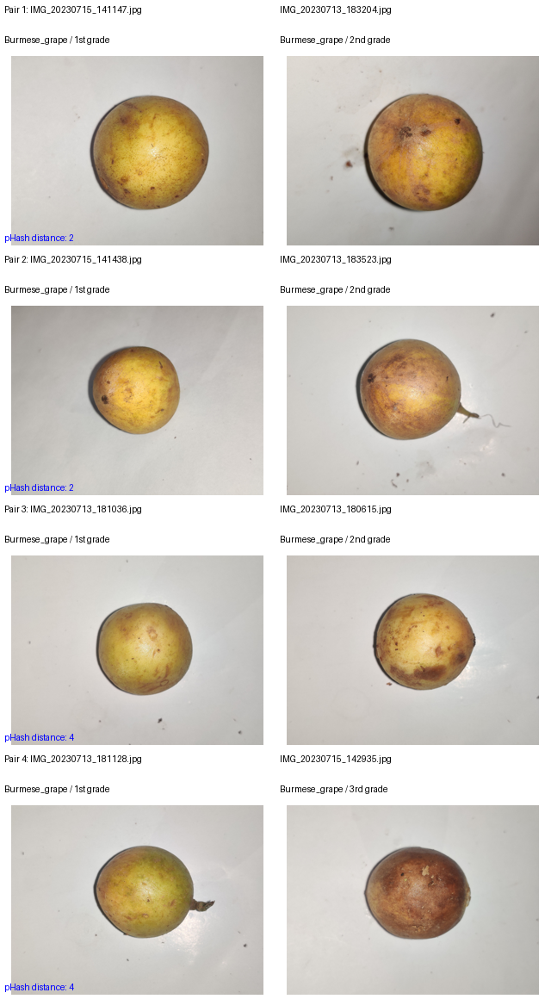


Page 2: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/afruitdb_label_conflict_sheets/conflicts_page_2.png


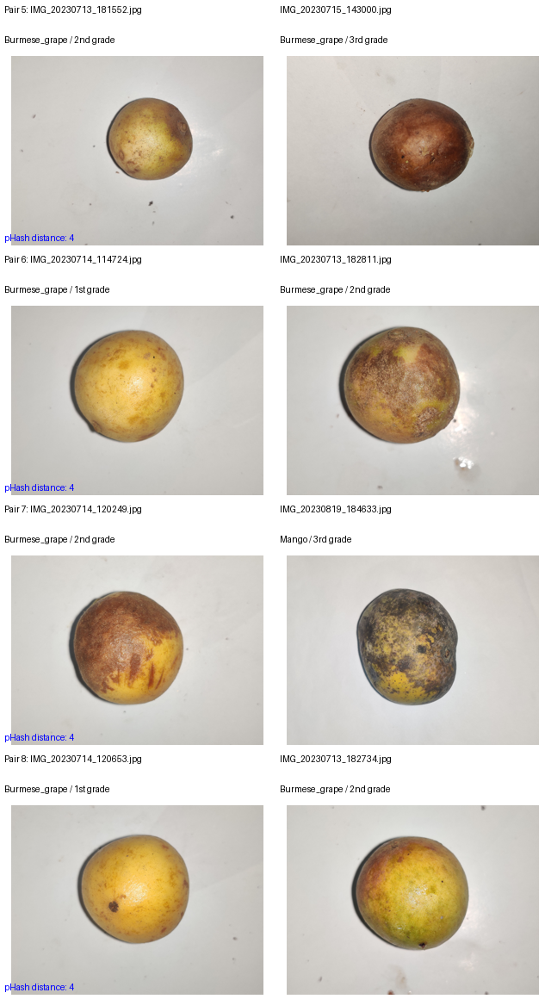


Page 3: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/afruitdb_label_conflict_sheets/conflicts_page_3.png


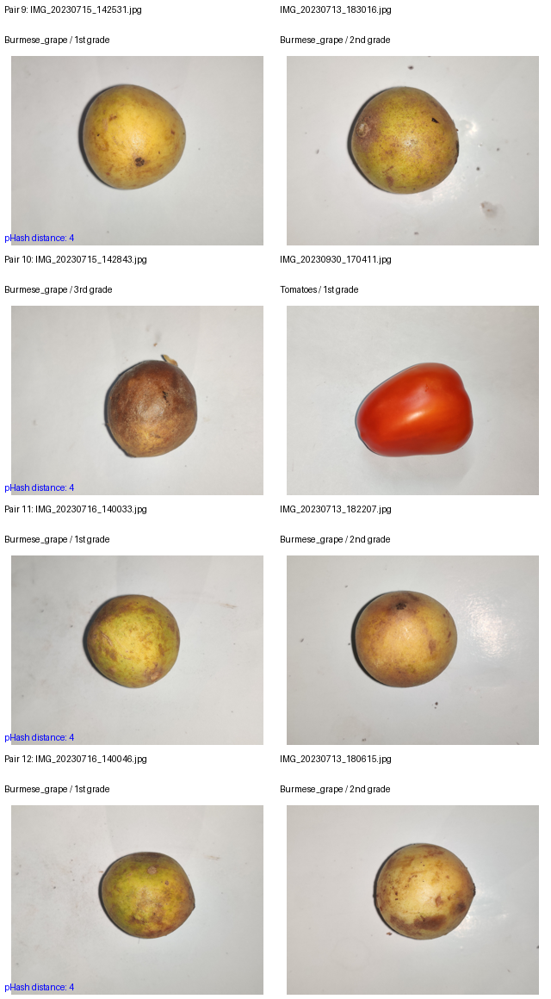


Page 4: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/afruitdb_label_conflict_sheets/conflicts_page_4.png


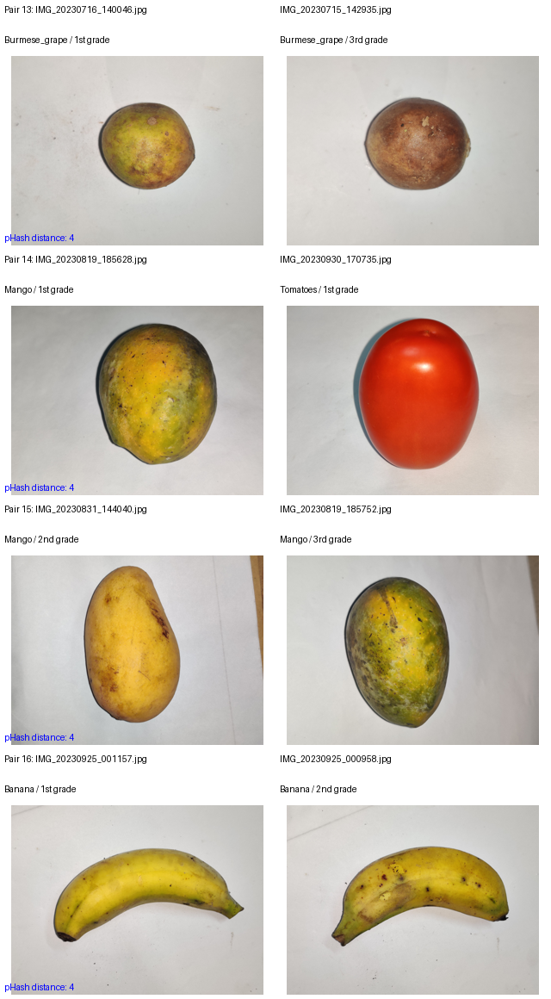


Page 5: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/afruitdb_label_conflict_sheets/conflicts_page_5.png


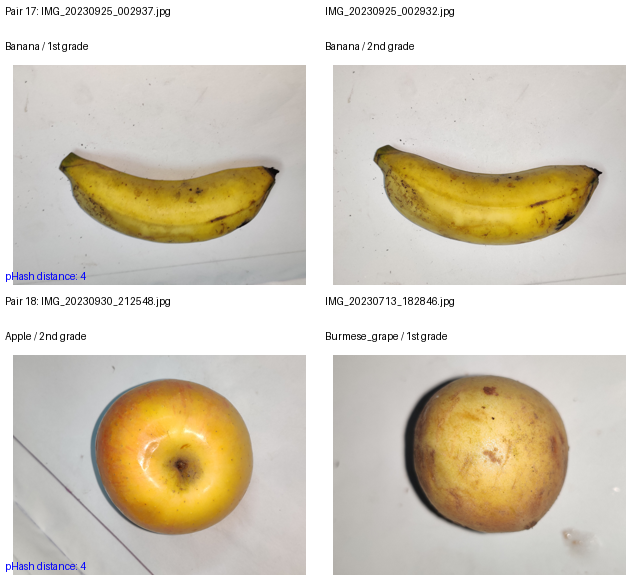


Contact sheets and metadata saved.


In [ ]:
import zipfile
import io
import pandas as pd
from PIL import Image, ImageDraw
from pathlib import Path
from IPython.display import display

AUDIT_DIR = BASE_DIR / "datasets" / "audit"
ORIGINAL_DIR = BASE_DIR / "datasets" / "original"

# Load AFruitDB internal candidates
candidates = pd.read_csv(
    AUDIT_DIR / "afruitdb_internal_phash_candidates.csv"
)

# Select pairs with different labels
conflicts = candidates[
    (candidates["left_fruit"] != candidates["right_fruit"]) |
    (candidates["left_grade"] != candidates["right_grade"])
].copy()

conflicts = conflicts.sort_values(
    ["hamming_distance", "left_filename"]
).reset_index(drop=True)

print("Different-label candidate pairs:", len(conflicts))

# Open AFruitDB nested archive
outer = zipfile.ZipFile(ORIGINAL_DIR / "AFruitDB_original.zip")

nested_name = [
    n for n in outer.namelist()
    if n.lower().endswith(".zip")
][0]

afruit_archive = zipfile.ZipFile(
    io.BytesIO(outer.read(nested_name))
)

def load_image(path):
    data = afruit_archive.read(path)
    img = Image.open(io.BytesIO(data)).convert("RGB")
    img.thumbnail((300, 220))
    return img

# Four pairs per page
contact_dir = AUDIT_DIR / "afruitdb_label_conflict_sheets"
contact_dir.mkdir(exist_ok=True)

pairs_per_page = 4
page_height = 290
column_width = 320

for page in range((len(conflicts) + pairs_per_page - 1) // pairs_per_page):

    rows = conflicts.iloc[
        page * pairs_per_page:(page + 1) * pairs_per_page
    ]

    sheet = Image.new(
        "RGB",
        (column_width * 2, page_height * len(rows)),
        "white"
    )

    draw = ImageDraw.Draw(sheet)

    for i, (_, row) in enumerate(rows.iterrows()):
        y = i * page_height

        img_a = load_image(row["left_path"])
        img_b = load_image(row["right_path"])

        x_a = (column_width - img_a.width) // 2
        x_b = column_width + (column_width - img_b.width) // 2

        sheet.paste(img_a, (x_a, y + 65))
        sheet.paste(img_b, (x_b, y + 65))

        draw.text(
            (5, y + 5),
            f"Pair {page * pairs_per_page + i + 1}: "
            f"{row['left_filename']}",
            fill="black"
        )

        draw.text(
            (column_width + 5, y + 5),
            f"{row['right_filename']}",
            fill="black"
        )

        draw.text(
            (5, y + 40),
            f"{row['left_fruit']} / {row['left_grade']}",
            fill="black"
        )

        draw.text(
            (column_width + 5, y + 40),
            f"{row['right_fruit']} / {row['right_grade']}",
            fill="black"
        )

        draw.text(
            (5, y + page_height - 20),
            f"pHash distance: {row['hamming_distance']}",
            fill="blue"
        )

    output = contact_dir / f"conflicts_page_{page + 1}.png"
    sheet.save(output)

    print(f"\nPage {page + 1}: {output}")
    display(sheet)

# Save metadata for traceability
conflicts.to_csv(
    AUDIT_DIR / "afruitdb_different_label_candidates.csv",
    index=False
)

print("\nContact sheets and metadata saved.")

In [ ]:
import pandas as pd

AUDIT_DIR = BASE_DIR / "datasets" / "audit"

candidates = pd.read_csv(
    AUDIT_DIR / "afruitdb_internal_phash_candidates.csv"
)

# Keep only candidates with matching fruit and grade labels
matching = candidates[
    (candidates["left_fruit"] == candidates["right_fruit"]) &
    (candidates["left_grade"] == candidates["right_grade"])
].copy()

matching = matching.sort_values(
    ["hamming_distance", "left_filename"]
).reset_index(drop=True)

print("Matching-label candidate pairs:", len(matching))

print("\nDistribution by pHash distance:")
print(matching["hamming_distance"].value_counts().sort_index())

matching.to_csv(
    AUDIT_DIR / "afruitdb_matching_label_candidates.csv",
    index=False
)

display(matching.head(15))

print("\nSaved matching-label candidate report.")

Matching-label candidate pairs: 78

Distribution by pHash distance:
hamming_distance
0    17
2    14
4    47
Name: count, dtype: int64


,comparison,hamming_distance,left_filename,left_path,left_fruit,left_grade,left_sha256,right_filename,right_path,right_fruit,right_grade,right_sha256
0,AFruitDB_internal,0,IMG_20230423_115717.jpg,Fruits Grade/Fruit grade/Papayas/2nd grade/IMG...,Papayas,2nd grade,581f0d9a8ea8d62b2960ce763a7f720752dbfc33698aea...,IMG_20230423_115718.jpg,Fruits Grade/Fruit grade/Papayas/2nd grade/IMG...,Papayas,2nd grade,1ec20560b6cae70126f0b4b4052c7adbf3c29f5ac4ed58...
1,AFruitDB_internal,0,IMG_20230609_072928.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,c7c5c0cc4888ee41dd39c7039308d19768e850e4631805...,IMG_20230609_072931.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,1daa637cff6577ce464b561396ba92e9e2103a1721a6a5...
2,AFruitDB_internal,0,IMG_20230609_073035_2.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,791420936523569291294d5e013ef2013084483b11bc18...,IMG_20230609_073035_3.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,a70c39c11afccd2ef414576e0c0e9847419c864ef22c4c...
3,AFruitDB_internal,0,IMG_20230609_073035_2.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,791420936523569291294d5e013ef2013084483b11bc18...,IMG_20230609_073036.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,b14375c785d5adc4cfd3367d9b988986740e1f085745d6...
4,AFruitDB_internal,0,IMG_20230609_073035_3.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,a70c39c11afccd2ef414576e0c0e9847419c864ef22c4c...,IMG_20230609_073036.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,b14375c785d5adc4cfd3367d9b988986740e1f085745d6...
5,AFruitDB_internal,0,IMG_20230609_073051.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,98921b22298a2686ae9730ef71ef6fe904ebcab4165478...,IMG_20230609_073051_1.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,68ae7cb05fbaa97fb99228304c742d8159f73ec4193668...
6,AFruitDB_internal,0,IMG_20230609_073101_1.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,bbaaee5357f33f729282b4babf0edd7e5600ba4b6b10af...,IMG_20230609_073101_2.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,4bf4982cefa50854b8413c02eeda1c6c2261df52f83b7f...
7,AFruitDB_internal,0,IMG_20230609_073101_1.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,bbaaee5357f33f729282b4babf0edd7e5600ba4b6b10af...,IMG_20230609_073101_3.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,72a03ae9490ac06f9dcd962d1cbf0853ad76706ed56494...
8,AFruitDB_internal,0,IMG_20230609_073101_1.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,bbaaee5357f33f729282b4babf0edd7e5600ba4b6b10af...,IMG_20230609_073101_4.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,840f7e340db91712c0b83782a73a5b06ba9170fe540859...
9,AFruitDB_internal,0,IMG_20230609_073101_1.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,bbaaee5357f33f729282b4babf0edd7e5600ba4b6b10af...,IMG_20230609_073101_5.jpg,Fruits Grade/Fruit grade/Tomatoes/2nd grade/IM...,Tomatoes,2nd grade,997ca6044b5e3d568d9bf4a49fd02bf857187cf42aa31c...



Saved matching-label candidate report.


AFruitDB archive: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/original/AFruitDB_original.zip
Candidate CSV: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/afruitdb_matching_label_candidates.csv
Output directory: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/afruitdb_matching_label_sheets

Candidate pairs loaded: 78

Candidates by pHash distance:
hamming_distance
0    17
2    14
4    47
Name: count, dtype: int64

Inspecting outer AFruitDB archive...
Nested archive found:
A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip

Image members available in nested ZIP: 3193

Generating contact sheets...
Pairs per page: 6
Expected pages: 13
Saved page 1/13: matching_label_page_01.png
Saved page 2/13: matching_label_page_02.png
Saved page 3/13: matching_label_page_03.png
Saved page 4/13: matching_label_page_04.png
Saved page 5/13: matching_label_page_05.png
Saved page 6/13: matching_label_page_06.png
Saved p

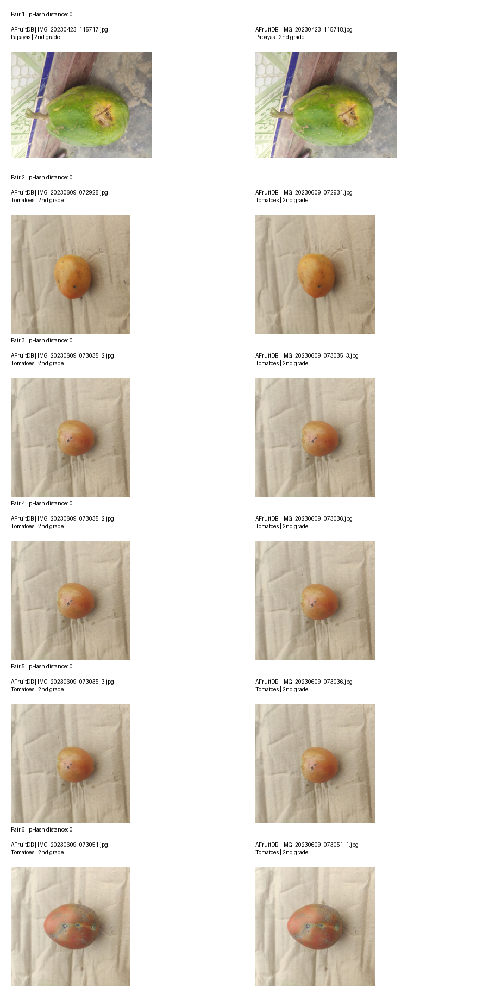


 matching_label_page_02.png


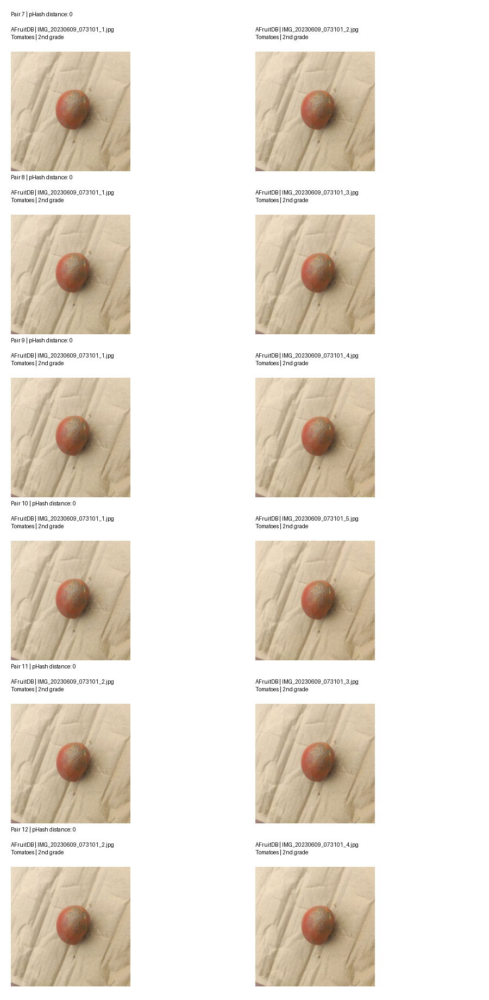


 matching_label_page_03.png


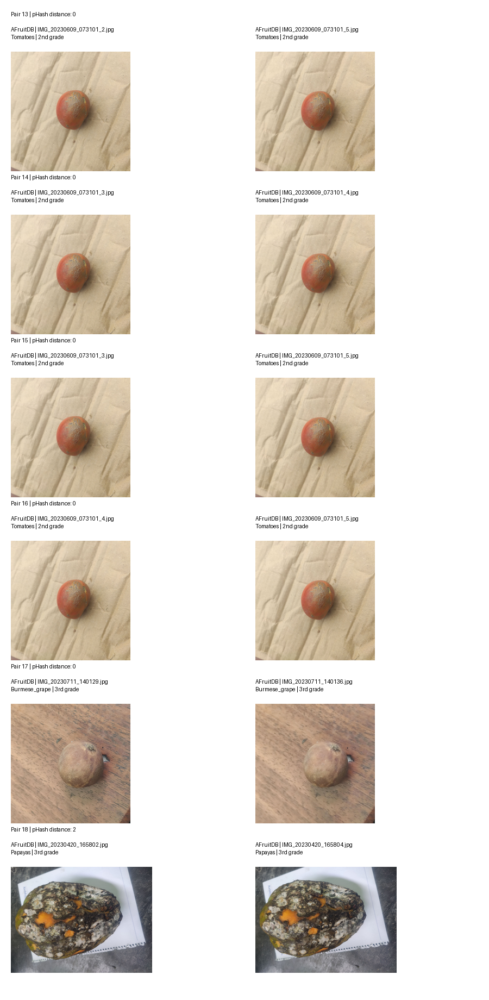


 matching_label_page_04.png


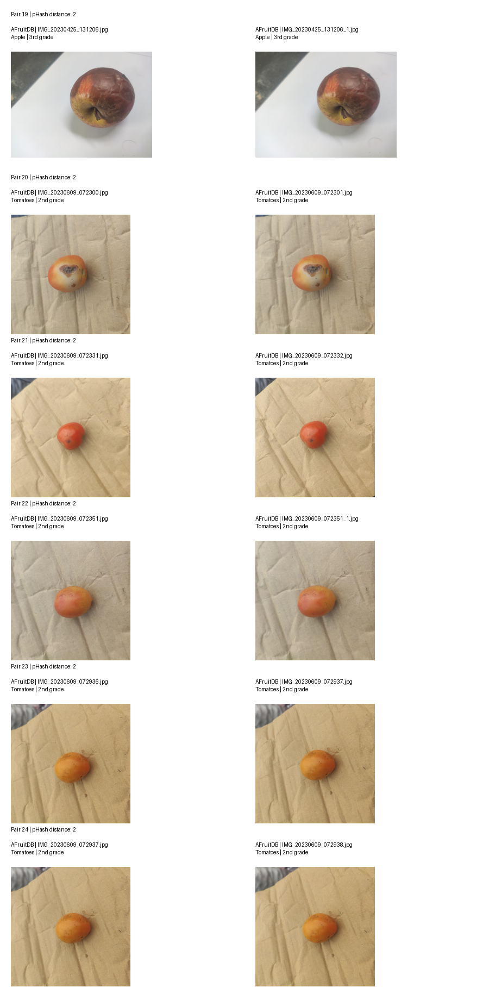


 matching_label_page_05.png


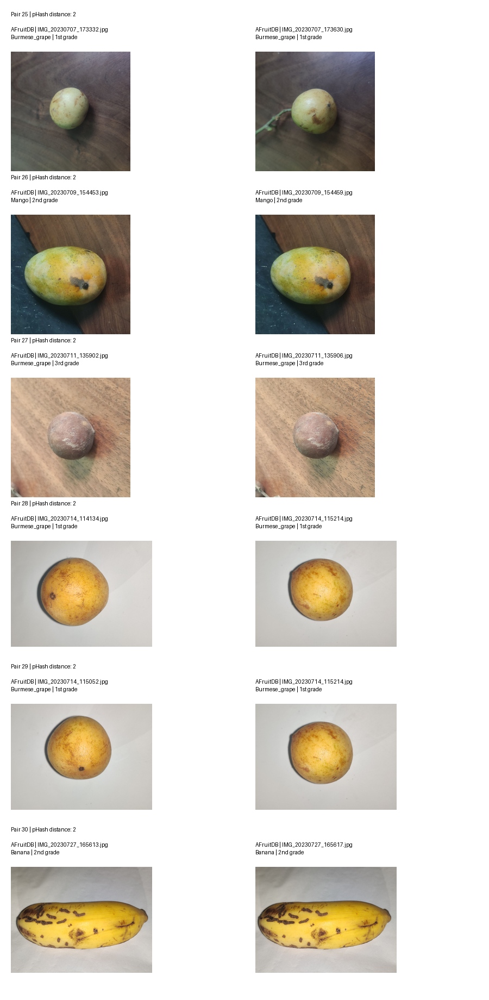


 matching_label_page_06.png


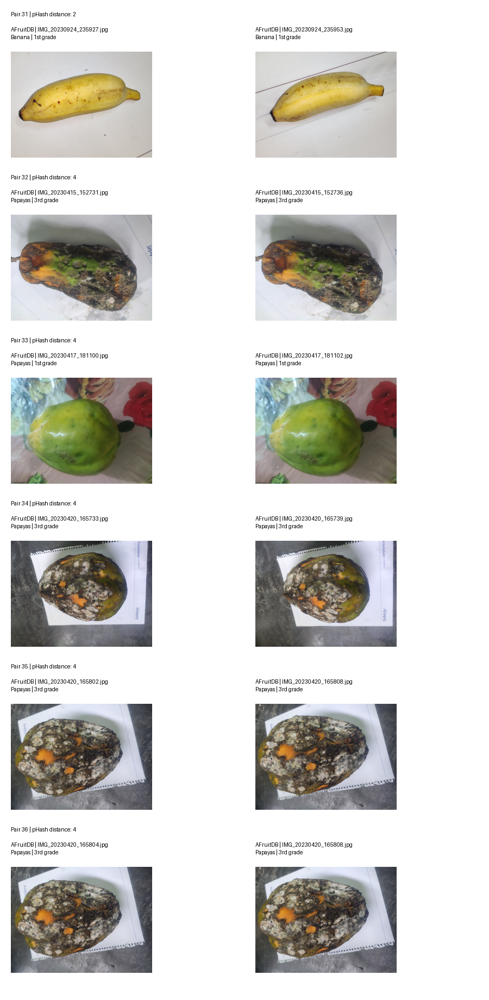


 matching_label_page_07.png


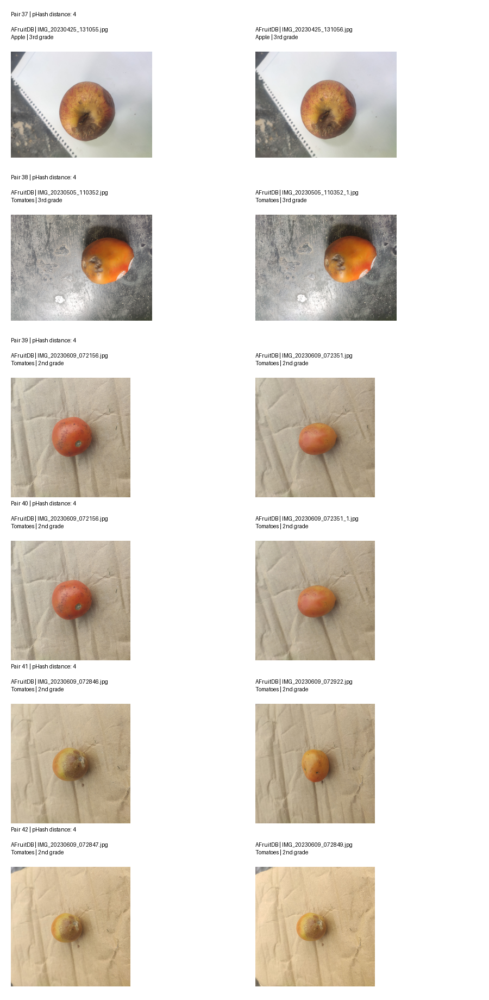


 matching_label_page_08.png


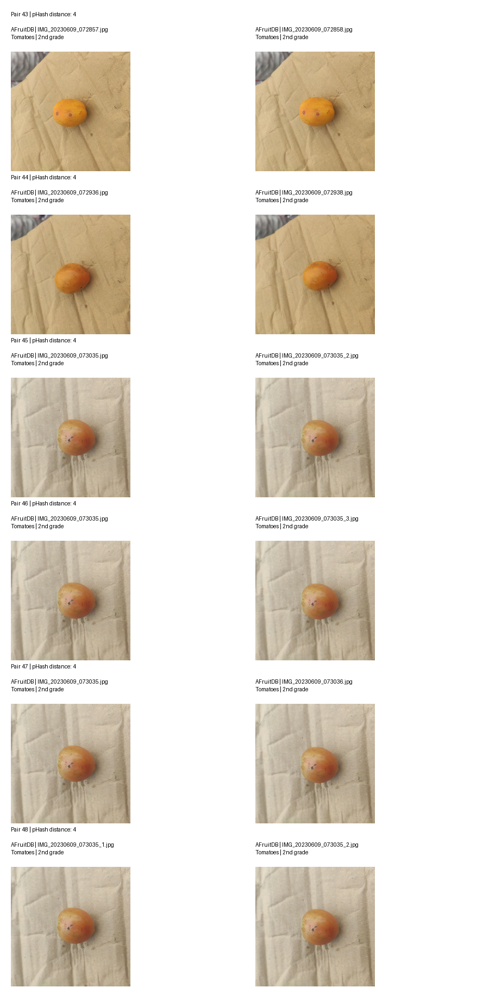


 matching_label_page_09.png


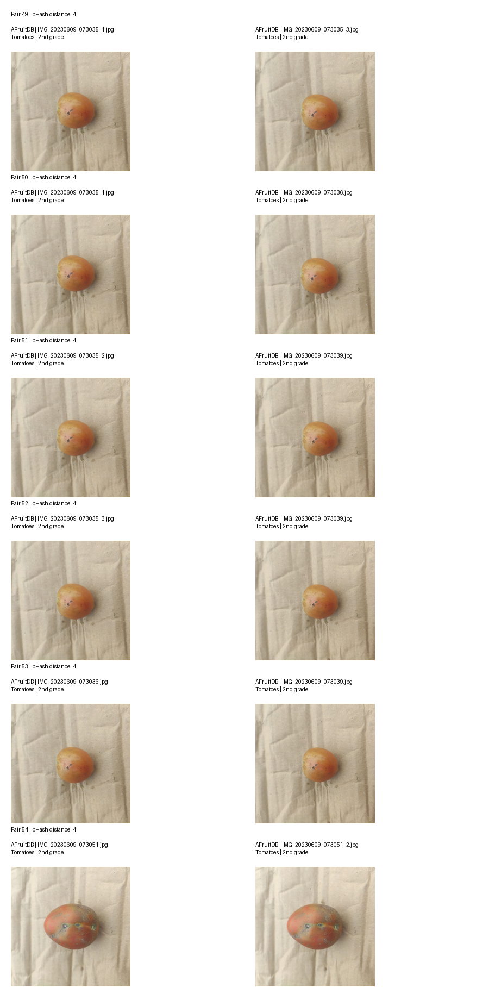


 matching_label_page_10.png


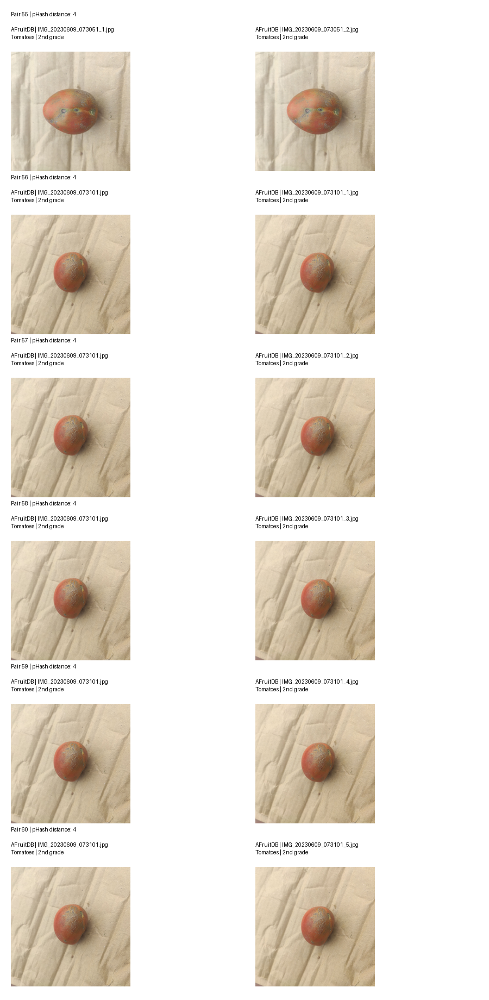


 matching_label_page_11.png


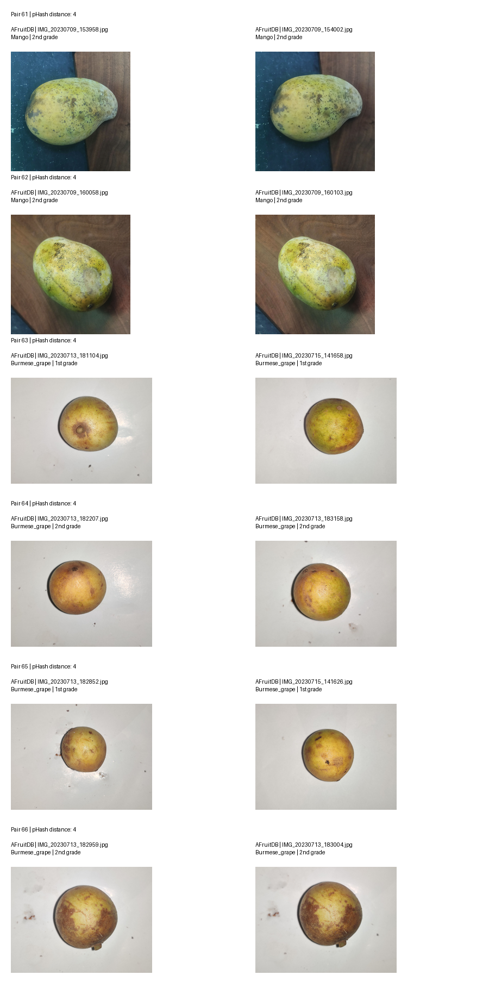


 matching_label_page_12.png


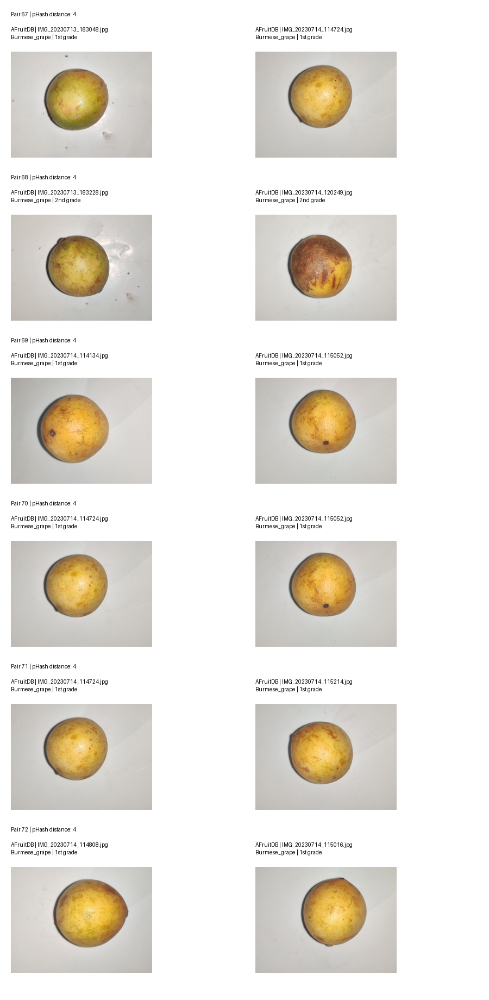


 matching_label_page_13.png


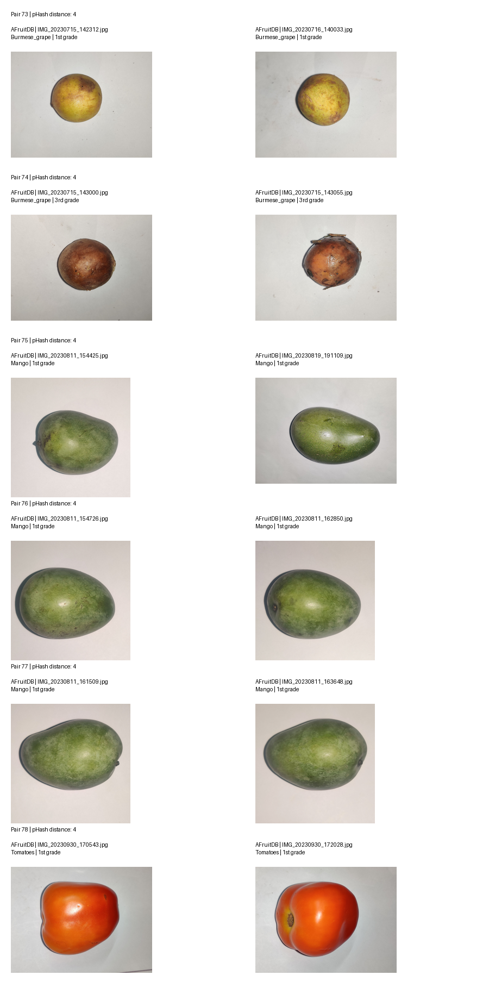

In [ ]:

# ================================================================
# AFruitDB: CONTACT SHEETS FOR MATCHING-LABEL pHASH CANDIDATES
# Purpose:
#   Visually inspect the 78 within-dataset candidate pairs whose
#   fruit and grade labels match but whose images have similar pHash.
#
# Reads:
#   datasets/original/AFruitDB_original.zip
#   datasets/audit/afruitdb_matching_label_candidates.csv
#
# Writes:
#   datasets/audit/afruitdb_matching_label_sheets/
#
# Original archives and manifests are never modified.
# ================================================================

from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import math
import pandas as pd
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

# ------------------------------------------------
# 1. Define paths
# ------------------------------------------------

BASE_DIR = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research"
)

ORIGINAL_DIR = BASE_DIR / "datasets" / "original"
AUDIT_DIR = BASE_DIR / "datasets" / "audit"

ARCHIVE_PATH = ORIGINAL_DIR / "AFruitDB_original.zip"

CANDIDATE_CSV = (
    AUDIT_DIR / "afruitdb_matching_label_candidates.csv"
)

OUTPUT_DIR = (
    AUDIT_DIR / "afruitdb_matching_label_sheets"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 2. Check required files
# ------------------------------------------------

for required_file in [ARCHIVE_PATH, CANDIDATE_CSV]:
    if not required_file.exists():
        raise FileNotFoundError(
            f"Required file not found: {required_file}"
        )

print("AFruitDB archive:", ARCHIVE_PATH)
print("Candidate CSV:", CANDIDATE_CSV)
print("Output directory:", OUTPUT_DIR)

# ------------------------------------------------
# 3. Load candidate pairs
# ------------------------------------------------

candidates = pd.read_csv(CANDIDATE_CSV)

required_columns = [
    "hamming_distance",
    "left_filename",
    "left_path",
    "left_fruit",
    "left_grade",
    "right_filename",
    "right_path",
    "right_fruit",
    "right_grade",
]

missing_columns = [
    col for col in required_columns
    if col not in candidates.columns
]

if missing_columns:
    raise ValueError(
        f"Candidate CSV is missing columns: {missing_columns}"
    )

candidates = candidates.drop_duplicates(
    subset=["left_path", "right_path"]
).reset_index(drop=True)

print("\nCandidate pairs loaded:", len(candidates))

print("\nCandidates by pHash distance:")
print(
    candidates["hamming_distance"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------
# 4. Locate the nested ZIP inside the outer archive
# ------------------------------------------------

print("\nInspecting outer AFruitDB archive...")

with ZipFile(ARCHIVE_PATH, "r") as outer_zip:

    nested_zip_names = [
        name for name in outer_zip.namelist()
        if name.lower().endswith(".zip")
    ]

    if len(nested_zip_names) != 1:
        raise RuntimeError(
            "Expected exactly one nested ZIP archive, "
            f"but found {len(nested_zip_names)}: "
            f"{nested_zip_names}"
        )

    nested_zip_name = nested_zip_names[0]

    print("Nested archive found:")
    print(nested_zip_name)

    nested_zip_bytes = outer_zip.read(nested_zip_name)

# ------------------------------------------------
# 5. Open nested ZIP in memory
# ------------------------------------------------

nested_zip_buffer = BytesIO(nested_zip_bytes)

image_zip = ZipFile(nested_zip_buffer, "r")

available_members = set(image_zip.namelist())

print(
    "\nImage members available in nested ZIP:",
    len(available_members)
)

# ------------------------------------------------
# 6. Image-loading function
# ------------------------------------------------

def load_image_from_archive(relative_path):

    # Normalize path separators for ZIP lookup
    relative_path = str(relative_path).replace("\\", "/")

    if relative_path not in available_members:
        raise FileNotFoundError(
            f"Image not found inside nested ZIP: {relative_path}"
        )

    image_bytes = image_zip.read(relative_path)

    image = Image.open(BytesIO(image_bytes)).convert("RGB")

    return image


# ------------------------------------------------
# 7. Contact-sheet settings
# ------------------------------------------------

PAIRS_PER_PAGE = 6

IMAGE_WIDTH = 260
IMAGE_HEIGHT = 220

PAGE_WIDTH = 900
LEFT_MARGIN = 20
TOP_MARGIN = 20

PAIR_BLOCK_HEIGHT = 300

BACKGROUND = "white"
TEXT_COLOR = "black"

try:
    FONT = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        15
    )
    SMALL_FONT = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        12
    )
except OSError:
    FONT = ImageFont.load_default()
    SMALL_FONT = ImageFont.load_default()


# ------------------------------------------------
# 8. Resize image without distorting its aspect ratio
# ------------------------------------------------

def make_thumbnail(image):

    image = image.copy()

    image.thumbnail(
        (IMAGE_WIDTH, IMAGE_HEIGHT),
        Image.Resampling.LANCZOS
    )

    return image


# ------------------------------------------------
# 9. Generate contact-sheet pages
# ------------------------------------------------

total_pairs = len(candidates)

total_pages = math.ceil(
    total_pairs / PAIRS_PER_PAGE
)

generated_files = []
error_records = []

print("\nGenerating contact sheets...")
print("Pairs per page:", PAIRS_PER_PAGE)
print("Expected pages:", total_pages)

for page_index in range(total_pages):

    start = page_index * PAIRS_PER_PAGE
    end = min(
        start + PAIRS_PER_PAGE,
        total_pairs
    )

    page_candidates = candidates.iloc[start:end]

    page_height = (
        TOP_MARGIN
        + len(page_candidates) * PAIR_BLOCK_HEIGHT
        + 20
    )

    sheet = Image.new(
        "RGB",
        (PAGE_WIDTH, page_height),
        BACKGROUND
    )

    draw = ImageDraw.Draw(sheet)

    for local_index, (_, row) in enumerate(
        page_candidates.iterrows()
    ):

        pair_number = start + local_index + 1

        y = TOP_MARGIN + local_index * PAIR_BLOCK_HEIGHT

        try:

            # Load both images
            image_left = load_image_from_archive(
                row["left_path"]
            )

            image_right = load_image_from_archive(
                row["right_path"]
            )

            image_left = make_thumbnail(image_left)
            image_right = make_thumbnail(image_right)

            # Column positions
            left_x = LEFT_MARGIN
            right_x = 470

            # Pair heading
            heading = (
                f"Pair {pair_number} | "
                f"pHash distance: {row['hamming_distance']}"
            )

            draw.text(
                (LEFT_MARGIN, y),
                heading,
                fill=TEXT_COLOR,
                font=FONT
            )

            # Left-side metadata
            left_metadata = (
                f"AFruitDB | {row['left_filename']}\n"
                f"{row['left_fruit']} | {row['left_grade']}"
            )

            draw.multiline_text(
                (left_x, y + 28),
                left_metadata,
                fill=TEXT_COLOR,
                font=SMALL_FONT,
                spacing=4
            )

            # Right-side metadata
            right_metadata = (
                f"AFruitDB | {row['right_filename']}\n"
                f"{row['right_fruit']} | {row['right_grade']}"
            )

            draw.multiline_text(
                (right_x, y + 28),
                right_metadata,
                fill=TEXT_COLOR,
                font=SMALL_FONT,
                spacing=4
            )

            # Image positions
            image_y = y + 75

            sheet.paste(
                image_left,
                (left_x, image_y)
            )

            sheet.paste(
                image_right,
                (right_x, image_y)
            )

        except Exception as exc:

            error_records.append({
                "pair_number": pair_number,
                "left_path": row["left_path"],
                "right_path": row["right_path"],
                "error": str(exc)
            })

            draw.text(
                (LEFT_MARGIN, y + 40),
                f"ERROR loading pair {pair_number}: {exc}",
                fill="red",
                font=SMALL_FONT
            )

    # Save page
    output_path = (
        OUTPUT_DIR /
        f"matching_label_page_{page_index + 1:02d}.png"
    )

    sheet.save(
        output_path,
        format="PNG",
        optimize=True
    )

    generated_files.append(output_path)

    print(
        f"Saved page {page_index + 1}/{total_pages}: "
        f"{output_path.name}"
    )

# ------------------------------------------------
# 10. Save error report
# ------------------------------------------------

error_df = pd.DataFrame(error_records)

error_report_path = (
    AUDIT_DIR / "afruitdb_matching_label_sheet_errors.csv"
)

error_df.to_csv(
    error_report_path,
    index=False
)

# ------------------------------------------------
# 11. Save metadata used for this review
# ------------------------------------------------

metadata_path = (
    OUTPUT_DIR / "matching_label_candidate_metadata.csv"
)

candidates.to_csv(
    metadata_path,
    index=False
)

# ------------------------------------------------
# 12. Close ZIP handle
# ------------------------------------------------

image_zip.close()

# ------------------------------------------------
# 13. Summary
# ------------------------------------------------

print("\n" + "=" * 60)
print("CONTACT-SHEET GENERATION SUMMARY")
print("=" * 60)

print("Candidate pairs:", total_pairs)
print("Pages generated:", len(generated_files))
print("Image-loading errors:", len(error_records))

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nError report:")
print(error_report_path)

print("\nMetadata report:")
print(metadata_path)

if error_records:
    print("\nWARNING: Some images could not be loaded.")
    display(error_df)
else:
    print("\nAll candidate images loaded successfully.")

# ------------------------------------------------
# 14. Display generated pages
# ------------------------------------------------

print("\nDisplaying contact sheets...")

for path in generated_files:

    print("\n", path.name)

    display(
        Image.open(path)
    )


In [ ]:

from pathlib import Path
from zipfile import ZipFile
from collections import Counter
import io
import pandas as pd

BASE_DIR = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research"
)

ARCHIVE = (
    BASE_DIR / "datasets/original/AFruitDB_original.zip"
)

MANIFEST = (
    BASE_DIR / "datasets/audit/afruitdb_image_manifest.csv"
)

AUDIT_DIR = BASE_DIR / "datasets/audit"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".webp",
    ".bmp", ".tif", ".tiff"
}

# 1. Open the outer ZIP and locate the nested ZIP
with ZipFile(ARCHIVE) as outer:
    nested_names = [
        name for name in outer.namelist()
        if name.lower().endswith(".zip")
    ]

    print("Nested ZIP files:", nested_names)

    if len(nested_names) != 1:
        raise ValueError(
            f"Expected one nested ZIP, found {len(nested_names)}"
        )

    nested_bytes = outer.read(nested_names[0])

# 2. Inspect all members of the nested ZIP
with ZipFile(io.BytesIO(nested_bytes)) as inner:
    all_files = [
        name for name in inner.namelist()
        if not name.endswith("/")
    ]

    image_members = [
        name for name in all_files
        if Path(name).suffix.lower() in IMAGE_EXTENSIONS
    ]

    extension_counts = Counter(
        Path(name).suffix.lower()
        for name in image_members
    )

    path_counts = Counter(image_members)

    duplicate_archive_paths = {
        path: count
        for path, count in path_counts.items()
        if count > 1
    }

# 3. Load the previous SHA-256 manifest
manifest = pd.read_csv(MANIFEST)

manifest_paths = set(
    manifest["relative_path"].astype(str)
)

archive_paths = set(image_members)

missing_from_manifest = archive_paths - manifest_paths
not_found_in_archive = manifest_paths - archive_paths

# 4. Print the reconciliation results
print("\n========== AFruitDB COUNT AUDIT ==========")

print("All files in nested ZIP:", len(all_files))
print("Image members in nested ZIP:", len(image_members))
print("Unique image paths:", len(archive_paths))
print("Duplicate archive paths:", len(duplicate_archive_paths))

print("\nImage extensions:")
for ext, count in sorted(extension_counts.items()):
    print(f"{ext}: {count}")

print("\nPrevious manifest rows:", len(manifest))
print("Unique manifest paths:", manifest_paths.__len__())

print("\nIn archive but absent from manifest:",
      len(missing_from_manifest))

print("In manifest but absent from archive:",
      len(not_found_in_archive))

print("\nDuplicate archive path examples:")
for path, count in list(duplicate_archive_paths.items())[:10]:
    print(count, path)

print("\nArchive paths missing from manifest (first 20):")
for path in sorted(missing_from_manifest)[:20]:
    print(path)

print("\nManifest paths not found in archive (first 20):")
for path in sorted(not_found_in_archive)[:20]:
    print(path)

# 5. Save a reconciliation report
summary = pd.DataFrame([{
    "nested_zip_total_files": len(all_files),
    "nested_zip_image_members": len(image_members),
    "unique_image_paths": len(archive_paths),
    "duplicate_archive_paths": len(duplicate_archive_paths),
    "manifest_rows": len(manifest),
    "unique_manifest_paths": len(manifest_paths),
    "archive_missing_from_manifest": len(missing_from_manifest),
    "manifest_missing_from_archive": len(not_found_in_archive)
}])

summary.to_csv(
    AUDIT_DIR / "afruitdb_count_reconciliation.csv",
    index=False
)

print("\nSaved count reconciliation report.")


Nested ZIP files: ['A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip']

========== AFruitDB COUNT AUDIT ==========
All files in nested ZIP: 3167
Image members in nested ZIP: 3167
Unique image paths: 3167
Duplicate archive paths: 0

Image extensions:
.jpg: 3167

Previous manifest rows: 3167
Unique manifest paths: 3167

In archive but absent from manifest: 0
In manifest but absent from archive: 0

Duplicate archive path examples:

Archive paths missing from manifest (first 20):

Manifest paths not found in archive (first 20):

Saved count reconciliation report.


In [ ]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research"
)
AUDIT_DIR = BASE_DIR / "datasets" / "audit"

ORIGINAL_MANIFEST = (
    AUDIT_DIR / "afruitdb_image_manifest.csv"
)

CANDIDATE_MANIFEST = (
    AUDIT_DIR / "afruitdb_candidate_image_group_manifest_v2.csv"
)

# Load both manifests
original = pd.read_csv(ORIGINAL_MANIFEST)
candidate = pd.read_csv(CANDIDATE_MANIFEST)

print("Original manifest:", original.shape)
print("Candidate manifest:", candidate.shape)

# Standardize paths for reliable matching
original["relative_path"] = (
    original["relative_path"].astype(str).str.replace("\\", "/", regex=False)
)
candidate["image_path"] = (
    candidate["image_path"].astype(str).str.replace("\\", "/", regex=False)
)

# Check that candidate paths exist in the original manifest
original_paths = set(original["relative_path"])
candidate_paths = set(candidate["image_path"])

missing_paths = candidate_paths - original_paths

print("\nCandidate paths:", len(candidate_paths))
print("Candidate paths missing from original:", len(missing_paths))

if missing_paths:
    print("\nExamples of unmatched paths:")
    for path in sorted(missing_paths)[:10]:
        print(path)
    raise ValueError(
        "Path mismatch detected. Stop and investigate before merging."
    )

# Select only the columns needed for the merge
group_info = candidate[
    [
        "image_path",
        "duplicate_group_id",
        "grouping_status",
        "candidate_pair_ids"
    ]
].copy()

# Rename the candidate path to match the original manifest
group_info = group_info.rename(
    columns={"image_path": "relative_path"}
)

# Merge without changing the original manifest
complete = original.merge(
    group_info,
    on="relative_path",
    how="left",
    validate="one_to_one"
)

# Mark images not assigned to a group by the current review
complete["grouping_status"] = (
    complete["grouping_status"]
    .fillna("not_flagged_by_current_review")
)

# Validate the result
print("\n========== COMPLETE MANIFEST CHECK ==========")
print("Original images:", len(original))
print("Complete manifest rows:", len(complete))
print("Unique image paths:", complete["relative_path"].nunique())

grouped = complete[
    complete["duplicate_group_id"].notna()
]

print("Images assigned to duplicate groups:", len(grouped))
print(
    "Images not flagged by current review:",
    len(complete) - len(grouped)
)
print(
    "Duplicate groups:",
    grouped["duplicate_group_id"].nunique()
)

# Check whether labels and hashes agree with the candidate manifest
check = complete[
    complete["duplicate_group_id"].notna()
].merge(
    candidate[
        ["image_path", "fruit", "grade", "sha256"]
    ],
    left_on="relative_path",
    right_on="image_path",
    suffixes=("_original", "_candidate"),
    validate="one_to_one"
)

for column in ["fruit", "grade", "sha256"]:
    mismatch = (
        check[f"{column}_original"].astype(str)
        != check[f"{column}_candidate"].astype(str)
    )
    print(f"{column} mismatches:", int(mismatch.sum()))

# Save the complete manifest
output_file = (
    AUDIT_DIR / "afruitdb_complete_grouped_manifest_v2.csv"
)

complete.to_csv(output_file, index=False)

# Save a compact summary
summary = pd.DataFrame([{
    "total_images": len(complete),
    "unique_image_paths": complete["relative_path"].nunique(),
    "images_in_provisional_groups": len(grouped),
    "provisional_duplicate_groups": grouped[
        "duplicate_group_id"
    ].nunique(),
    "images_not_flagged_by_current_review": len(complete) - len(grouped),
    "candidate_paths_missing": len(missing_paths)
}])

summary_file = (
    AUDIT_DIR / "afruitdb_complete_grouped_manifest_summary_v2.csv"
)

summary.to_csv(summary_file, index=False)

print("\nSaved:")
print(output_file)
print(summary_file)


Original manifest: (3167, 7)
Candidate manifest: (95, 8)

Candidate paths: 95
Candidate paths missing from original: 0

========== COMPLETE MANIFEST CHECK ==========
Original images: 3167
Complete manifest rows: 3167
Unique image paths: 3167
Images assigned to duplicate groups: 62
Images not flagged by current review: 3105
Duplicate groups: 25
fruit mismatches: 0
grade mismatches: 0
sha256 mismatches: 0

Saved:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/afruitdb_complete_grouped_manifest_v2.csv
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/afruitdb_complete_grouped_manifest_summary_v2.csv


In [ ]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research"
)
AUDIT_DIR = BASE_DIR / "datasets" / "audit"

# Load the original image manifests
afruit = pd.read_csv(
    AUDIT_DIR / "afruitdb_image_manifest.csv"
)

bangladeshi = pd.read_csv(
    AUDIT_DIR / "expanded_image_manifest.csv"
)

def audit_internal_duplicates(df, dataset_name):
    # Each hash represents the exact contents of an image file.
    duplicate_hashes = df[
        df.duplicated("sha256", keep=False)
    ].copy()

    if duplicate_hashes.empty:
        summary = {
            "dataset": dataset_name,
            "total_images": len(df),
            "duplicate_hash_groups": 0,
            "images_in_duplicate_groups": 0,
            "duplicate_groups_with_label_conflicts": 0
        }
        return summary, duplicate_hashes

    # Summarize each repeated hash.
    records = []

    for sha256, group in duplicate_hashes.groupby("sha256"):
        label_combinations = (
            group[["fruit", "grade"]]
            .drop_duplicates()
        )

        records.append({
            "dataset": dataset_name,
            "sha256": sha256,
            "number_of_files": len(group),
            "fruit_labels": " | ".join(
                sorted(group["fruit"].astype(str).unique())
            ),
            "grade_labels": " | ".join(
                sorted(group["grade"].astype(str).unique())
            ),
            "label_conflict": len(label_combinations) > 1,
            "relative_paths": " | ".join(
                group["relative_path"].astype(str)
            )
        })

    details = pd.DataFrame(records)

    summary = {
        "dataset": dataset_name,
        "total_images": len(df),
        "duplicate_hash_groups": len(details),
        "images_in_duplicate_groups": len(duplicate_hashes),
        "duplicate_groups_with_label_conflicts": int(
            details["label_conflict"].sum()
        )
    }

    return summary, details


summary_a, details_a = audit_internal_duplicates(
    afruit, "AFruitDB"
)

summary_b, details_b = audit_internal_duplicates(
    bangladeshi, "Bangladeshi Fruit Grade"
)

summary_df = pd.DataFrame([summary_a, summary_b])

details_df = pd.concat(
    [details_a, details_b],
    ignore_index=True
)

summary_df.to_csv(
    AUDIT_DIR / "internal_exact_duplicate_summary.csv",
    index=False
)

details_df.to_csv(
    AUDIT_DIR / "internal_exact_duplicate_details.csv",
    index=False
)

print("========== INTERNAL EXACT DUPLICATE AUDIT ==========")
print(summary_df.to_string(index=False))

print("\n========== DUPLICATE DETAILS ==========")

if details_df.empty:
    print("No exact duplicate files found within either dataset.")
else:
    print(details_df.to_string(index=False))

print("\nSaved audit files:")
print(AUDIT_DIR / "internal_exact_duplicate_summary.csv")
print(AUDIT_DIR / "internal_exact_duplicate_details.csv")


========== INTERNAL EXACT DUPLICATE AUDIT ==========
                dataset  total_images  duplicate_hash_groups  images_in_duplicate_groups  duplicate_groups_with_label_conflicts
               AFruitDB          3167                      3                           6                                      3
Bangladeshi Fruit Grade          3756                      3                           6                                      3

========== DUPLICATE DETAILS ==========
                dataset                                                           sha256  number_of_files fruit_labels          grade_labels  label_conflict                                                                                                                                                                          relative_paths
               AFruitDB 584f6114919733e6b4ef13d2b4c1caf569ade6e442a878f23bfedc4b5e809a24                2        Mango 1st grade | 2nd grade            True                         

In [ ]:

from pathlib import Path
import pandas as pd

# --------------------------------------------------
# 1. Locate the existing audit manifests
# --------------------------------------------------

BASE_DIR = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research"
)
AUDIT_DIR = BASE_DIR / "datasets" / "audit"

AFRUIT_FILE = AUDIT_DIR / "afruitdb_image_manifest.csv"
BANGLADESH_FILE = AUDIT_DIR / "expanded_image_manifest.csv"

afruit = pd.read_csv(AFRUIT_FILE)
bangladesh = pd.read_csv(BANGLADESH_FILE)

required_columns = {
    "relative_path", "sha256", "fruit", "grade"
}

for name, df in [
    ("AFruitDB", afruit),
    ("Bangladeshi Fruit Grade", bangladesh)
]:
    missing = required_columns - set(df.columns)
    if missing:
        raise ValueError(
            f"{name} manifest is missing columns: {missing}"
        )

    if df["sha256"].isna().any():
        raise ValueError(
            f"{name} contains missing SHA-256 hashes."
        )

    df["sha256"] = df["sha256"].astype(str).str.lower()
    df["relative_path"] = (
        df["relative_path"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
    )

# --------------------------------------------------
# 2. Summarize each dataset by exact image hash
# --------------------------------------------------

def summarize_by_hash(df, dataset_name):
    records = []

    for sha256, group in df.groupby("sha256"):
        label_pairs = sorted(
            set(
                zip(
                    group["fruit"].astype(str),
                    group["grade"].astype(str)
                )
            )
        )

        records.append({
            "sha256": sha256,
            f"{dataset_name}_file_count": len(group),
            f"{dataset_name}_paths": " || ".join(
                sorted(group["relative_path"].astype(str))
            ),
            f"{dataset_name}_label_pairs": " || ".join(
                f"{fruit} / {grade}"
                for fruit, grade in label_pairs
            ),
            f"{dataset_name}_label_pair_count": len(label_pairs),
            f"{dataset_name}_fruit_labels": " || ".join(
                sorted(group["fruit"].astype(str).unique())
            ),
            f"{dataset_name}_grade_labels": " || ".join(
                sorted(group["grade"].astype(str).unique())
            )
        })

    return pd.DataFrame(records)


a_summary = summarize_by_hash(afruit, "afruitdb")
b_summary = summarize_by_hash(bangladesh, "bangladesh")

# --------------------------------------------------
# 3. Identify hashes shared between both datasets
# --------------------------------------------------

cross = a_summary.merge(
    b_summary,
    on="sha256",
    how="inner",
    validate="one_to_one"
)

# Check label consistency.
cross["fruit_label_conflict"] = (
    cross["afruitdb_fruit_labels"]
    != cross["bangladesh_fruit_labels"]
)

cross["grade_label_conflict"] = (
    cross["afruitdb_grade_labels"]
    != cross["bangladesh_grade_labels"]
)

cross["label_pair_conflict"] = (
    cross["afruitdb_label_pairs"]
    != cross["bangladesh_label_pairs"]
)

cross["within_dataset_label_conflict"] = (
    (cross["afruitdb_label_pair_count"] > 1)
    | (cross["bangladesh_label_pair_count"] > 1)
)

cross["any_label_conflict"] = (
    cross["fruit_label_conflict"]
    | cross["grade_label_conflict"]
    | cross["label_pair_conflict"]
    | cross["within_dataset_label_conflict"]
)

# --------------------------------------------------
# 4. Create a file-level membership report
# --------------------------------------------------

shared_hashes = set(cross["sha256"])

a_shared = afruit[afruit["sha256"].isin(shared_hashes)].copy()
a_shared["dataset"] = "AFruitDB"

b_shared = bangladesh[
    bangladesh["sha256"].isin(shared_hashes)
].copy()
b_shared["dataset"] = "Bangladeshi Fruit Grade"

membership = pd.concat(
    [a_shared, b_shared],
    ignore_index=True
)

membership = membership.merge(
    cross[
        [
            "sha256",
            "fruit_label_conflict",
            "grade_label_conflict",
            "label_pair_conflict",
            "within_dataset_label_conflict",
            "any_label_conflict"
        ]
    ],
    on="sha256",
    how="left",
    validate="many_to_one"
)

# --------------------------------------------------
# 5. Save reports
# --------------------------------------------------

cross_file = (
    AUDIT_DIR / "cross_dataset_exact_duplicate_groups.csv"
)

membership_file = (
    AUDIT_DIR / "cross_dataset_exact_duplicate_membership.csv"
)

conflicts_file = (
    AUDIT_DIR / "cross_dataset_exact_label_conflicts.csv"
)

cross.to_csv(cross_file, index=False)
membership.to_csv(membership_file, index=False)

cross[
    cross["any_label_conflict"]
].to_csv(conflicts_file, index=False)

# --------------------------------------------------
# 6. Print the audit results
# --------------------------------------------------

print("========== SOURCE MANIFESTS ==========")
print("AFruitDB files:", len(afruit))
print("Bangladeshi Fruit Grade files:", len(bangladesh))

print("\n========== EXACT OVERLAP ==========")
print("Unique shared image hashes:", len(cross))
print(
    "AFruitDB files involved:",
    int(cross["afruitdb_file_count"].sum())
)
print(
    "Bangladeshi dataset files involved:",
    int(cross["bangladesh_file_count"].sum())
)

print("\n========== LABEL CONFLICTS ==========")
print(
    "Fruit-label conflicts:",
    int(cross["fruit_label_conflict"].sum())
)
print(
    "Grade-label conflicts:",
    int(cross["grade_label_conflict"].sum())
)
print(
    "Label-pair conflicts:",
    int(cross["label_pair_conflict"].sum())
)
print(
    "Within-dataset label conflicts:",
    int(cross["within_dataset_label_conflict"].sum())
)
print(
    "Shared hashes with any label conflict:",
    int(cross["any_label_conflict"].sum())
)

print("\n========== SHARED IMAGE DETAILS ==========")

if cross.empty:
    print("No exact shared image hashes found.")
else:
    display_columns = [
        "sha256",
        "afruitdb_file_count",
        "bangladesh_file_count",
        "afruitdb_label_pairs",
        "bangladesh_label_pairs",
        "any_label_conflict"
    ]
    print(cross[display_columns].to_string(index=False))

print("\n========== SAVED FILES ==========")
print(cross_file)
print(membership_file)
print(conflicts_file)


========== SOURCE MANIFESTS ==========
AFruitDB files: 3167
Bangladeshi Fruit Grade files: 3756

========== EXACT OVERLAP ==========
Unique shared image hashes: 2049
AFruitDB files involved: 2052
Bangladeshi dataset files involved: 2052

========== LABEL CONFLICTS ==========
Fruit-label conflicts: 0
Grade-label conflicts: 0
Label-pair conflicts: 0
Within-dataset label conflicts: 3
Shared hashes with any label conflict: 3

========== SHARED IMAGE DETAILS ==========
                                                          sha256  afruitdb_file_count  bangladesh_file_count                   afruitdb_label_pairs                 bangladesh_label_pairs  any_label_conflict
007540c3f1df426c2bc2ff3dc223d226c58f59291cba36f3b6b06ddefac1cae6                    1                      1                   Tomatoes / 3rd grade                   Tomatoes / 3rd grade               False
00b7d457ac5f117586527541efb23800f31608b43abc048ca84b40120f735ee7                    1                      1         

In [ ]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research"
)
AUDIT_DIR = BASE_DIR / "datasets" / "audit"

afruit = pd.read_csv(
    AUDIT_DIR / "afruitdb_image_manifest.csv"
)

bangladesh = pd.read_csv(
    AUDIT_DIR / "expanded_image_manifest.csv"
)

# Normalize hash and label fields.
for df in [afruit, bangladesh]:
    df["sha256"] = df["sha256"].astype(str).str.lower()
    df["fruit"] = df["fruit"].astype(str).str.strip()
    df["grade"] = df["grade"].astype(str).str.strip()

# One row per unique image content in each dataset.
a_unique = afruit.drop_duplicates("sha256").copy()
b_unique = bangladesh.drop_duplicates("sha256").copy()

a_hashes = set(a_unique["sha256"])
b_hashes = set(b_unique["sha256"])

shared_hashes = a_hashes & b_hashes
a_only_hashes = a_hashes - b_hashes
b_only_hashes = b_hashes - a_hashes

print("========== UNIQUE IMAGE CONTENT ==========")
print("AFruitDB unique hashes:", len(a_hashes))
print("Bangladeshi unique hashes:", len(b_hashes))
print("Shared hashes:", len(shared_hashes))
print("AFruitDB-only hashes:", len(a_only_hashes))
print("Bangladeshi-only hashes:", len(b_only_hashes))
print(
    "Combined unique hashes:",
    len(a_hashes | b_hashes)
)

# Create one record per unique shared image.
shared = a_unique[
    a_unique["sha256"].isin(shared_hashes)
][["sha256", "fruit", "grade"]].merge(
    b_unique[
        b_unique["sha256"].isin(shared_hashes)
    ][["sha256", "fruit", "grade"]],
    on="sha256",
    suffixes=("_afruitdb", "_bangladesh"),
    validate="one_to_one"
)

# Check whether shared image labels agree.
shared["label_match"] = (
    (shared["fruit_afruitdb"] == shared["fruit_bangladesh"])
    &
    (shared["grade_afruitdb"] == shared["grade_bangladesh"])
)

# Use AFruitDB labels for the overlap breakdown only
# after checking that labels match.
if not shared["label_match"].all():
    print("\nWARNING: Some shared image labels disagree.")
    print(shared[~shared["label_match"]].to_string(index=False))

else:
    shared_breakdown = (
        shared.groupby(["fruit_afruitdb", "grade_afruitdb"])
        .size()
        .reset_index(name="shared_unique_images")
        .rename(columns={
            "fruit_afruitdb": "fruit",
            "grade_afruitdb": "grade"
        })
    )

    print("\n========== SHARED IMAGES BY FRUIT AND GRADE ==========")
    print(
        shared_breakdown.sort_values(
            ["fruit", "grade"]
        ).to_string(index=False)
    )

    shared_breakdown.to_csv(
        AUDIT_DIR / "cross_dataset_overlap_by_fruit_grade.csv",
        index=False
    )

# Unique-only image counts by fruit and grade.
a_only = a_unique[
    a_unique["sha256"].isin(a_only_hashes)
]

b_only = b_unique[
    b_unique["sha256"].isin(b_only_hashes)
]

def count_labels(df, dataset_name):
    result = (
        df.groupby(["fruit", "grade"])
        .size()
        .reset_index(name="unique_images")
    )
    result.insert(0, "dataset", dataset_name)
    return result

unique_only = pd.concat([
    count_labels(a_only, "AFruitDB_only"),
    count_labels(b_only, "Bangladeshi_only")
], ignore_index=True)

unique_only.to_csv(
    AUDIT_DIR / "cross_dataset_unique_only_by_fruit_grade.csv",
    index=False
)

print("\n========== DATASET-ONLY IMAGES BY FRUIT AND GRADE ==========")
print(
    unique_only.sort_values(
        ["dataset", "fruit", "grade"]
    ).to_string(index=False)
)

print("\nSaved:")
print(
    AUDIT_DIR / "cross_dataset_overlap_by_fruit_grade.csv"
)
print(
    AUDIT_DIR / "cross_dataset_unique_only_by_fruit_grade.csv"
)


========== UNIQUE IMAGE CONTENT ==========
AFruitDB unique hashes: 3164
Bangladeshi unique hashes: 3753
Shared hashes: 2049
AFruitDB-only hashes: 1115
Bangladeshi-only hashes: 1704
Combined unique hashes: 4868

========== SHARED IMAGES BY FRUIT AND GRADE ==========
   fruit     grade  shared_unique_images
   Apple 1st grade                   198
   Apple 2nd grade                   172
   Apple 3rd grade                   112
   Mango 1st grade                   251
   Mango 2nd grade                   247
   Mango 3rd grade                   117
 Papayas 1st grade                   151
 Papayas 2nd grade                   147
 Papayas 3rd grade                   152
Tomatoes 1st grade                   145
Tomatoes 2nd grade                   231
Tomatoes 3rd grade                   126

========== DATASET-ONLY IMAGES BY FRUIT AND GRADE ==========
         dataset         fruit     grade  unique_images
   AFruitDB_only        Banana 1st grade            243
   AFruitDB_only        Ban

In [ ]:
import pandas as pd

base = "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit"

files = {
    "AFruitDB": f"{base}/afruitdb_image_manifest.csv",
    "Bangladeshi": f"{base}/expanded_image_manifest.csv",
}

for name, path in files.items():
    df = pd.read_csv(path)

    print(f"\n========== {name} ==========")
    print("Columns:", df.columns.tolist())
    print("Rows:", len(df))
    print("\nExample paths:")
    print(df["relative_path"].head(3).to_list())


========== AFruitDB ==========
Columns: ['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256']
Rows: 3167

Example paths:
['Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172415.jpg', 'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172429.jpg', 'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172432.jpg']

========== Bangladeshi ==========
Columns: ['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256']
Rows: 3756

Example paths:
['Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172513.jpg', 'Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172505.jpg', 'Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172456.jpg']


In [ ]:
!pip -q install ImageHash

In [ ]:

import os
import zipfile
import hashlib
import io
import itertools
import pandas as pd
import numpy as np
import imagehash

from PIL import Image
from collections import defaultdict
from tqdm.auto import tqdm

# --------------------------------------------------
# 1. Paths
# --------------------------------------------------

ROOT = "/content/drive/MyDrive/Fruit_Freshness_Research"
AUDIT = f"{ROOT}/datasets/audit"

ZIP_FILES = {
    "AFruitDB": f"{ROOT}/datasets/original/AFruitDB_original.zip",
    "Bangladeshi": f"{ROOT}/datasets/original/Bangladeshi_Fruit_Grade_original.zip",
}

MANIFEST_FILES = {
    "AFruitDB": f"{AUDIT}/afruitdb_image_manifest.csv",
    "Bangladeshi": f"{AUDIT}/expanded_image_manifest.csv",
}

# --------------------------------------------------
# 2. Load manifests and exact-duplicate information
# --------------------------------------------------

manifests = {
    name: pd.read_csv(path)
    for name, path in MANIFEST_FILES.items()
}

# Exclude the three known conflicting image contents.
# These are the SHA-256 hashes previously identified
# as having both 1st-grade and 2nd-grade labels.
CONFLICTING_HASHES = {
    "584f6114919733e6b4ef13d2b4c1caf569ade6e442a878f23bfedc4b5e809a24",
    "8523098a18c6f31158d7029091cc4db33d9ffd324aca5ad3916a71e39ef562ee",
    "c8f588220a005f12bc213975c70d8318cd02b8a95a4a18199c476e77e87300c6",
}

# Keep one row per exact image content within each dataset.
unique_rows = {}

for name, df in manifests.items():
    unique_rows[name] = (
        df[~df["sha256"].isin(CONFLICTING_HASHES)]
        .drop_duplicates("sha256")
        .copy()
    )

# Exact hashes shared across datasets.
shared_hashes = (
    set(unique_rows["AFruitDB"]["sha256"])
    & set(unique_rows["Bangladeshi"]["sha256"])
)

print("Images to process after excluding known conflicting hashes:")
for name, df in unique_rows.items():
    print(f"{name}: {len(df)}")
print("Shared exact hashes:", len(shared_hashes))

# --------------------------------------------------
# 3. Calculate perceptual hashes from ZIP images
# --------------------------------------------------

def normalize_zip_path(path):
    return path.replace("\\", "/").lstrip("/")

def calculate_phash(zip_path, manifest_df, dataset_name):
    """
    Calculate pHash for each unique image content.
    Return records keyed by SHA-256.
    """
    output = {}

    with zipfile.ZipFile(zip_path, "r") as zf:
        zip_members = {
            normalize_zip_path(info.filename): info
            for info in zf.infolist()
            if not info.is_dir()
        }

        for _, row in tqdm(
            manifest_df.iterrows(),
            total=len(manifest_df),
            desc=f"Hashing {dataset_name}"
        ):
            relative_path = normalize_zip_path(row["relative_path"])

            if relative_path not in zip_members:
                raise FileNotFoundError(
                    f"Image not found in ZIP: {relative_path}"
                )

            image_bytes = zf.read(zip_members[relative_path])

            with Image.open(io.BytesIO(image_bytes)) as im:
                im = im.convert("RGB")
                phash = str(imagehash.phash(im))

            output[row["sha256"]] = {
                "dataset": dataset_name,
                "sha256": row["sha256"],
                "relative_path": relative_path,
                "fruit": row["fruit"],
                "grade": row["grade"],
                "phash": phash,
            }

    return output

records = {}

for name in ZIP_FILES:
    records[name] = calculate_phash(
        ZIP_FILES[name],
        unique_rows[name],
        name
    )

print("\nPerceptual hashes calculated successfully.")

# --------------------------------------------------
# 4. Compare perceptual hashes
# --------------------------------------------------

def hamming_distance(hash_a, hash_b):
    return imagehash.hex_to_hash(hash_a) - imagehash.hex_to_hash(hash_b)

# Initial threshold: 0–8 bits out of 64.
# This is a candidate-generation threshold, not proof
# that two images are duplicates.
MAX_DISTANCE = 8

candidate_pairs = []

def add_pair(a, b, comparison_type):
    distance = hamming_distance(a["phash"], b["phash"])

    if distance <= MAX_DISTANCE:
        candidate_pairs.append({
            "comparison": comparison_type,
            "distance": distance,
            "sha256_a": a["sha256"],
            "dataset_a": a["dataset"],
            "path_a": a["relative_path"],
            "fruit_a": a["fruit"],
            "grade_a": a["grade"],
            "sha256_b": b["sha256"],
            "dataset_b": b["dataset"],
            "path_b": b["relative_path"],
            "fruit_b": b["fruit"],
            "grade_b": b["grade"],
            "same_fruit_label": a["fruit"] == b["fruit"],
            "same_grade_label": a["grade"] == b["grade"],
        })

# A. Cross-dataset comparisons.
# Shared exact hashes are skipped.
print("\nComparing datasets against each other...")

for hash_a, a in tqdm(records["AFruitDB"].items()):
    for hash_b, b in records["Bangladeshi"].items():
        if hash_a == hash_b:
            continue
        add_pair(a, b, "cross_dataset")

# B. Within-dataset comparisons.
print("\nComparing AFruitDB internally...")

for (hash_a, a), (hash_b, b) in tqdm(
    itertools.combinations(records["AFruitDB"].items(), 2),
    total=len(records["AFruitDB"]) * (len(records["AFruitDB"]) - 1) // 2
):
    if hash_a == hash_b:
        continue
    add_pair(a, b, "AFruitDB_internal")

print("\nComparing Bangladeshi dataset internally...")

for (hash_a, a), (hash_b, b) in tqdm(
    itertools.combinations(records["Bangladeshi"].items(), 2),
    total=len(records["Bangladeshi"]) * (len(records["Bangladeshi"]) - 1) // 2
):
    if hash_a == hash_b:
        continue
    add_pair(a, b, "Bangladeshi_internal")

# --------------------------------------------------
# 5. Save candidate pairs
# --------------------------------------------------

candidate_df = pd.DataFrame(candidate_pairs)

if not candidate_df.empty:
    candidate_df = candidate_df.sort_values(
        ["comparison", "distance"]
    ).reset_index(drop=True)

output_path = f"{AUDIT}/near_duplicate_candidates_phash_hamming_0_8.csv"
candidate_df.to_csv(output_path, index=False)

print("\n========== NEAR-DUPLICATE AUDIT SUMMARY ==========")

if candidate_df.empty:
    print("No candidate pairs found at this threshold.")
else:
    print("Total candidate pairs:", len(candidate_df))
    print("\nBy comparison:")
    print(candidate_df["comparison"].value_counts().to_string())

    print("\nBy Hamming distance:")
    print(candidate_df["distance"].value_counts().sort_index().to_string())

    print("\nCandidate pairs with different fruit labels:",
          (~candidate_df["same_fruit_label"]).sum())

    print("Candidate pairs with different grade labels:",
          (~candidate_df["same_grade_label"]).sum())

print("\nSaved:", output_path)


Images to process after excluding known conflicting hashes:
AFruitDB: 3161
Bangladeshi: 3750
Shared exact hashes: 2046


Hashing AFruitDB:   0%|          | 0/3161 [00:00<?, ?it/s]

FileNotFoundError: Image not found in ZIP: Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172415.jpg

In [ ]:
import zipfile
import os

zip_path = (
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/original/AFruitDB_original.zip"
)

with zipfile.ZipFile(zip_path, "r") as zf:
    image_paths = [
        name for name in zf.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

print("Total image files:", len(image_paths))
print("\nFirst 15 paths inside ZIP:")

for path in image_paths[:15]:
    print(repr(path))

print("\nPaths containing the example filename:")

for path in image_paths:
    if "IMG_20230930_172415.jpg" in path:
        print(repr(path))

Total image files: 0

First 15 paths inside ZIP:

Paths containing the example filename:


In [ ]:
for name, df in manifests.items():
    print(f"\n{name}")
    print("Manifest rows:", len(df))
    print("Unique SHA-256 hashes:", df["sha256"].nunique())
    print(
        "Rows matching the three conflict hashes:",
        df["sha256"].isin(CONFLICTING_HASHES).sum()
    )
    print(
        "Unique conflict hashes present:",
        df.loc[
            df["sha256"].isin(CONFLICTING_HASHES), "sha256"
        ].nunique()
    )


AFruitDB
Manifest rows: 3167
Unique SHA-256 hashes: 3164
Rows matching the three conflict hashes: 6
Unique conflict hashes present: 3

Bangladeshi
Manifest rows: 3756
Unique SHA-256 hashes: 3753
Rows matching the three conflict hashes: 6
Unique conflict hashes present: 3


In [ ]:
import zipfile
import os

zip_path = (
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/original/AFruitDB_original.zip"
)

print("ZIP exists:", os.path.exists(zip_path))
print("ZIP size (GB):", round(os.path.getsize(zip_path) / 1e9, 2))

with zipfile.ZipFile(zip_path, "r") as zf:
    names = zf.namelist()

    print("\nTotal ZIP entries:", len(names))
    print("\nFirst 30 archive entries:")

    for name in names[:30]:
        print(repr(name))

    print("\nFile extensions:")
    from collections import Counter

    extensions = Counter(
        os.path.splitext(name)[1].lower()
        for name in names
        if not name.endswith("/")
    )

    print(extensions)

ZIP exists: True
ZIP size (GB): 3.15

Total ZIP entries: 1

First 30 archive entries:
'A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip'

File extensions:
Counter({'.zip': 1})


In [ ]:
zip_path = (
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/original/Bangladeshi_Fruit_Grade_original.zip"
)

with zipfile.ZipFile(zip_path, "r") as zf:
    names = zf.namelist()

    print("Total ZIP entries:", len(names))
    print("\nFirst 30 archive entries:")

    for name in names[:30]:
        print(repr(name))

    print("\nImage-like entries:")

    image_names = [
        name for name in names
        if name.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    print("Image count:", len(image_names))
    for name in image_names[:10]:
        print(repr(name))

Total ZIP entries: 3757

First 30 archive entries:
'Bangladeshi Fruit Grade classification/Fruit grade/desktop.ini'
'Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172513.jpg'
'Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172505.jpg'
'Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172456.jpg'
'Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172439.jpg'
'Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172432.jpg'
'Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172444.jpg'
'Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172500.jpg'
'Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172509.jpg'
'Bangladeshi Fruit Grade classification/Fruit grade/Apple/1st grade/IMG_20230930_172429.jpg'
'Bangladeshi Fruit Grade classification/Fruit g

In [ ]:
import zipfile
import io
import os

outer_path = (
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/original/AFruitDB_original.zip"
)

with zipfile.ZipFile(outer_path, "r") as outer_zip:
    inner_name = next(
        name for name in outer_zip.namelist()
        if name.lower().endswith(".zip")
    )

    inner_bytes = outer_zip.read(inner_name)

with zipfile.ZipFile(io.BytesIO(inner_bytes), "r") as inner_zip:
    inner_names = inner_zip.namelist()

    image_paths = [
        name for name in inner_names
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Nested archive:", inner_name)
    print("Total inner entries:", len(inner_names))
    print("Inner image count:", len(image_paths))

    print("\nFirst 10 image paths inside nested ZIP:")
    for path in image_paths[:10]:
        print(repr(path))

    target = "IMG_20230930_172415.jpg"

    print("\nMatching example filename:")
    for path in image_paths:
        if target in path:
            print(repr(path))

Nested archive: A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip
Total inner entries: 3193
Inner image count: 3167

First 10 image paths inside nested ZIP:
'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172415.jpg'
'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172429.jpg'
'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172432.jpg'
'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172439.jpg'
'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172444.jpg'
'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172456.jpg'
'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172500.jpg'
'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172505.jpg'
'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172509.jpg'
'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172513.jpg'

Matching example filename:
'Fruits Grade/Fruit grade/Apple/1st grade/IMG_20230930_172415.jpg'


In [ ]:
import pandas as pd
import zipfile
import io

audit = (
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/audit"
)

af = pd.read_csv(f"{audit}/afruitdb_image_manifest.csv")
bd = pd.read_csv(f"{audit}/expanded_image_manifest.csv")

outer_path = (
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/original/AFruitDB_original.zip"
)

bd_path = (
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/original/Bangladeshi_Fruit_Grade_original.zip"
)

with zipfile.ZipFile(outer_path, "r") as outer:
    inner_name = next(
        n for n in outer.namelist() if n.lower().endswith(".zip")
    )
    inner_bytes = outer.read(inner_name)

with zipfile.ZipFile(io.BytesIO(inner_bytes), "r") as inner:
    af_paths = set(inner.namelist())

with zipfile.ZipFile(bd_path, "r") as bd_zip:
    bd_paths = set(bd_zip.namelist())

print("AFruitDB manifest paths found in nested ZIP:",
      af["relative_path"].isin(af_paths).sum(), "/", len(af))

print("Bangladeshi manifest paths found in outer ZIP:",
      bd["relative_path"].isin(bd_paths).sum(), "/", len(bd))

AFruitDB manifest paths found in nested ZIP: 3167 / 3167
Bangladeshi manifest paths found in outer ZIP: 3756 / 3756


In [ ]:
!pip -q install ImageHash scipy tqdm

In [ ]:

import os
import io
import zipfile
import hashlib
import itertools

import numpy as np
import pandas as pd
import imagehash

from PIL import Image
from scipy.spatial.distance import cdist
from tqdm.auto import tqdm

# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

ROOT = "/content/drive/MyDrive/Fruit_Freshness_Research"
AUDIT = f"{ROOT}/datasets/audit"

AF_ZIP = f"{ROOT}/datasets/original/AFruitDB_original.zip"
BD_ZIP = f"{ROOT}/datasets/original/Bangladeshi_Fruit_Grade_original.zip"

af_manifest = pd.read_csv(f"{AUDIT}/afruitdb_image_manifest.csv")
bd_manifest = pd.read_csv(f"{AUDIT}/expanded_image_manifest.csv")

CONFLICTING_HASHES = {
    "584f6114919733e6b4ef13d2b4c1caf569ade6e442a878f23bfedc4b5e809a24",
    "8523098a18c6f31158d7029091cc4db33d9ffd324aca5ad3916a71e39ef562ee",
    "c8f588220a005f12bc213975c70d8318cd02b8a95a4a18199c476e77e87300c6",
}

MAX_DISTANCE = 8
CHUNK_SIZE = 256

# ============================================================
# 2. BUILD ONE RECORD PER UNIQUE IMAGE CONTENT
# ============================================================

all_rows = pd.concat(
    [
        af_manifest.assign(source="AFruitDB"),
        bd_manifest.assign(source="Bangladeshi"),
    ],
    ignore_index=True
)

all_rows = all_rows[
    ~all_rows["sha256"].isin(CONFLICTING_HASHES)
].copy()

# Each SHA-256 represents one exact image content.
# Keep all source/path/label records for provenance.
grouped = all_rows.groupby("sha256", sort=False)

image_records = []

for sha, group in grouped:
    members = []

    for _, row in group.iterrows():
        members.append({
            "source": row["source"],
            "path": row["relative_path"],
            "fruit": row["fruit"],
            "grade": row["grade"],
        })

    # Use one available archive member to read the image.
    representative = members[0]

    image_records.append({
        "sha256": sha,
        "members": members,
        "representative": representative,
    })

print("Unique image contents to hash:", len(image_records))
print("Expected after exclusions: 4865")

# ============================================================
# 3. OPEN BOTH ARCHIVES
# ============================================================

af_outer = zipfile.ZipFile(AF_ZIP, "r")

nested_name = next(
    name for name in af_outer.namelist()
    if name.lower().endswith(".zip")
)

# Open nested ZIP as a stream. This avoids extracting
# or loading the entire nested archive into RAM.
af_nested_stream = af_outer.open(nested_name)
af_inner = zipfile.ZipFile(af_nested_stream, "r")

bd_zip = zipfile.ZipFile(BD_ZIP, "r")

af_names = set(af_inner.namelist())
bd_names = set(bd_zip.namelist())

# ============================================================
# 4. CALCULATE PERCEPTUAL HASHES
# ============================================================

def calculate_image_phash(record):
    member = record["representative"]
    path = member["path"]

    if member["source"] == "AFruitDB":
        archive = af_inner
        available_paths = af_names
    else:
        archive = bd_zip
        available_paths = bd_names

    if path not in available_paths:
        raise FileNotFoundError(
            f"Manifest path not found: {member['source']} / {path}"
        )

    image_bytes = archive.read(path)

    with Image.open(io.BytesIO(image_bytes)) as image:
        image = image.convert("RGB")
        phash = imagehash.phash(image)

    return np.array(
        [int(bit) for bit in f"{int(str(phash), 16):064b}"],
        dtype=np.uint8
    )

hash_vectors = []

for record in tqdm(image_records, desc="Calculating pHash"):
    hash_vectors.append(calculate_image_phash(record))

X = np.vstack(hash_vectors)

print("\nPerceptual hashes calculated.")
print("Hash matrix shape:", X.shape)

# ============================================================
# 5. CHUNKED HAMMING-DISTANCE COMPARISON
# ============================================================

candidate_pairs = []

n = len(image_records)

for start in tqdm(
    range(0, n, CHUNK_SIZE),
    desc="Comparing image hashes"
):
    end = min(start + CHUNK_SIZE, n)

    # scipy returns normalized Hamming distance:
    # differing bits / 64.
    distances = cdist(
        X[start:end],
        X,
        metric="hamming"
    )

    for local_i in range(end - start):
        global_i = start + local_i

        # Keep only j > i, avoiding mirrored duplicate pairs.
        possible_j = np.where(
            distances[local_i] <= MAX_DISTANCE / 64
        )[0]

        possible_j = possible_j[possible_j > global_i]

        for j in possible_j:
            a = image_records[global_i]
            b = image_records[j]

            distance = int(
                round(distances[local_i, j] * 64)
            )

            members_a = a["members"]
            members_b = b["members"]

            sources_a = sorted(set(m["source"] for m in members_a))
            sources_b = sorted(set(m["source"] for m in members_b))

            common_sources = sorted(
                set(sources_a) & set(sources_b)
            )

            cross_dataset_possible = (
                ("AFruitDB" in sources_a and "Bangladeshi" in sources_b)
                or
                ("Bangladeshi" in sources_a and "AFruitDB" in sources_b)
            )

            # Compare labels only where both images have
            # records from the same source dataset.
            label_comparisons = []

            for ma in members_a:
                for mb in members_b:
                    if ma["source"] == mb["source"]:
                        label_comparisons.append({
                            "source": ma["source"],
                            "same_fruit": ma["fruit"] == mb["fruit"],
                            "same_grade": ma["grade"] == mb["grade"],
                        })

            candidate_pairs.append({
                "sha256_a": a["sha256"],
                "sha256_b": b["sha256"],
                "hamming_distance": distance,
                "sources_a": ";".join(sources_a),
                "sources_b": ";".join(sources_b),
                "paths_a": " || ".join(
                    f"{m['source']}: {m['path']}" for m in members_a
                ),
                "paths_b": " || ".join(
                    f"{m['source']}: {m['path']}" for m in members_b
                ),
                "cross_dataset_possible": cross_dataset_possible,
                "common_sources": ";".join(common_sources),
                "label_comparisons": str(label_comparisons),
            })

# ============================================================
# 6. SAVE RESULTS
# ============================================================

candidate_df = pd.DataFrame(candidate_pairs)

if not candidate_df.empty:
    candidate_df = candidate_df.sort_values(
        ["hamming_distance", "cross_dataset_possible"],
        ascending=[True, False]
    ).reset_index(drop=True)

output_path = (
    f"{AUDIT}/near_duplicate_candidates_phash_hamming_0_8.csv"
)

candidate_df.to_csv(output_path, index=False)

print("\n========== NEAR-DUPLICATE AUDIT SUMMARY ==========")
print("Unique image contents compared:", n)
print("Hamming-distance threshold:", MAX_DISTANCE)
print("Candidate pairs:", len(candidate_df))

if not candidate_df.empty:
    print("\nBy Hamming distance:")
    print(
        candidate_df["hamming_distance"]
        .value_counts()
        .sort_index()
        .to_string()
    )

    print("\nPairs with cross-dataset provenance possible:",
          int(candidate_df["cross_dataset_possible"].sum()))

    print("\nPairs with shared source datasets:")
    print(
        candidate_df["common_sources"]
        .value_counts()
        .to_string()
    )

print("\nSaved:", output_path)

# Close archive handles.
af_inner.close()
af_nested_stream.close()
af_outer.close()
bd_zip.close()


Unique image contents to hash: 4865
Expected after exclusions: 4865


Calculating pHash:   0%|          | 0/4865 [00:00<?, ?it/s]


Perceptual hashes calculated.
Hash matrix shape: (4865, 64)


Comparing image hashes:   0%|          | 0/20 [00:00<?, ?it/s]


========== NEAR-DUPLICATE AUDIT SUMMARY ==========
Unique image contents compared: 4865
Hamming-distance threshold: 8
Candidate pairs: 4256

By Hamming distance:
hamming_distance
0    1000
2     176
4     208
6     642
8    2230

Pairs with cross-dataset provenance possible: 2657

Pairs with shared source datasets:
common_sources
                        2133
Bangladeshi             1228
AFruitDB                 557
AFruitDB;Bangladeshi     338

Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/near_duplicate_candidates_phash_hamming_0_8.csv


In [ ]:
import pandas as pd
import ast

path = (
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/audit/near_duplicate_candidates_phash_hamming_0_8.csv"
)

df = pd.read_csv(path)

# Convert the saved label-comparison strings back into Python lists.
df["label_data"] = df["label_comparisons"].apply(ast.literal_eval)

def summarize_labels(records):
    if not records:
        return "No same-source comparison"

    fruit_match = all(x["same_fruit"] for x in records)
    grade_match = all(x["same_grade"] for x in records)

    if fruit_match and grade_match:
        return "Same fruit and grade"
    if fruit_match and not grade_match:
        return "Same fruit, different grade"
    if not fruit_match and grade_match:
        return "Different fruit, same grade"
    return "Different fruit and grade"

df["label_relationship"] = df["label_data"].apply(summarize_labels)

print("========== CANDIDATE LABEL AUDIT ==========")

print("\nBy perceptual distance:")
print(
    df.groupby(["hamming_distance", "label_relationship"])
      .size()
      .unstack(fill_value=0)
      .to_string()
)

print("\nOverall label relationships:")
print(df["label_relationship"].value_counts().to_string())

print("\n========== CLOSE CANDIDATES (DISTANCE 0–4) ==========")

columns = [
    "hamming_distance",
    "label_relationship",
    "sources_a",
    "path_a",
    "sources_b",
    "path_b",
]

print(
    df[df["hamming_distance"] <= 4][columns]
    .head(30)
    .to_string(index=False)
)

# Save a prioritised review table.
review = df[df["hamming_distance"] <= 4].copy()

review.to_csv(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/audit/near_duplicate_priority_review.csv",
    index=False
)

print("\nSaved priority review CSV.")

========== CANDIDATE LABEL AUDIT ==========

By perceptual distance:
label_relationship  Different fruit and grade  Different fruit, same grade  No same-source comparison  Same fruit and grade  Same fruit, different grade
hamming_distance                                                                                                                                        
0                                           0                            0                        981                    19                            0
2                                           0                            0                        144                    28                            4
4                                           6                            1                         55                    96                           50
6                                          28                           14                        206                   240                          154
8            

KeyError: "['path_a', 'path_b'] not in index"

In [ ]:
import pandas as pd
import ast

audit = (
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/audit"
)

input_path = f"{audit}/near_duplicate_candidates_phash_hamming_0_8.csv"
output_path = f"{audit}/near_duplicate_priority_review.csv"

df = pd.read_csv(input_path)

df["label_data"] = df["label_comparisons"].apply(ast.literal_eval)

def summarize_labels(records):
    if not records:
        return "No same-source comparison"

    fruit_match = all(x["same_fruit"] for x in records)
    grade_match = all(x["same_grade"] for x in records)

    if fruit_match and grade_match:
        return "Same fruit and grade"
    if fruit_match:
        return "Same fruit, different grade"
    if grade_match:
        return "Different fruit, same grade"
    return "Different fruit and grade"

df["label_relationship"] = df["label_data"].apply(summarize_labels)

# Actual CSV columns are paths_a and paths_b.
columns = [
    "hamming_distance",
    "label_relationship",
    "sources_a",
    "paths_a",
    "sources_b",
    "paths_b",
]

priority = (
    df[df["hamming_distance"] <= 4][columns]
    .sort_values(["hamming_distance", "label_relationship"])
    .reset_index(drop=True)
)

print("Candidate pairs with distance 0–4:", len(priority))
print("\nFirst 30 candidates:\n")
print(priority.head(30).to_string(index=False))

priority.to_csv(output_path, index=False)
print("\nSaved:", output_path)

Candidate pairs with distance 0–4: 1384

First 30 candidates:

 hamming_distance        label_relationship sources_a                                                                     paths_a   sources_b                                                                                                  paths_b
                0 No same-source comparison  AFruitDB AFruitDB: Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230727_165746.jpg Bangladeshi Bangladeshi: Bangladeshi Fruit Grade classification/Fruit grade/Banana/1st grade/IMG_20230727_165746.jpg
                0 No same-source comparison  AFruitDB AFruitDB: Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230727_165803.jpg Bangladeshi Bangladeshi: Bangladeshi Fruit Grade classification/Fruit grade/Banana/1st grade/IMG_20230727_165803.jpg
                0 No same-source comparison  AFruitDB AFruitDB: Fruits Grade/Fruit grade/Banana/1st grade/IMG_20230916_204647.jpg Bangladeshi Bangladeshi: Bangladeshi Fruit Grade classification/Fr

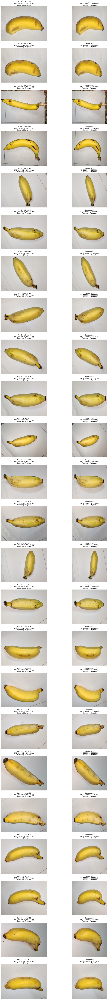

Saved visual review sheet: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/phash_distance_0_visual_pilot_24.png


In [ ]:

import os
import io
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = "/content/drive/MyDrive/Fruit_Freshness_Research"
AUDIT = f"{ROOT}/datasets/audit"

# Load candidate pairs and original manifests.
candidates = pd.read_csv(
    f"{AUDIT}/near_duplicate_candidates_phash_hamming_0_8.csv"
)

af = pd.read_csv(f"{AUDIT}/afruitdb_image_manifest.csv")
bd = pd.read_csv(f"{AUDIT}/expanded_image_manifest.csv")

# Select the first 24 distance-zero candidates.
pilot = (
    candidates[candidates["hamming_distance"] == 0]
    .head(24)
    .reset_index(drop=True)
)

# Build a lookup from each SHA-256 hash to its source and image path.
all_manifest = pd.concat(
    [
        af.assign(source="AFruitDB"),
        bd.assign(source="Bangladeshi")
    ],
    ignore_index=True
)

lookup = {}

for _, row in all_manifest.iterrows():
    lookup[(row["sha256"], row["source"])] = {
        "path": row["relative_path"],
        "fruit": row["fruit"],
        "grade": row["grade"],
    }

# Open AFruitDB nested ZIP.
outer = zipfile.ZipFile(f"{ROOT}/datasets/original/AFruitDB_original.zip")
inner_name = next(
    n for n in outer.namelist() if n.lower().endswith(".zip")
)
inner_stream = outer.open(inner_name)
af_zip = zipfile.ZipFile(inner_stream)

# Open Bangladeshi ZIP.
bd_zip = zipfile.ZipFile(
    f"{ROOT}/datasets/original/Bangladeshi_Fruit_Grade_original.zip"
)

def read_image(sha, source):
    info = lookup[(sha, source)]
    archive = af_zip if source == "AFruitDB" else bd_zip

    with archive.open(info["path"]) as f:
        image = Image.open(f).convert("RGB")
        image.load()

    return image, info

# Draw 24 pairs, 2 images per row.
fig, axes = plt.subplots(
    len(pilot), 2,
    figsize=(12, len(pilot) * 3.2)
)

for i, row in pilot.iterrows():
    a_sha = row["sha256_a"]
    b_sha = row["sha256_b"]

    source_a = row["sources_a"]
    source_b = row["sources_b"]

    # These candidates have one source per side in this pilot.
    image_a, info_a = read_image(a_sha, source_a)
    image_b, info_b = read_image(b_sha, source_b)

    axes[i, 0].imshow(image_a)
    axes[i, 0].set_title(
        f"Pair {i+1} — {source_a}\n"
        f"{os.path.basename(info_a['path'])}\n"
        f"{info_a['fruit']} | {info_a['grade']}",
        fontsize=8
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(image_b)
    axes[i, 1].set_title(
        f"{source_b}\n"
        f"{os.path.basename(info_b['path'])}\n"
        f"{info_b['fruit']} | {info_b['grade']}",
        fontsize=8
    )
    axes[i, 1].axis("off")

plt.tight_layout()

output = f"{AUDIT}/phash_distance_0_visual_pilot_24.png"
plt.savefig(output, dpi=130, bbox_inches="tight")
plt.show()

print("Saved visual review sheet:", output)

af_zip.close()
inner_stream.close()
outer.close()
bd_zip.close()


In [ ]:

import pandas as pd
from pathlib import Path

audit_dir = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit"
)

candidate_file = audit_dir / "near_duplicate_priority_review.csv"

df = pd.read_csv(candidate_file)

print("Shape:", df.shape)
print("\nActual column names:")
for col in df.columns:
    print(repr(col))

print("\nFirst 3 rows:")
display(df.head(3))


Shape: (1384, 6)

Actual column names:
'hamming_distance'
'label_relationship'
'sources_a'
'paths_a'
'sources_b'
'paths_b'

First 3 rows:


,hamming_distance,label_relationship,sources_a,paths_a,sources_b,paths_b
0,0,No same-source comparison,AFruitDB,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...,Bangladeshi,Bangladeshi: Bangladeshi Fruit Grade classific...
1,0,No same-source comparison,AFruitDB,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...,Bangladeshi,Bangladeshi: Bangladeshi Fruit Grade classific...
2,0,No same-source comparison,AFruitDB,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...,Bangladeshi,Bangladeshi: Bangladeshi Fruit Grade classific...


In [ ]:

import pandas as pd
from pathlib import Path

audit_dir = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit"
)

candidate_file = audit_dir / "near_duplicate_priority_review.csv"

output_file = (
    audit_dir / "phash_distance_0_visual_pilot_24_decisions.csv"
)

df = pd.read_csv(candidate_file)

# Select the first 24 distance-zero pairs, matching the visual pilot.
pilot = (
    df[df["hamming_distance"] == 0]
    .head(24)
    .copy()
    .reset_index(drop=True)
)

if len(pilot) != 24:
    raise ValueError(
        f"Expected 24 pairs, found {len(pilot)}. "
        "Please check the candidate file."
    )

# Preserve the original candidate information.
pilot.insert(
    0,
    "pilot_pair_id",
    [f"PILOT_{i:02d}" for i in range(1, 25)]
)

# Record the user's visual decisions.
pilot["manual_decision"] = "same_image"
pilot["reviewer"] = "user"
pilot["review_method"] = "side_by_side_visual"
pilot["review_date"] = "2026-11-19"
pilot["review_notes"] = (
    "User visually confirmed both images show the same photograph."
)

pilot.to_csv(output_file, index=False)

print("========== VISUAL PILOT AUDIT ==========")
print("Pairs reviewed:", len(pilot))
print(
    "Confirmed duplicates:",
    (pilot["manual_decision"] == "same_image").sum()
)
print("Output saved:", output_file)

display(
    pilot[
        [
            "pilot_pair_id",
            "hamming_distance",
            "sources_a",
            "sources_b",
            "manual_decision"
        ]
    ]
)


========== VISUAL PILOT AUDIT ==========
Pairs reviewed: 24
Confirmed duplicates: 24
Output saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/phash_distance_0_visual_pilot_24_decisions.csv


,pilot_pair_id,hamming_distance,sources_a,sources_b,manual_decision
0,PILOT_01,0,AFruitDB,Bangladeshi,same_image
1,PILOT_02,0,AFruitDB,Bangladeshi,same_image
2,PILOT_03,0,AFruitDB,Bangladeshi,same_image
3,PILOT_04,0,AFruitDB,Bangladeshi,same_image
4,PILOT_05,0,AFruitDB,Bangladeshi,same_image
5,PILOT_06,0,AFruitDB,Bangladeshi,same_image
6,PILOT_07,0,AFruitDB,Bangladeshi,same_image
7,PILOT_08,0,AFruitDB,Bangladeshi,same_image
8,PILOT_09,0,AFruitDB,Bangladeshi,same_image
9,PILOT_10,0,AFruitDB,Bangladeshi,same_image


In [ ]:

import pandas as pd
from pathlib import Path

audit_dir = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit"
)

manifest_file = audit_dir / "combined_image_manifest.csv"
decisions_file = audit_dir / "phash_distance_0_visual_pilot_24_decisions.csv"

manifest = pd.read_csv(manifest_file)
decisions = pd.read_csv(decisions_file)

print("========== MANIFEST STRUCTURE ==========")
print("Shape:", manifest.shape)
print("Columns:", manifest.columns.tolist())

print("\nDataset values:")
print(manifest["dataset"].value_counts(dropna=False))

print("\nExample manifest records:")
display(manifest.head(3))

print("\n========== VISUAL DECISION PATHS ==========")
display(
    decisions[
        ["pilot_pair_id", "sources_a", "paths_a", "sources_b", "paths_b"]
    ].head(3)
)


========== MANIFEST STRUCTURE ==========
Shape: (6923, 7)
Columns: ['dataset', 'filename', 'relative_path', 'fruit', 'grade', 'file_size', 'sha256']

Dataset values:
dataset
Expanded    3756
AFruitDB    3167
Name: count, dtype: int64

Example manifest records:


,dataset,filename,relative_path,fruit,grade,file_size,sha256
0,AFruitDB,IMG_20230930_172415.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1150602,3d8522b532808676afab5a21758d7b662ec187dfdad52e...
1,AFruitDB,IMG_20230930_172429.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1173056,f2a4aa7eb44d3d55da034eab8f9192a167ee501a433037...
2,AFruitDB,IMG_20230930_172432.jpg,Fruits Grade/Fruit grade/Apple/1st grade/IMG_2...,Apple,1st grade,1179042,7d142228f2983320288d16186fd406c85a8b20e3d25739...



========== VISUAL DECISION PATHS ==========


,pilot_pair_id,sources_a,paths_a,sources_b,paths_b
0,PILOT_01,AFruitDB,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...,Bangladeshi,Bangladeshi: Bangladeshi Fruit Grade classific...
1,PILOT_02,AFruitDB,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...,Bangladeshi,Bangladeshi: Bangladeshi Fruit Grade classific...
2,PILOT_03,AFruitDB,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...,Bangladeshi,Bangladeshi: Bangladeshi Fruit Grade classific...


In [ ]:

import pandas as pd
from pathlib import Path

audit_dir = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit"
)

manifest_file = audit_dir / "combined_image_manifest.csv"
decisions_file = audit_dir / "phash_distance_0_visual_pilot_24_decisions.csv"

manifest = pd.read_csv(manifest_file)
decisions = pd.read_csv(decisions_file)

# Map visual-review source names to manifest dataset names.
source_map = {
    "AFruitDB": "AFruitDB",
    "Bangladeshi": "Expanded"
}

# Build a lookup using both dataset name and relative path.
lookup = manifest.set_index(["dataset", "relative_path"])

def resolve_review_path(source, path_value):
    """Remove the source prefix and find the original manifest record."""
    source = str(source).strip()
    path_value = str(path_value).strip()

    dataset_name = source_map.get(source)

    if dataset_name is None:
        raise ValueError(f"Unknown review source: {source}")

    # Remove only the leading 'Source: ' prefix.
    prefix = source + ": "
    if path_value.startswith(prefix):
        relative_path = path_value[len(prefix):]
    else:
        relative_path = path_value

    key = (dataset_name, relative_path)

    if key not in lookup.index:
        raise KeyError(
            f"Manifest match not found:\n"
            f"Dataset: {dataset_name}\n"
            f"Path: {relative_path}"
        )

    record = lookup.loc[key]

    # A path should identify exactly one manifest record.
    if isinstance(record, pd.DataFrame):
        raise ValueError(f"Multiple manifest records found for {key}")

    return {
        "dataset": dataset_name,
        "relative_path": relative_path,
        "sha256": record["sha256"],
        "fruit": record["fruit"],
        "grade": record["grade"],
        "file_size": record["file_size"]
    }

# Resolve both images in every reviewed pair.
resolved_rows = []

for _, row in decisions.iterrows():
    a = resolve_review_path(row["sources_a"], row["paths_a"])
    b = resolve_review_path(row["sources_b"], row["paths_b"])

    resolved_rows.append({
        "pilot_pair_id": row["pilot_pair_id"],
        "manual_decision": row["manual_decision"],
        "reviewer": row["reviewer"],
        "hamming_distance": row["hamming_distance"],

        "dataset_a": a["dataset"],
        "path_a": a["relative_path"],
        "sha256_a": a["sha256"],
        "fruit_a": a["fruit"],
        "grade_a": a["grade"],

        "dataset_b": b["dataset"],
        "path_b": b["relative_path"],
        "sha256_b": b["sha256"],
        "fruit_b": b["fruit"],
        "grade_b": b["grade"],

        "same_sha256": a["sha256"] == b["sha256"],
        "same_fruit_label": a["fruit"] == b["fruit"],
        "same_grade_label": a["grade"] == b["grade"]
    })

resolved = pd.DataFrame(resolved_rows)

# Save the resolved pair-level evidence.
pair_output = audit_dir / "phash_distance_0_visual_pilot_24_resolved.csv"
resolved.to_csv(pair_output, index=False)

print("========== PAIR RESOLUTION ==========")
print("Reviewed pairs:", len(resolved))
print("AFruitDB records:", resolved["dataset_a"].eq("AFruitDB").sum())
print("Expanded records:", resolved["dataset_b"].eq("Expanded").sum())
print("SHA-identical pairs:", resolved["same_sha256"].sum())
print("Different SHA pairs:", (~resolved["same_sha256"]).sum())
print("Same fruit labels:", resolved["same_fruit_label"].sum())
print("Same grade labels:", resolved["same_grade_label"].sum())

print("\nResolved pair evidence:")
display(resolved.head(10))

print("\nSaved:", pair_output)


========== PAIR RESOLUTION ==========
Reviewed pairs: 24
AFruitDB records: 24
Expanded records: 24
SHA-identical pairs: 0
Different SHA pairs: 24
Same fruit labels: 24
Same grade labels: 24

Resolved pair evidence:


,pilot_pair_id,manual_decision,reviewer,hamming_distance,dataset_a,path_a,sha256_a,fruit_a,grade_a,dataset_b,path_b,sha256_b,fruit_b,grade_b,same_sha256,same_fruit_label,same_grade_label
0,PILOT_01,same_image,user,0,AFruitDB,Fruits Grade/Fruit grade/Banana/1st grade/IMG_...,1e325ea7a7dc0947eac9ba80e856dfa50f764e5ed4e3a3...,Banana,1st grade,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,f9a0185b8a01f8e13032cbab9bbe27202b802d8789c812...,Banana,1st grade,False,True,True
1,PILOT_02,same_image,user,0,AFruitDB,Fruits Grade/Fruit grade/Banana/1st grade/IMG_...,c81fea372aab68e1633c570b5e6885f029020765ec6d37...,Banana,1st grade,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,cf6236c237ab1511503bca90f31ddc3403f4486ebb873e...,Banana,1st grade,False,True,True
2,PILOT_03,same_image,user,0,AFruitDB,Fruits Grade/Fruit grade/Banana/1st grade/IMG_...,ced58034e8bf22895caf42f9a026abd0726c4b0d0f98f9...,Banana,1st grade,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,62bb50e1bb61ba749a3049943d0e5f4fc1f4a9180fd2df...,Banana,1st grade,False,True,True
3,PILOT_04,same_image,user,0,AFruitDB,Fruits Grade/Fruit grade/Banana/1st grade/IMG_...,6cf34c568f46d2957c0b59955ca2060bad10a0f84fc35a...,Banana,1st grade,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,8109927b335270cd7f3aaa432e29f3baea6e0a0fbc6ba5...,Banana,1st grade,False,True,True
4,PILOT_05,same_image,user,0,AFruitDB,Fruits Grade/Fruit grade/Banana/1st grade/IMG_...,6a6f96aca0242b62139c48012a671c82a4522ea262ba30...,Banana,1st grade,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,76d099f9c9fb1bdfe512d9d69a916a6a9e09ac6b258a8e...,Banana,1st grade,False,True,True
5,PILOT_06,same_image,user,0,AFruitDB,Fruits Grade/Fruit grade/Banana/1st grade/IMG_...,4ffe5fed1f0c14f1e2e9c48351f117477d1cc9e84b5185...,Banana,1st grade,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,373ad24ddd3ce7a5b6f16d4e1fe9c2ca1b44121b456cb0...,Banana,1st grade,False,True,True
6,PILOT_07,same_image,user,0,AFruitDB,Fruits Grade/Fruit grade/Banana/1st grade/IMG_...,e7b3d6da2a532fb11872440d490c9dee5d3a9b8bd4ec1b...,Banana,1st grade,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,fd4daa024ddfbd4dd64e55a41849189e6a3f59175e6244...,Banana,1st grade,False,True,True
7,PILOT_08,same_image,user,0,AFruitDB,Fruits Grade/Fruit grade/Banana/1st grade/IMG_...,0180868ef17ebc2b44e6bea1bbde84ad5b67a7fa6bc5c7...,Banana,1st grade,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,3c6b11fb6fb0efe370b83a124f010c769c4f641dd6c8aa...,Banana,1st grade,False,True,True
8,PILOT_09,same_image,user,0,AFruitDB,Fruits Grade/Fruit grade/Banana/1st grade/IMG_...,abfaff873dd71fa867f2d21fda66802b3a9d2d0752f820...,Banana,1st grade,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,b9fd991cb542ae547418e7953267e69ba8ef3e5a78346d...,Banana,1st grade,False,True,True
9,PILOT_10,same_image,user,0,AFruitDB,Fruits Grade/Fruit grade/Banana/1st grade/IMG_...,fb9cc5502ab820d5d065c8b2625337291be8c9f78b804e...,Banana,1st grade,Expanded,Bangladeshi Fruit Grade classification/Fruit g...,bd2ec5bf1abcbd9e19339b39893c62ec7825279814637e...,Banana,1st grade,False,True,True



Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/phash_distance_0_visual_pilot_24_resolved.csv


In [ ]:

import pandas as pd
from pathlib import Path
from collections import defaultdict

# ---------------------------------------------------------
# 1. File locations
# ---------------------------------------------------------
BASE = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
AUDIT = BASE / "datasets" / "audit"

manifest_file = AUDIT / "combined_image_manifest.csv"
review_file = AUDIT / "phash_distance_0_visual_pilot_24_resolved.csv"

# ---------------------------------------------------------
# 2. Load evidence
# ---------------------------------------------------------
manifest = pd.read_csv(manifest_file, dtype=str).fillna("")
review = pd.read_csv(review_file, dtype=str).fillna("")

required_manifest = {
    "dataset", "relative_path", "sha256", "fruit", "grade"
}
required_review = {
    "pilot_pair_id", "manual_decision",
    "sha256_a", "sha256_b",
    "fruit_a", "grade_a", "fruit_b", "grade_b"
}

assert required_manifest.issubset(manifest.columns), (
    f"Missing manifest columns: {required_manifest - set(manifest.columns)}"
)
assert required_review.issubset(review.columns), (
    f"Missing review columns: {required_review - set(review.columns)}"
)

# Only use pairs explicitly adjudicated as same_image.
confirmed = review[
    review["manual_decision"].str.strip().str.lower() == "same_image"
].copy()

print("Manifest records:", len(manifest))
print("Reviewed pairs:", len(review))
print("Confirmed same-image pairs:", len(confirmed))

# ---------------------------------------------------------
# 3. Union-find: merge SHA-256 hashes linked by reviewed pairs
# ---------------------------------------------------------
parent = {}

def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    root_a = find(a)
    root_b = find(b)
    if root_a != root_b:
        # Deterministic root selection
        low, high = sorted([root_a, root_b])
        parent[high] = low

for _, row in confirmed.iterrows():
    a = row["sha256_a"].strip()
    b = row["sha256_b"].strip()

    if not a or not b:
        raise ValueError(f"Missing SHA-256 in {row['pilot_pair_id']}")

    union(a, b)

# ---------------------------------------------------------
# 4. Build connected components
# ---------------------------------------------------------
components = defaultdict(set)

for sha in list(parent):
    components[find(sha)].add(sha)

# Map each SHA to its component
sha_to_component = {}

for root, hashes in components.items():
    for sha in hashes:
        sha_to_component[sha] = root

# Count how often each SHA occurs in the full manifest.
# This captures exact duplicates shared across dataset sources.
sha_record_counts = manifest["sha256"].value_counts().to_dict()

# A group is retained if it contains:
# - more than one distinct SHA linked by visual review, OR
# - repeated manifest records with the same exact SHA.
group_roots = set()

for root, hashes in components.items():
    if (
        len(hashes) > 1
        or any(sha_record_counts.get(h, 0) > 1 for h in hashes)
    ):
        group_roots.add(root)

# Stable group IDs based on the lexicographically smallest SHA.
root_to_group = {}

for root in group_roots:
    group_key = min(components[root])
    root_to_group[root] = "DUP_" + group_key[:12].upper()

# Also identify exact-SHA duplicates that were not part of a reviewed pair.
for sha, count in sha_record_counts.items():
    if count > 1 and sha not in sha_to_component:
        root_to_group[sha] = "DUP_" + sha[:12].upper()

def get_group_id(sha):
    if sha in sha_to_component:
        return root_to_group.get(sha_to_component[sha], "")
    return root_to_group.get(sha, "")

# ---------------------------------------------------------
# 5. Create image-level grouped manifest
# ---------------------------------------------------------
grouped = manifest.copy()
grouped["duplicate_group_id"] = grouped["sha256"].map(get_group_id)

grouped_file = AUDIT / "visual_pilot_24_duplicate_group_manifest.csv"
grouped.to_csv(grouped_file, index=False)

# ---------------------------------------------------------
# 6. Create group-level summary and label-conflict checks
# ---------------------------------------------------------
grouped_rows = grouped[grouped["duplicate_group_id"] != ""].copy()

summary_rows = []

for group_id, g in grouped_rows.groupby("duplicate_group_id"):
    hashes = sorted(g["sha256"].unique())
    fruits = sorted(x for x in g["fruit"].unique() if x)
    grades = sorted(x for x in g["grade"].unique() if x)
    sources = sorted(x for x in g["dataset"].unique() if x)

    summary_rows.append({
        "duplicate_group_id": group_id,
        "manifest_records": len(g),
        "distinct_sha256": len(hashes),
        "datasets": "; ".join(sources),
        "fruit_labels": "; ".join(fruits),
        "grade_labels": "; ".join(grades),
        "fruit_label_conflict": len(fruits) > 1,
        "grade_label_conflict": len(grades) > 1,
        "sha256_members": "; ".join(hashes),
        "paths": " || ".join(
            f"{r.dataset}: {r.relative_path}"
            for r in g.itertuples()
        )
    })

summary = pd.DataFrame(summary_rows)

summary_file = AUDIT / "visual_pilot_24_duplicate_group_summary.csv"
summary.to_csv(summary_file, index=False)

# ---------------------------------------------------------
# 7. Add group IDs to the reviewed pair evidence
# ---------------------------------------------------------
pair_rows = []

for _, row in confirmed.iterrows():
    a = row["sha256_a"].strip()
    b = row["sha256_b"].strip()

    pair_rows.append({
        "pilot_pair_id": row["pilot_pair_id"],
        "hamming_distance": row.get("hamming_distance", ""),
        "manual_decision": row["manual_decision"],
        "sha256_a": a,
        "sha256_b": b,
        "duplicate_group_id": get_group_id(a),
        "same_group": get_group_id(a) == get_group_id(b),
        "same_fruit_label": row["fruit_a"] == row["fruit_b"],
        "same_grade_label": row["grade_a"] == row["grade_b"]
    })

pair_evidence = pd.DataFrame(pair_rows)

pair_file = AUDIT / "visual_pilot_24_pair_group_evidence.csv"
pair_evidence.to_csv(pair_file, index=False)

# ---------------------------------------------------------
# 8. Validation and report
# ---------------------------------------------------------
print("\n========== DUPLICATE GROUP AUDIT ==========")
print("Confirmed visual pairs:", len(confirmed))
print("Distinct SHA hashes in confirmed pairs:",
      len(set(confirmed["sha256_a"]) | set(confirmed["sha256_b"])))
print("Connected components from visual pairs:", len(components))
print("Duplicate groups in output:", len(summary))
print("Manifest records assigned to groups:", len(grouped_rows))

print("\nPair-to-group validation:")
print("Pairs assigned to same group:",
      int(pair_evidence["same_group"].sum()), "/", len(pair_evidence))

print("\nLabel-conflict validation:")
if len(summary):
    print("Groups with fruit conflicts:",
          int(summary["fruit_label_conflict"].sum()))
    print("Groups with grade conflicts:",
          int(summary["grade_label_conflict"].sum()))
else:
    print("No duplicate groups were generated.")

print("\nGroup-size distribution (distinct SHA hashes):")
if len(summary):
    print(summary["distinct_sha256"].value_counts().sort_index())

print("\nGroup summary preview:")
display(summary.head(15))

print("\nSaved files:")
print(grouped_file)
print(summary_file)
print(pair_file)


Manifest records: 6923
Reviewed pairs: 24
Confirmed same-image pairs: 24

========== DUPLICATE GROUP AUDIT ==========
Confirmed visual pairs: 24
Distinct SHA hashes in confirmed pairs: 48
Connected components from visual pairs: 24
Duplicate groups in output: 2073
Manifest records assigned to groups: 4152

Pair-to-group validation:
Pairs assigned to same group: 24 / 24

Label-conflict validation:
Groups with fruit conflicts: 0
Groups with grade conflicts: 3

Group-size distribution (distinct SHA hashes):
distinct_sha256
1    2049
2      24
Name: count, dtype: int64

Group summary preview:


,duplicate_group_id,manifest_records,distinct_sha256,datasets,fruit_labels,grade_labels,fruit_label_conflict,grade_label_conflict,sha256_members,paths
0,DUP_007540C3F1DF,2,1,AFruitDB; Expanded,Tomatoes,3rd grade,False,False,007540c3f1df426c2bc2ff3dc223d226c58f59291cba36...,AFruitDB: Fruits Grade/Fruit grade/Tomatoes/3r...
1,DUP_00B7D457AC5F,2,1,AFruitDB; Expanded,Mango,2nd grade,False,False,00b7d457ac5f117586527541efb23800f31608b43abc04...,AFruitDB: Fruits Grade/Fruit grade/Mango/2nd g...
2,DUP_00C7D72CB0DC,2,1,AFruitDB; Expanded,Tomatoes,1st grade,False,False,00c7d72cb0dc7ba15aa2554a559fa1ad8fe4c740a7e119...,AFruitDB: Fruits Grade/Fruit grade/Tomatoes/1s...
3,DUP_00DEB664E024,2,1,AFruitDB; Expanded,Mango,2nd grade,False,False,00deb664e02420842b070a3163d77d9044f28dd142e410...,AFruitDB: Fruits Grade/Fruit grade/Mango/2nd g...
4,DUP_00F93D6C1B5D,2,1,AFruitDB; Expanded,Mango,1st grade,False,False,00f93d6c1b5da31c978f25c9592c76f3846a9421f426c6...,AFruitDB: Fruits Grade/Fruit grade/Mango/1st g...
5,DUP_013E939DD1F5,2,1,AFruitDB; Expanded,Apple,2nd grade,False,False,013e939dd1f541e10483dbe0999cd760cad478811447c4...,AFruitDB: Fruits Grade/Fruit grade/Apple/2nd g...
6,DUP_0146F0EC1930,2,1,AFruitDB; Expanded,Apple,2nd grade,False,False,0146f0ec19305d9f9d25bd5aa1c513bcfc6b5302442c03...,AFruitDB: Fruits Grade/Fruit grade/Apple/2nd g...
7,DUP_017913AB014C,2,1,AFruitDB; Expanded,Tomatoes,1st grade,False,False,017913ab014cf000e421894e21716ed1569b7e835e18c9...,AFruitDB: Fruits Grade/Fruit grade/Tomatoes/1s...
8,DUP_0180868EF17E,2,2,AFruitDB; Expanded,Banana,1st grade,False,False,0180868ef17ebc2b44e6bea1bbde84ad5b67a7fa6bc5c7...,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...
9,DUP_01881634676E,2,1,AFruitDB; Expanded,Mango,2nd grade,False,False,01881634676e6a8d32c53d55c50df885a6e1373e5b8f0f...,AFruitDB: Fruits Grade/Fruit grade/Mango/2nd g...



Saved files:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/visual_pilot_24_duplicate_group_manifest.csv
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/visual_pilot_24_duplicate_group_summary.csv
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/visual_pilot_24_pair_group_evidence.csv


In [ ]:

import pandas as pd
from pathlib import Path

AUDIT = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit"
)

summary = pd.read_csv(
    AUDIT / "visual_pilot_24_duplicate_group_summary.csv"
)

grouped = pd.read_csv(
    AUDIT / "visual_pilot_24_duplicate_group_manifest.csv"
)

pairs = pd.read_csv(
    AUDIT / "visual_pilot_24_pair_group_evidence.csv"
)

# Inspect all groups with conflicting labels
conflicts = summary[
    summary["fruit_label_conflict"]
    | summary["grade_label_conflict"]
].copy()

print("========== CONFLICT AUDIT ==========")
print("Total conflict groups:", len(conflicts))

if len(conflicts):
    display(conflicts[
        [
            "duplicate_group_id",
            "manifest_records",
            "distinct_sha256",
            "fruit_labels",
            "grade_labels",
            "fruit_label_conflict",
            "grade_label_conflict",
            "paths"
        ]
    ])

# Inspect all records belonging to conflicting groups
conflict_ids = set(conflicts["duplicate_group_id"])

conflict_records = grouped[
    grouped["duplicate_group_id"].isin(conflict_ids)
]

print("\nConflict-group manifest records:", len(conflict_records))
display(conflict_records[
    ["dataset", "fruit", "grade", "sha256",
     "relative_path", "duplicate_group_id"]
])

# Group accounting
print("\n========== GROUP ACCOUNTING ==========")
print("Total manifest records:", len(grouped))
print("Records assigned to groups:",
      (grouped["duplicate_group_id"] != "").sum())
print("Unassigned records:",
      (grouped["duplicate_group_id"] == "").sum())
print("Total group IDs:", summary["duplicate_group_id"].nunique())
print("Groups with one SHA:",
      (summary["distinct_sha256"] == 1).sum())
print("Groups with two SHAs:",
      (summary["distinct_sha256"] == 2).sum())
print("Groups with more than two SHAs:",
      (summary["distinct_sha256"] > 2).sum())

print("\n========== VISUAL PAIR VALIDATION ==========")
print("Reviewed pairs:", len(pairs))
print("Pairs sharing a group:",
      int(pairs["same_group"].sum()))
print("Pairs with label mismatch:",
      int((~pairs["same_fruit_label"]).sum()
          + (~pairs["same_grade_label"]).sum()))


========== CONFLICT AUDIT ==========
Total conflict groups: 3


,duplicate_group_id,manifest_records,distinct_sha256,fruit_labels,grade_labels,fruit_label_conflict,grade_label_conflict,paths
698,DUP_584F61149197,4,1,Mango,1st grade; 2nd grade,False,True,AFruitDB: Fruits Grade/Fruit grade/Mango/1st g...
1078,DUP_8523098A18C6,4,1,Mango,1st grade; 2nd grade,False,True,AFruitDB: Fruits Grade/Fruit grade/Mango/1st g...
1611,DUP_C8F588220A00,4,1,Mango,1st grade; 2nd grade,False,True,AFruitDB: Fruits Grade/Fruit grade/Mango/1st g...



Conflict-group manifest records: 12


,dataset,fruit,grade,sha256,relative_path,duplicate_group_id
1838,AFruitDB,Mango,1st grade,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,DUP_C8F588220A00
1839,AFruitDB,Mango,1st grade,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,DUP_584F61149197
1840,AFruitDB,Mango,1st grade,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,Fruits Grade/Fruit grade/Mango/1st grade/IMG_2...,DUP_8523098A18C6
2016,AFruitDB,Mango,2nd grade,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,DUP_C8F588220A00
2017,AFruitDB,Mango,2nd grade,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,DUP_584F61149197
2018,AFruitDB,Mango,2nd grade,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,Fruits Grade/Fruit grade/Mango/2nd grade/IMG_2...,DUP_8523098A18C6
5599,Expanded,Mango,1st grade,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,Bangladeshi Fruit Grade classification/Fruit g...,DUP_C8F588220A00
5600,Expanded,Mango,1st grade,584f6114919733e6b4ef13d2b4c1caf569ade6e442a878...,Bangladeshi Fruit Grade classification/Fruit g...,DUP_584F61149197
5601,Expanded,Mango,1st grade,8523098a18c6f31158d7029091cc4db33d9ffd324aca5a...,Bangladeshi Fruit Grade classification/Fruit g...,DUP_8523098A18C6
5775,Expanded,Mango,2nd grade,c8f588220a005f12bc213975c70d8318cd02b8a95a4a18...,Bangladeshi Fruit Grade classification/Fruit g...,DUP_C8F588220A00



========== GROUP ACCOUNTING ==========
Total manifest records: 6923
Records assigned to groups: 6923
Unassigned records: 0
Total group IDs: 2073
Groups with one SHA: 2049
Groups with two SHAs: 24
Groups with more than two SHAs: 0

========== VISUAL PAIR VALIDATION ==========
Reviewed pairs: 24
Pairs sharing a group: 24
Pairs with label mismatch: 0


In [ ]:

import pandas as pd
from pathlib import Path

AUDIT = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit"
)

candidate_file = (
    AUDIT / "near_duplicate_candidates_phash_hamming_0_8.csv"
)

candidates = pd.read_csv(candidate_file)

print("Rows:", len(candidates))
print("\nColumns:")
print(candidates.columns.tolist())

print("\nDistance distribution:")
print(candidates["hamming_distance"].value_counts().sort_index())

print("\nFirst five candidate records:")
display(candidates.head())

print("\nMissing values:")
display(candidates.isna().sum())


Rows: 4256

Columns:
['sha256_a', 'sha256_b', 'hamming_distance', 'sources_a', 'sources_b', 'paths_a', 'paths_b', 'cross_dataset_possible', 'common_sources', 'label_comparisons']

Distance distribution:
hamming_distance
0    1000
2     176
4     208
6     642
8    2230
Name: count, dtype: int64

First five candidate records:


,sha256_a,sha256_b,hamming_distance,sources_a,sources_b,paths_a,paths_b,cross_dataset_possible,common_sources,label_comparisons
0,1e325ea7a7dc0947eac9ba80e856dfa50f764e5ed4e3a3...,f9a0185b8a01f8e13032cbab9bbe27202b802d8789c812...,0,AFruitDB,Bangladeshi,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...,Bangladeshi: Bangladeshi Fruit Grade classific...,True,NaN,[]
1,c81fea372aab68e1633c570b5e6885f029020765ec6d37...,cf6236c237ab1511503bca90f31ddc3403f4486ebb873e...,0,AFruitDB,Bangladeshi,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...,Bangladeshi: Bangladeshi Fruit Grade classific...,True,NaN,[]
2,ced58034e8bf22895caf42f9a026abd0726c4b0d0f98f9...,62bb50e1bb61ba749a3049943d0e5f4fc1f4a9180fd2df...,0,AFruitDB,Bangladeshi,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...,Bangladeshi: Bangladeshi Fruit Grade classific...,True,NaN,[]
3,6cf34c568f46d2957c0b59955ca2060bad10a0f84fc35a...,8109927b335270cd7f3aaa432e29f3baea6e0a0fbc6ba5...,0,AFruitDB,Bangladeshi,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...,Bangladeshi: Bangladeshi Fruit Grade classific...,True,NaN,[]
4,6a6f96aca0242b62139c48012a671c82a4522ea262ba30...,76d099f9c9fb1bdfe512d9d69a916a6a9e09ac6b258a8e...,0,AFruitDB,Bangladeshi,AFruitDB: Fruits Grade/Fruit grade/Banana/1st ...,Bangladeshi: Bangladeshi Fruit Grade classific...,True,NaN,[]



Missing values:


,0
sha256_a,0
sha256_b,0
hamming_distance,0
sources_a,0
sources_b,0
paths_a,0
paths_b,0
cross_dataset_possible,0
common_sources,2133
label_comparisons,0


In [ ]:

import pandas as pd
import json
from pathlib import Path

AUDIT = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit"
)

manifest = pd.read_csv(
    AUDIT / "combined_image_manifest.csv",
    dtype=str
).fillna("")

candidates = pd.read_csv(
    AUDIT / "near_duplicate_candidates_phash_hamming_0_8.csv",
    dtype={"sha256_a": str, "sha256_b": str}
).fillna("")

# Build metadata lookup using every manifest record for each SHA.
metadata = {}

for sha, group in manifest.groupby("sha256"):
    metadata[sha] = {
        "datasets": sorted(group["dataset"].unique().tolist()),
        "fruits": sorted(set(x for x in group["fruit"] if x)),
        "grades": sorted(set(x for x in group["grade"] if x)),
        "labels": sorted(set(
            (r.fruit, r.grade)
            for r in group[["fruit", "grade"]].itertuples(index=False)
            if r.fruit and r.grade
        ))
    }

def compare_pair(row):
    a = metadata.get(row["sha256_a"])
    b = metadata.get(row["sha256_b"])

    if a is None or b is None:
        return pd.Series({
            "metadata_found": False,
            "source_relation": "metadata_missing",
            "fruit_relation": "unknown",
            "grade_relation": "unknown",
            "label_relation": "unknown",
            "labels_a": "",
            "labels_b": "",
            "datasets_a": "",
            "datasets_b": ""
        })

    fruits_a, fruits_b = set(a["fruits"]), set(b["fruits"])
    grades_a, grades_b = set(a["grades"]), set(b["grades"])
    labels_a, labels_b = set(a["labels"]), set(b["labels"])

    # Compare every possible label combination.
    fruit_match = bool(fruits_a & fruits_b)
    grade_match = bool(grades_a & grades_b)

    if not fruits_a or not fruits_b:
        fruit_relation = "unknown"
    elif fruits_a == fruits_b:
        fruit_relation = "same"
    elif not fruit_match:
        fruit_relation = "conflict"
    else:
        fruit_relation = "mixed"

    if not grades_a or not grades_b:
        grade_relation = "unknown"
    elif grades_a == grades_b:
        grade_relation = "same"
    elif not grade_match:
        grade_relation = "conflict"
    else:
        grade_relation = "mixed"

    if not labels_a or not labels_b:
        label_relation = "unknown"
    elif labels_a == labels_b:
        label_relation = "same"
    elif not (labels_a & labels_b):
        label_relation = "conflict"
    else:
        label_relation = "mixed"

    if set(a["datasets"]) & set(b["datasets"]):
        source_relation = "same_source_possible"
    else:
        source_relation = "cross_source_only"

    return pd.Series({
        "metadata_found": True,
        "source_relation": source_relation,
        "fruit_relation": fruit_relation,
        "grade_relation": grade_relation,
        "label_relation": label_relation,
        "labels_a": json.dumps(a["labels"]),
        "labels_b": json.dumps(b["labels"]),
        "datasets_a": ";".join(a["datasets"]),
        "datasets_b": ";".join(b["datasets"])
    })

enriched = pd.concat(
    [candidates, candidates.apply(compare_pair, axis=1)],
    axis=1
)

output = AUDIT / "near_duplicate_candidates_with_corrected_labels.csv"
enriched.to_csv(output, index=False)

print("========== CORRECTED LABEL AUDIT ==========")
print("Candidate pairs:", len(enriched))
print("Missing metadata:", int((~enriched["metadata_found"]).sum()))

for column in [
    "source_relation",
    "fruit_relation",
    "grade_relation",
    "label_relation"
]:
    print(f"\n{column}:")
    print(enriched[column].value_counts(dropna=False))

print("\nSaved:", output)


========== CORRECTED LABEL AUDIT ==========
Candidate pairs: 4256
Missing metadata: 0

source_relation:
source_relation
cross_source_only       2133
same_source_possible    2123
Name: count, dtype: int64

fruit_relation:
fruit_relation
same        3952
conflict     304
Name: count, dtype: int64

grade_relation:
grade_relation
same        3022
conflict    1234
Name: count, dtype: int64

label_relation:
label_relation
same        2907
conflict    1349
Name: count, dtype: int64

Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/near_duplicate_candidates_with_corrected_labels.csv


In [ ]:

import pandas as pd
from pathlib import Path

AUDIT = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit"
)

enriched = pd.read_csv(
    AUDIT / "near_duplicate_candidates_with_corrected_labels.csv",
    dtype=str
).fillna("")

reviewed = pd.read_csv(
    AUDIT / "phash_distance_0_visual_pilot_24_resolved.csv",
    dtype=str
).fillna("")

# Canonical pair key: order does not matter.
def pair_key(a, b):
    return tuple(sorted([a, b]))

already_reviewed = {
    pair_key(row.sha256_a, row.sha256_b)
    for row in reviewed.itertuples()
}

enriched["pair_key"] = enriched.apply(
    lambda r: pair_key(r["sha256_a"], r["sha256_b"]),
    axis=1
)

remaining = enriched[
    ~enriched["pair_key"].isin(already_reviewed)
].copy()

# Fixed sample targets per distance.
targets = {
    0: 40,
    2: 30,
    4: 30,
    6: 40,
    8: 40
}

sample_parts = []

for distance, target in targets.items():
    pool = remaining[
        pd.to_numeric(
            remaining["hamming_distance"],
            errors="coerce"
        ) == distance
    ]

    n = min(target, len(pool))

    selected = pool.sample(
        n=n,
        random_state=20261119 + distance
    ).copy()

    sample_parts.append(selected)

sample = pd.concat(sample_parts, ignore_index=True)

# Stable review IDs
sample.insert(
    0,
    "review_pair_id",
    [f"REVIEW_{i:03d}" for i in range(1, len(sample) + 1)]
)

# Blank decision fields for manual review
sample["manual_decision"] = ""
sample["reviewer"] = ""
sample["review_date"] = ""
sample["review_notes"] = ""

# Save full evidence and a smaller review sheet.
full_file = AUDIT / "near_duplicate_visual_review_sample_180.csv"

review_columns = [
    "review_pair_id",
    "hamming_distance",
    "source_relation",
    "fruit_relation",
    "grade_relation",
    "label_relation",
    "datasets_a",
    "datasets_b",
    "paths_a",
    "paths_b",
    "sha256_a",
    "sha256_b",
    "manual_decision",
    "reviewer",
    "review_date",
    "review_notes"
]

review_file = AUDIT / "near_duplicate_visual_review_sheet_180.csv"

sample.to_csv(full_file, index=False)
sample[review_columns].to_csv(review_file, index=False)

print("========== VISUAL REVIEW SAMPLE ==========")
print("Previously reviewed pairs excluded:", len(already_reviewed))
print("Remaining candidates:", len(remaining))
print("New sample size:", len(sample))

print("\nSample count by distance:")
print(
    sample["hamming_distance"]
    .value_counts()
    .sort_index()
)

print("\nSample count by label relationship:")
print(sample["label_relation"].value_counts())

print("\nSample count by source relationship:")
print(sample["source_relation"].value_counts())

print("\nSaved full evidence:", full_file)
print("Saved review sheet:", review_file)


========== VISUAL REVIEW SAMPLE ==========
Previously reviewed pairs excluded: 24
Remaining candidates: 4232
New sample size: 180

Sample count by distance:
hamming_distance
0    40
2    30
4    30
6    40
8    40
Name: count, dtype: int64

Sample count by label relationship:
label_relation
same        132
conflict     48
Name: count, dtype: int64

Sample count by source relationship:
source_relation
cross_source_only       95
same_source_possible    85
Name: count, dtype: int64

Saved full evidence: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/near_duplicate_visual_review_sample_180.csv
Saved review sheet: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/near_duplicate_visual_review_sheet_180.csv


In [ ]:
import pandas as pd
from pathlib import Path

audit = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit"
)

df = pd.read_csv(
    audit / "near_duplicate_visual_review_sheet_180.csv"
)

# Put conflicting labels first, then lowest pHash distance.
df["distance_num"] = pd.to_numeric(df["hamming_distance"])

df["priority"] = (
    (df["label_relation"] == "conflict").astype(int) * -1
)

df = df.sort_values(
    ["priority", "distance_num"],
    ascending=[True, True]
).drop(columns=["priority", "distance_num"])

df.to_csv(
    audit / "near_duplicate_visual_review_sheet_prioritized.csv",
    index=False
)

print("Prioritized review sheet saved.")
print(df.groupby(["label_relation", "hamming_distance"]).size())

Prioritized review sheet saved.
label_relation  hamming_distance
conflict        2                    4
                4                   11
                6                   18
                8                   15
same            0                   40
                2                   26
                4                   19
                6                   22
                8                   25
dtype: int64


In [ ]:
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

original_dir = BASE / "datasets" / "original"

print("Original directory exists:", original_dir.exists())
print("\nZIP files found:")

for p in original_dir.glob("*.zip"):
    print(f"{p.name}  |  {p.stat().st_size / (1024**3):.2f} GB")

Original directory exists: True

ZIP files found:
Bangladeshi_Fruit_Grade_original.zip  |  2.54 GB
AFruitDB_original.zip  |  2.93 GB


In [ ]:
import zipfile

zip_files = list(original_dir.glob("*.zip"))

bangla_matches = [
    p for p in zip_files
    if "bangladeshi" in p.name.lower()
    or "fruit_grade" in p.name.lower()
]

if len(bangla_matches) != 1:
    print("Could not identify exactly one Bangladeshi archive.")
    print("Matching files:", [p.name for p in bangla_matches])
else:
    expanded_zip = zipfile.ZipFile(bangla_matches[0])
    print("Successfully opened:", bangla_matches[0].name)
    print("Archive integrity:", expanded_zip.testzip())

Successfully opened: Bangladeshi_Fruit_Grade_original.zip
Archive integrity: None


In [ ]:
from pathlib import Path
import zipfile

BASE = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
original_dir = BASE / "datasets" / "original"

bangla_path = original_dir / "Bangladeshi_Fruit_Grade_original.zip"
afruit_path = original_dir / "AFruitDB_original.zip"

for p in [bangla_path, afruit_path]:
    print(p.name, "exists:", p.exists())

# Open the Bangladeshi archive
bangla_zip = zipfile.ZipFile(bangla_path)
print("\nBangladeshi archive check:", bangla_zip.testzip())

# Locate the nested AFruitDB archive
afruit_outer = zipfile.ZipFile(afruit_path)
nested_matches = [
    name for name in afruit_outer.namelist()
    if name.lower().endswith("fruits grade.zip")
]

print("\nNested AFruitDB ZIP matches:")
for name in nested_matches:
    print(name)

assert len(nested_matches) == 1, (
    "Expected exactly one nested Fruits Grade.zip archive."
)

print("\nBoth archives are ready for the contact-sheet step.")

Bangladeshi_Fruit_Grade_original.zip exists: True
AFruitDB_original.zip exists: True

Bangladeshi archive check: None

Nested AFruitDB ZIP matches:
A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip

Both archives are ready for the contact-sheet step.


In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
audit_dir = BASE / "datasets" / "audit"

review_file = audit_dir / "near_duplicate_visual_review_sheet_prioritized.csv"

assert review_file.exists(), f"Review file not found: {review_file}"

review_df = pd.read_csv(review_file)

print("Review file:", review_file.name)
print("Total candidate pairs:", len(review_df))
print("\nColumns:")
print(review_df.columns.tolist())

# Select candidate pairs with conflicting labels
conflicts = review_df[
    review_df["label_relation"].astype(str).str.lower() == "conflict"
].copy()

print("\nConflicting-label pairs:", len(conflicts))
print("\nDistance distribution:")
print(conflicts["hamming_distance"].value_counts().sort_index())

print("\nFirst candidate record:")
display(conflicts.head(1).T)

Review file: near_duplicate_visual_review_sheet_prioritized.csv
Total candidate pairs: 180

Columns:
['review_pair_id', 'hamming_distance', 'source_relation', 'fruit_relation', 'grade_relation', 'label_relation', 'datasets_a', 'datasets_b', 'paths_a', 'paths_b', 'sha256_a', 'sha256_b', 'manual_decision', 'reviewer', 'review_date', 'review_notes']

Conflicting-label pairs: 48

Distance distribution:
hamming_distance
2     4
4    11
6    18
8    15
Name: count, dtype: int64

First candidate record:


,0
review_pair_id,REVIEW_047
hamming_distance,2
source_relation,same_source_possible
fruit_relation,same
grade_relation,conflict
label_relation,conflict
datasets_a,Expanded
datasets_b,Expanded
paths_a,Bangladeshi: Bangladeshi Fruit Grade classific...
paths_b,Bangladeshi: Bangladeshi Fruit Grade classific...


In [ ]:

from pathlib import Path
from io import BytesIO
import zipfile
import pandas as pd
from PIL import Image, ImageDraw, ImageFont, ImageOps
import math
import re

# --------------------------------------------------
# 1. File locations
# --------------------------------------------------
BASE = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
original_dir = BASE / "datasets" / "original"
audit_dir = BASE / "datasets" / "audit"

bangla_path = original_dir / "Bangladeshi_Fruit_Grade_original.zip"
afruit_path = original_dir / "AFruitDB_original.zip"

review_path = audit_dir / "near_duplicate_visual_review_sheet_prioritized.csv"
output_dir = audit_dir / "label_conflict_contact_sheets"
output_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Load the 48 conflicting-label pairs
# --------------------------------------------------
review_df = pd.read_csv(review_path)

conflicts = review_df[
    review_df["label_relation"].astype(str).str.lower() == "conflict"
].copy()

conflicts = conflicts.reset_index(drop=True)

assert len(conflicts) == 48, (
    f"Expected 48 conflicting pairs, found {len(conflicts)}"
)

# --------------------------------------------------
# 3. Open the original ZIP archives
# --------------------------------------------------
bangla_zip = zipfile.ZipFile(bangla_path)
afruit_outer = zipfile.ZipFile(afruit_path)

nested_matches = [
    name for name in afruit_outer.namelist()
    if name.lower().endswith("fruits grade.zip")
]

assert len(nested_matches) == 1, (
    f"Expected one nested AFruitDB ZIP, found {len(nested_matches)}"
)

# Open nested AFruitDB ZIP in memory
nested_bytes = afruit_outer.read(nested_matches[0])
afruit_zip = zipfile.ZipFile(BytesIO(nested_bytes))

print("Bangladeshi ZIP opened:", bangla_path.name)
print("AFruitDB nested ZIP opened:", nested_matches[0])

# --------------------------------------------------
# 4. Build ZIP filename indexes
# --------------------------------------------------
def normalise_path(value):
    value = str(value).replace("\\", "/").strip()
    return re.sub(r"/+", "/", value).lstrip("/")

bangla_members = {
    normalise_path(name): name
    for name in bangla_zip.namelist()
    if not name.endswith("/")
}

afruit_members = {
    normalise_path(name): name
    for name in afruit_zip.namelist()
    if not name.endswith("/")
}

def get_source_and_path(value):
    """
    Expected path format:
    Bangladeshi: folder/image.jpg
    AFruitDB: folder/image.jpg
    """
    value = str(value).strip()

    if ": " not in value:
        raise ValueError(f"Unrecognised path format: {value}")

    source, relative_path = value.split(": ", 1)
    source = source.strip().lower()
    relative_path = normalise_path(relative_path)

    if "bangladeshi" in source or source == "expanded":
        # Expanded records in this review file use the
        # Bangladeshi archive as their image source.
        return "Bangladeshi", relative_path

    if "afruitdb" in source:
        return "AFruitDB", relative_path

    raise ValueError(f"Unknown image source prefix: {source}")

def resolve_member(zip_members, relative_path):
    """
    Try an exact path match first. If the path has an
    extra leading folder, try a unique suffix match.
    """
    path = normalise_path(relative_path)

    if path in zip_members:
        return zip_members[path]

    suffix_matches = [
        original_name
        for normalised_name, original_name in zip_members.items()
        if normalised_name.endswith("/" + path)
        or normalised_name == path
    ]

    if len(suffix_matches) == 1:
        return suffix_matches[0]

    if len(suffix_matches) == 0:
        raise FileNotFoundError(
            f"No ZIP member found for: {relative_path}"
        )

    raise ValueError(
        f"Ambiguous ZIP path ({len(suffix_matches)} matches): "
        f"{relative_path}"
    )

def load_image(path_value):
    source, relative_path = get_source_and_path(path_value)

    if source == "Bangladeshi":
        archive = bangla_zip
        members = bangla_members
    else:
        archive = afruit_zip
        members = afruit_members

    member_name = resolve_member(members, relative_path)

    with archive.open(member_name) as f:
        image = Image.open(f)
        image.load()
        return ImageOps.exif_transpose(image).convert("RGB")

# --------------------------------------------------
# 5. Prepare image and text formatting
# --------------------------------------------------
FONT = ImageFont.load_default()

THUMB_W = 300
THUMB_H = 205
PAIR_W = THUMB_W * 2 + 24
PAIR_H = 270

SHEET_COLS = 4
SHEET_ROWS = 3
PAIRS_PER_SHEET = SHEET_COLS * SHEET_ROWS

def fit_image(image):
    return ImageOps.contain(
        image,
        (THUMB_W, THUMB_H)
    )

def draw_pair(draw, canvas, row, x, y):
    pair_id = str(row["review_pair_id"])
    distance = row["hamming_distance"]

    # Load both images
    image_a = load_image(row["paths_a"])
    image_b = load_image(row["paths_b"])

    image_a = fit_image(image_a)
    image_b = fit_image(image_b)

    # Pair heading
    heading = f"{pair_id} | pHash distance: {distance}"
    draw.text((x, y), heading, fill="black", font=FONT)

    image_y = y + 25

    # Place each image in its own fixed-size area
    box_a = Image.new("RGB", (THUMB_W, THUMB_H), "white")
    box_b = Image.new("RGB", (THUMB_W, THUMB_H), "white")

    box_a.paste(
        image_a,
        ((THUMB_W - image_a.width) // 2,
         (THUMB_H - image_a.height) // 2)
    )
    box_b.paste(
        image_b,
        ((THUMB_W - image_b.width) // 2,
         (THUMB_H - image_b.height) // 2)
    )

    canvas.paste(box_a, (x, image_y))
    canvas.paste(box_b, (x + THUMB_W + 12, image_y))

    draw.text((x, image_y + THUMB_H + 5), "Image A", fill="black")
    draw.text(
        (x + THUMB_W + 12, image_y + THUMB_H + 5),
        "Image B",
        fill="black"
    )

# --------------------------------------------------
# 6. Generate four contact sheets
# --------------------------------------------------
errors = []

for sheet_number in range(math.ceil(len(conflicts) / PAIRS_PER_SHEET)):
    start = sheet_number * PAIRS_PER_SHEET
    end = min(start + PAIRS_PER_SHEET, len(conflicts))
    sheet_rows = conflicts.iloc[start:end]

    sheet_width = SHEET_COLS * PAIR_W
    sheet_height = SHEET_ROWS * PAIR_H + 35

    canvas = Image.new(
        "RGB",
        (sheet_width, sheet_height),
        "white"
    )
    draw = ImageDraw.Draw(canvas)

    draw.text(
        (12, 10),
        f"Label-conflict review | Sheet {sheet_number + 1} "
        f"| Pairs {start + 1}-{end}",
        fill="black",
        font=FONT
    )

    for local_index, (_, row) in enumerate(sheet_rows.iterrows()):
        col = local_index % SHEET_COLS
        sheet_row = local_index // SHEET_COLS

        x = col * PAIR_W + 8
        y = sheet_row * PAIR_H + 35

        try:
            draw_pair(draw, canvas, row, x, y)

        except Exception as exc:
            pair_id = row["review_pair_id"]
            errors.append({
                "review_pair_id": pair_id,
                "error": str(exc)
            })
            draw.text(
                (x, y + 30),
                f"IMAGE ERROR: {pair_id}",
                fill="red",
                font=FONT
            )
            draw.text(
                (x, y + 50),
                str(exc)[:100],
                fill="red",
                font=FONT
            )

    output_file = output_dir / f"label_conflict_sheet_{sheet_number + 1:02d}.jpg"
    canvas.save(output_file, quality=90)

    print("Saved:", output_file)

# --------------------------------------------------
# 7. Save a review worksheet
# --------------------------------------------------
review_columns = [
    "review_pair_id",
    "hamming_distance",
    "source_relation",
    "fruit_relation",
    "grade_relation",
    "label_relation",
    "datasets_a",
    "datasets_b",
    "paths_a",
    "paths_b",
    "sha256_a",
    "sha256_b",
    "manual_decision",
    "reviewer",
    "review_date",
    "review_notes"
]

review_sheet = conflicts[review_columns].copy()

review_sheet["manual_decision"] = ""
review_sheet["reviewer"] = ""
review_sheet["review_date"] = ""
review_sheet["review_notes"] = ""

review_csv = output_dir / "label_conflict_48_review_decisions.csv"
review_sheet.to_csv(review_csv, index=False)

print("\nContact sheets saved in:", output_dir)
print("Review worksheet:", review_csv)
print("Pairs processed:", len(conflicts))
print("Image-loading errors:", len(errors))

if errors:
    error_file = output_dir / "image_loading_errors.csv"
    pd.DataFrame(errors).to_csv(error_file, index=False)
    print("Error details saved to:", error_file)


Bangladeshi ZIP opened: Bangladeshi_Fruit_Grade_original.zip
AFruitDB nested ZIP opened: A Dataset of Common Asian Fruits for Quality Grading and Biodiversity Research/Fruits Grade.zip
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/label_conflict_contact_sheets/label_conflict_sheet_01.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/label_conflict_contact_sheets/label_conflict_sheet_02.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/label_conflict_contact_sheets/label_conflict_sheet_03.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/label_conflict_contact_sheets/label_conflict_sheet_04.jpg

Contact sheets saved in: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/label_conflict_contact_sheets
Review worksheet: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/label_conflict_contact_sheets/label_conflict_48_review_decisions.csv
Pairs processed: 48
Image-loading 

Sheet 1


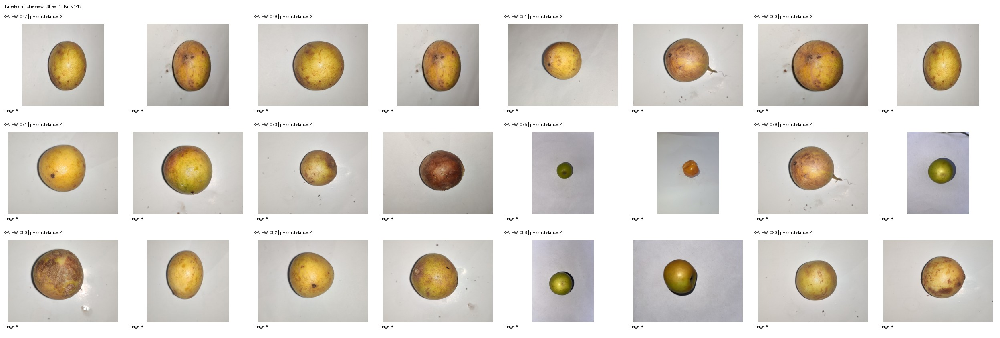

Sheet 2


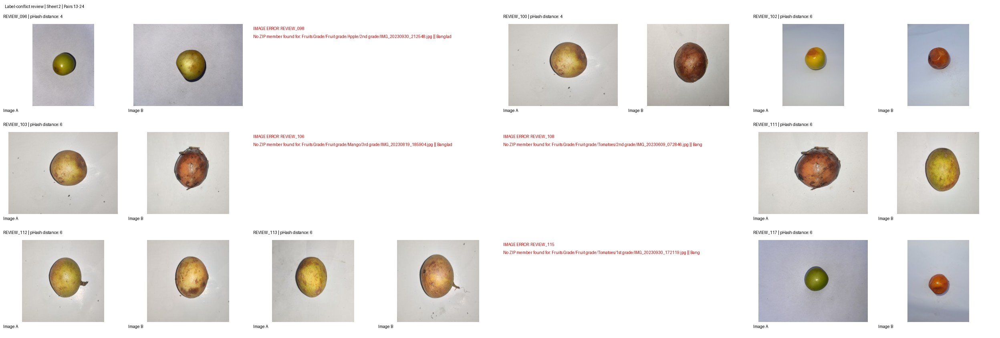

Sheet 3


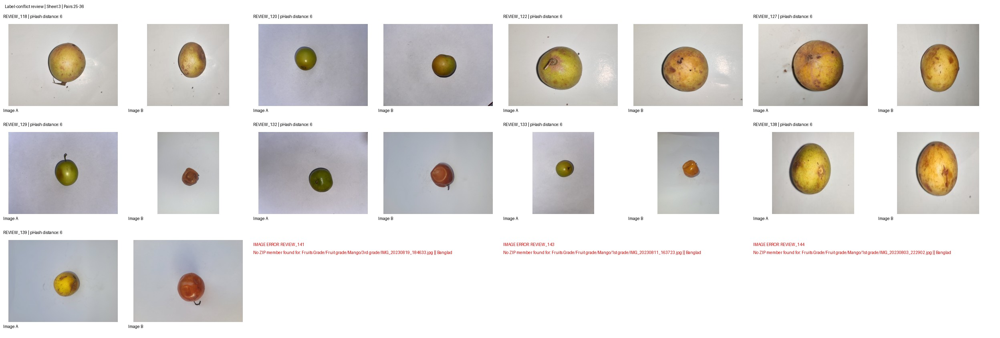

Sheet 4


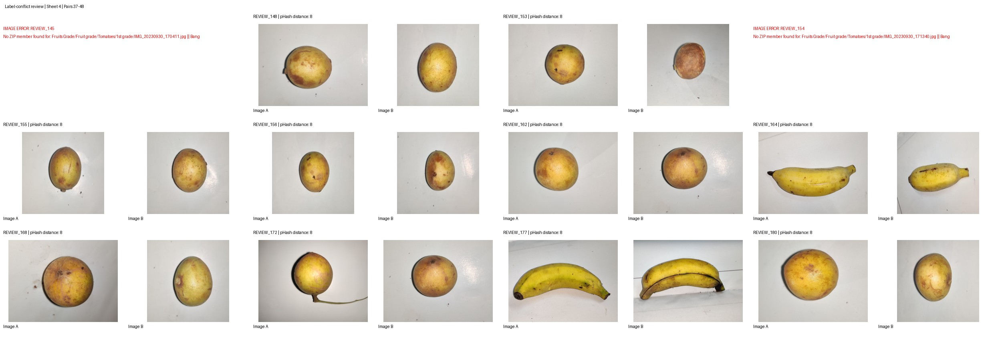

In [ ]:
from IPython.display import display
from PIL import Image

for i in range(1, 5):
    path = output_dir / f"label_conflict_sheet_{i:02d}.jpg"
    print(f"Sheet {i}")
    display(Image.open(path))

In [ ]:
import pandas as pd
from pathlib import Path

error_file = (
    BASE / "datasets" / "audit" /
    "label_conflict_contact_sheets" /
    "image_loading_errors.csv"
)

errors = pd.read_csv(error_file)

print("Number of failed pairs:", len(errors))

for _, row in errors.iterrows():
    print("\nPair:", row["review_pair_id"])
    print("Error:", row["error"])

Number of failed pairs: 9

Pair: REVIEW_098
Error: No ZIP member found for: Fruits Grade/Fruit grade/Apple/2nd grade/IMG_20230930_212548.jpg || Bangladeshi: Bangladeshi Fruit Grade classification/Fruit grade/Apple/2nd grade/IMG_20230930_212548.jpg

Pair: REVIEW_106
Error: No ZIP member found for: Fruits Grade/Fruit grade/Mango/3rd grade/IMG_20230819_185904.jpg || Bangladeshi: Bangladeshi Fruit Grade classification/Fruit grade/Mango/3rd grade/IMG_20230819_185904.jpg

Pair: REVIEW_108
Error: No ZIP member found for: Fruits Grade/Fruit grade/Tomatoes/2nd grade/IMG_20230609_072846.jpg || Bangladeshi: Bangladeshi Fruit Grade classification/Fruit grade/Tomatoes/2nd grade/IMG_20230609_072846.jpg

Pair: REVIEW_115
Error: No ZIP member found for: Fruits Grade/Fruit grade/Tomatoes/1st grade/IMG_20230930_172119.jpg || Bangladeshi: Bangladeshi Fruit Grade classification/Fruit grade/Tomatoes/1st grade/IMG_20230930_172119.jpg

Pair: REVIEW_141
Error: No ZIP member found for: Fruits Grade/Fruit grade

In [ ]:
for _, row in errors.iterrows():
    pair_id = row["review_pair_id"]

    print("\n---", pair_id, "---")

    for column in ["paths_a", "paths_b"]:
        if column not in conflicts.columns:
            continue

        path_value = conflicts.loc[
            conflicts["review_pair_id"] == pair_id, column
        ].iloc[0]

        print(column, ":", path_value)


--- REVIEW_098 ---
paths_a : AFruitDB: Fruits Grade/Fruit grade/Apple/2nd grade/IMG_20230930_212548.jpg || Bangladeshi: Bangladeshi Fruit Grade classification/Fruit grade/Apple/2nd grade/IMG_20230930_212548.jpg
paths_b : Bangladeshi: Bangladeshi Fruit Grade classification/Fruit grade/Burmese_grape/1st grade/IMG_20230713_182846.jpg

--- REVIEW_106 ---
paths_a : AFruitDB: Fruits Grade/Fruit grade/Burmese_grape/1st grade/IMG_20230713_182446.jpg
paths_b : AFruitDB: Fruits Grade/Fruit grade/Mango/3rd grade/IMG_20230819_185904.jpg || Bangladeshi: Bangladeshi Fruit Grade classification/Fruit grade/Mango/3rd grade/IMG_20230819_185904.jpg

--- REVIEW_108 ---
paths_a : AFruitDB: Fruits Grade/Fruit grade/Tomatoes/2nd grade/IMG_20230609_072846.jpg || Bangladeshi: Bangladeshi Fruit Grade classification/Fruit grade/Tomatoes/2nd grade/IMG_20230609_072846.jpg
paths_b : Bangladeshi: Bangladeshi Fruit Grade classification/Fruit grade/Jujube/3rd grade/20250116_140906.jpg

--- REVIEW_115 ---
paths_a : AF

In [ ]:
def load_image(path_value):
    """
    A manifest field may contain multiple source paths
    separated by ' || '. Try each path until one works.
    """

    candidates = [
        item.strip()
        for item in str(path_value).split(" || ")
        if item.strip()
    ]

    errors_found = []

    for candidate in candidates:
        try:
            source, relative_path = get_source_and_path(candidate)

            if source == "Bangladeshi":
                archive = bangla_zip
                members = bangla_members
            elif source == "AFruitDB":
                archive = afruit_zip
                members = afruit_members
            else:
                raise ValueError(f"Unknown source: {source}")

            member_name = resolve_member(members, relative_path)

            with archive.open(member_name) as f:
                image = Image.open(f)
                image.load()
                return ImageOps.exif_transpose(image).convert("RGB")

        except Exception as exc:
            errors_found.append(f"{candidate}: {exc}")

    raise FileNotFoundError(
        "No source path could be loaded.\n" +
        "\n".join(errors_found)
    )

In [ ]:
errors = []

for sheet_number in range(math.ceil(len(conflicts) / PAIRS_PER_SHEET)):
    start = sheet_number * PAIRS_PER_SHEET
    end = min(start + PAIRS_PER_SHEET, len(conflicts))
    sheet_rows = conflicts.iloc[start:end]

    canvas = Image.new(
        "RGB",
        (SHEET_COLS * PAIR_W, SHEET_ROWS * PAIR_H + 35),
        "white"
    )
    draw = ImageDraw.Draw(canvas)

    draw.text(
        (12, 10),
        f"Label-conflict review | Sheet {sheet_number + 1} "
        f"| Pairs {start + 1}-{end}",
        fill="black",
        font=FONT
    )

    for local_index, (_, row) in enumerate(sheet_rows.iterrows()):
        col = local_index % SHEET_COLS
        sheet_row = local_index // SHEET_COLS

        x = col * PAIR_W + 8
        y = sheet_row * PAIR_H + 35

        try:
            draw_pair(draw, canvas, row, x, y)

        except Exception as exc:
            errors.append({
                "review_pair_id": row["review_pair_id"],
                "error": str(exc)
            })
            draw.text(
                (x, y + 30),
                f"IMAGE ERROR: {row['review_pair_id']}",
                fill="red",
                font=FONT
            )

    output_file = (
        output_dir / f"label_conflict_sheet_{sheet_number + 1:02d}.jpg"
    )
    canvas.save(output_file, quality=90)
    print("Saved:", output_file)

error_file = output_dir / "image_loading_errors_v2.csv"

if errors:
    pd.DataFrame(errors).to_csv(error_file, index=False)

print("\nTotal pairs:", len(conflicts))
print("Remaining image-loading errors:", len(errors))

Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/label_conflict_contact_sheets/label_conflict_sheet_01.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/label_conflict_contact_sheets/label_conflict_sheet_02.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/label_conflict_contact_sheets/label_conflict_sheet_03.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/label_conflict_contact_sheets/label_conflict_sheet_04.jpg

Total pairs: 48
Remaining image-loading errors: 0


In [ ]:
from pathlib import Path
import pandas as pd

BASE = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
output_dir = (
    BASE / "datasets" / "audit" /
    "label_conflict_contact_sheets"
)

input_file = output_dir / "label_conflict_48_review_decisions.csv"

decisions = pd.read_csv(input_file)

decisions["manual_decision"] = "different_image"
decisions["reviewer"] = "User"
decisions["review_date"] = "2026-11-19"
decisions["review_notes"] = (
    "Visually reviewed in contact sheets; "
    "reviewer judged the two images to be different photographs."
)

output_file = output_dir / "label_conflict_48_review_decisions_completed.csv"
decisions.to_csv(output_file, index=False)

print("Saved:", output_file)
print("\nDecision summary:")
print(decisions["manual_decision"].value_counts())
print("\nTotal reviewed pairs:", len(decisions))
print("Unique pair IDs:", decisions["review_pair_id"].nunique())

Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/label_conflict_contact_sheets/label_conflict_48_review_decisions_completed.csv

Decision summary:
manual_decision
different_image    48
Name: count, dtype: int64

Total reviewed pairs: 48
Unique pair IDs: 48


In [ ]:
from pathlib import Path
import pandas as pd
import math
from PIL import Image, ImageDraw
from IPython.display import display

# Load all 180 candidates
review_path = (
    BASE / "datasets" / "audit" /
    "near_duplicate_visual_review_sheet_prioritized.csv"
)
all_pairs = pd.read_csv(review_path)

# Select the 132 pairs not included in the 48 conflict batch
remaining = all_pairs[
    all_pairs["label_relation"].astype(str).str.lower() == "same"
].copy().reset_index(drop=True)

assert len(remaining) == 132, (
    f"Expected 132 pairs, found {len(remaining)}"
)

# Separate output directory
remaining_dir = (
    BASE / "datasets" / "audit" /
    "same_label_contact_sheets"
)
remaining_dir.mkdir(parents=True, exist_ok=True)

print("Pairs to review:", len(remaining))
print("Distance distribution:")
print(remaining["hamming_distance"].value_counts().sort_index())

# Create a decision worksheet
decision_columns = [
    "review_pair_id", "hamming_distance",
    "source_relation", "fruit_relation", "grade_relation",
    "label_relation", "datasets_a", "datasets_b",
    "paths_a", "paths_b", "sha256_a", "sha256_b",
    "manual_decision", "reviewer", "review_date", "review_notes"
]

worksheet = remaining[decision_columns].copy()
worksheet["manual_decision"] = ""
worksheet["reviewer"] = ""
worksheet["review_date"] = ""
worksheet["review_notes"] = ""

worksheet_path = (
    remaining_dir / "same_label_132_review_decisions.csv"
)
worksheet.to_csv(worksheet_path, index=False)

# Contact-sheet dimensions
COLS = 4
ROWS = 3
PER_SHEET = COLS * ROWS

for sheet_no in range(math.ceil(len(remaining) / PER_SHEET)):
    start = sheet_no * PER_SHEET
    end = min(start + PER_SHEET, len(remaining))
    batch = remaining.iloc[start:end]

    canvas = Image.new(
        "RGB",
        (COLS * PAIR_W, ROWS * PAIR_H + 35),
        "white"
    )
    draw = ImageDraw.Draw(canvas)

    draw.text(
        (12, 10),
        f"Same-label review | Sheet {sheet_no + 1} "
        f"| Pairs {start + 1}-{end}",
        fill="black",
        font=FONT
    )

    sheet_errors = []

    for j, (_, row) in enumerate(batch.iterrows()):
        x = (j % COLS) * PAIR_W + 8
        y = (j // COLS) * PAIR_H + 35

        try:
            draw_pair(draw, canvas, row, x, y)
        except Exception as exc:
            sheet_errors.append({
                "review_pair_id": row["review_pair_id"],
                "error": str(exc)
            })
            draw.text(
                (x, y + 30),
                f"IMAGE ERROR: {row['review_pair_id']}",
                fill="red",
                font=FONT
            )

    output_file = (
        remaining_dir / f"same_label_sheet_{sheet_no + 1:02d}.jpg"
    )
    canvas.save(output_file, quality=90)
    print("Saved:", output_file)

    if sheet_errors:
        pd.DataFrame(sheet_errors).to_csv(
            remaining_dir /
            f"image_errors_sheet_{sheet_no + 1:02d}.csv",
            index=False
        )

print("\nDecision worksheet:", worksheet_path)
print("Contact sheets:", remaining_dir)

Pairs to review: 132
Distance distribution:
hamming_distance
0    40
2    26
4    19
6    22
8    25
Name: count, dtype: int64
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/same_label_contact_sheets/same_label_sheet_01.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/same_label_contact_sheets/same_label_sheet_02.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/same_label_contact_sheets/same_label_sheet_03.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/same_label_contact_sheets/same_label_sheet_04.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/same_label_contact_sheets/same_label_sheet_05.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/same_label_contact_sheets/same_label_sheet_06.jpg
Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/same_label_contact_sheets/same_label_sheet_07.jpg
Saved: /content/drive/MyDrive/Fru

Sheet 1


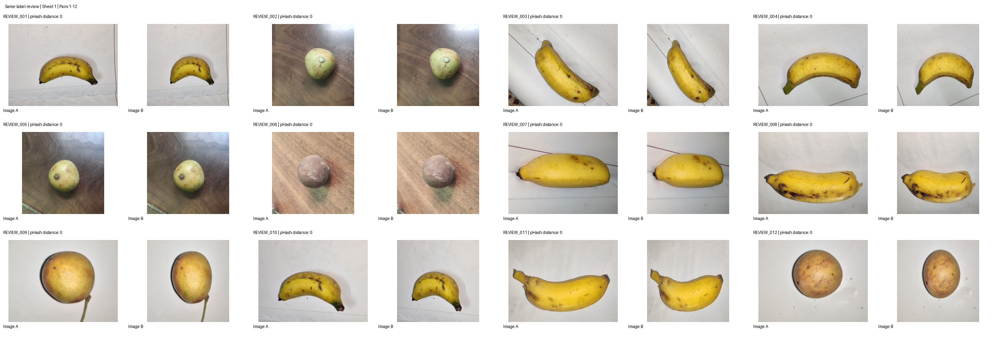

Sheet 2


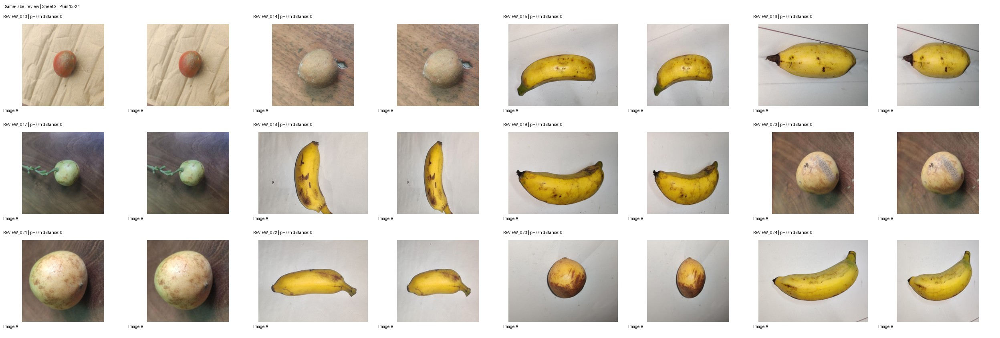

Sheet 3


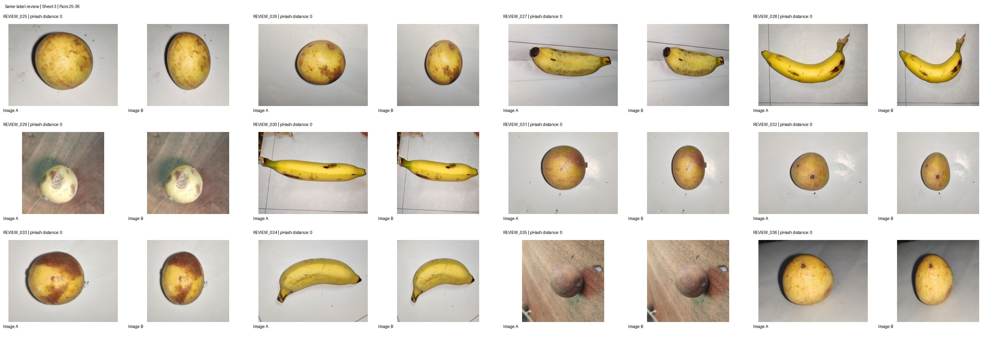

Sheet 4


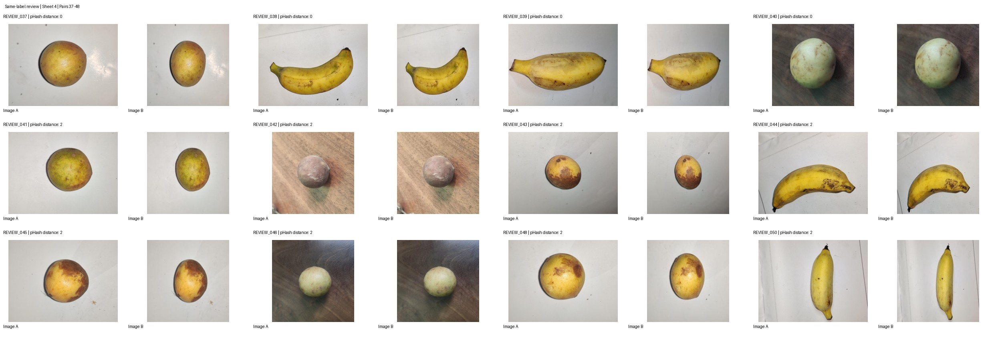

Sheet 5


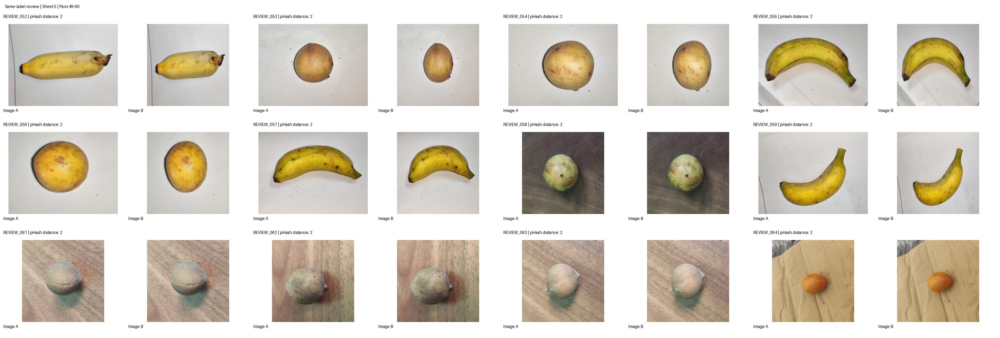

Sheet 6


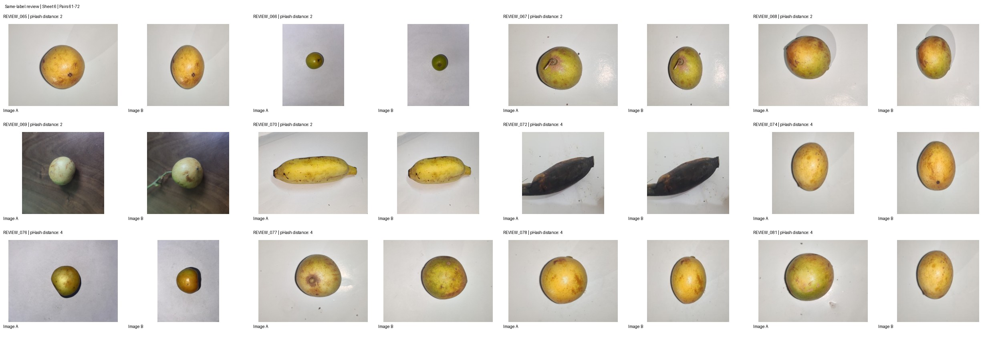

Sheet 7


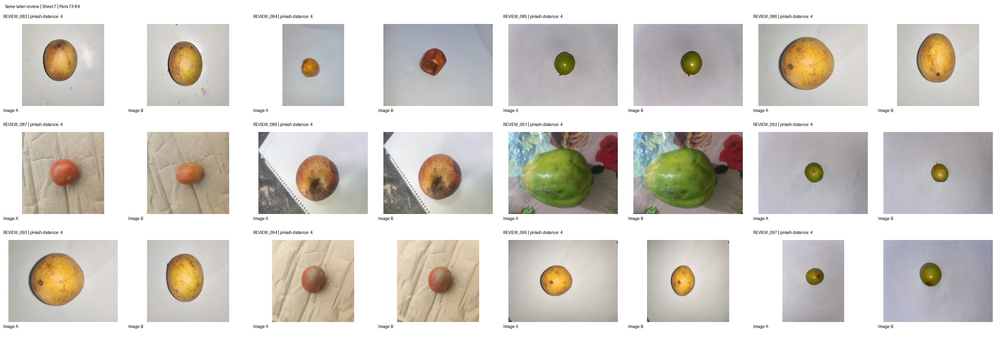

Sheet 8


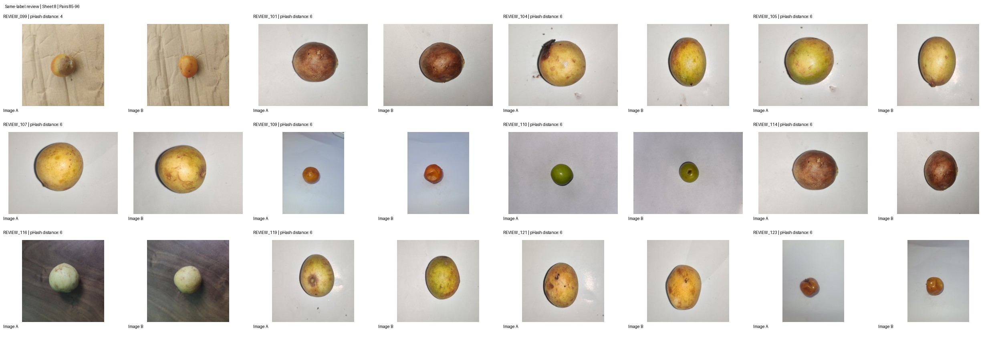

Sheet 9


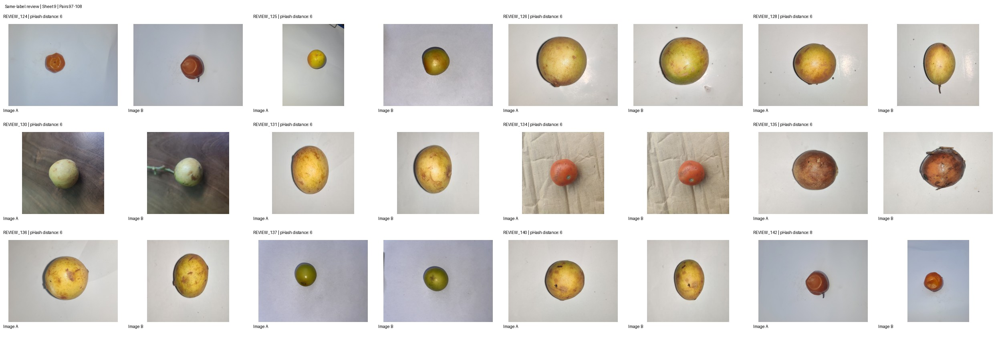

Sheet 10


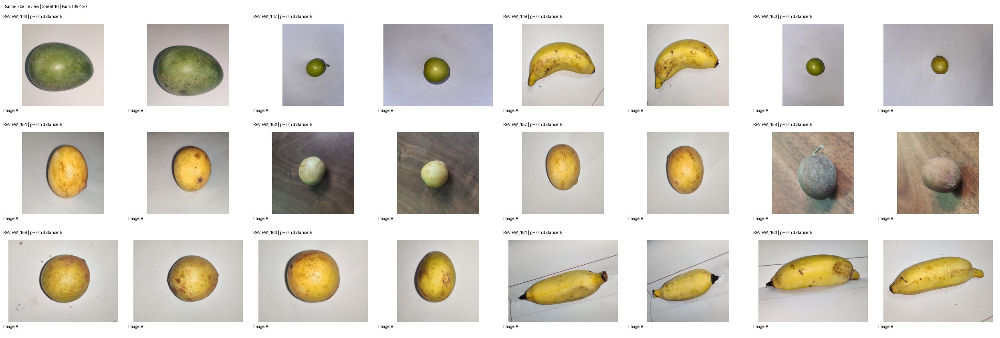

Sheet 11


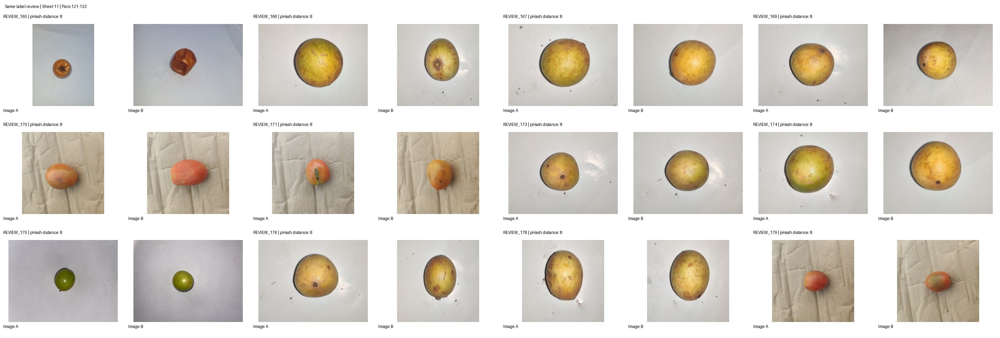

In [ ]:
for i in range(1, 12):
    path = remaining_dir / f"same_label_sheet_{i:02d}.jpg"
    if path.exists():
        print(f"Sheet {i}")
        display(Image.open(path))

In [ ]:
import pandas as pd
from pathlib import Path

review_file = (
    BASE / "datasets" / "audit" /
    "same_label_contact_sheets" /
    "same_label_132_review_decisions.csv"
)

df = pd.read_csv(review_file)

# Record the 40 distance-zero pairs
zero_mask = df["hamming_distance"] == 0

df.loc[zero_mask, "manual_decision"] = "same_image"
df.loc[zero_mask, "reviewer"] = "User and assistant visual review"
df.loc[zero_mask, "review_date"] = "2026-11-19"
df.loc[zero_mask, "review_notes"] = (
    "Visually inspected in contact sheets; "
    "same underlying photograph, with minor presentation differences."
)

output_file = (
    BASE / "datasets" / "audit" /
    "same_label_contact_sheets" /
    "same_label_132_review_decisions_partial.csv"
)

df.to_csv(output_file, index=False)

print("Saved:", output_file)
print("\nDecision counts:")
print(df["manual_decision"].value_counts(dropna=False))

print("\nDistance-zero pairs marked same_image:",
      (df.loc[zero_mask, "manual_decision"] == "same_image").sum())
print("Pairs still awaiting review:", df["manual_decision"].isna().sum())

Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/same_label_contact_sheets/same_label_132_review_decisions_partial.csv

Decision counts:
manual_decision
NaN           92
same_image    40
Name: count, dtype: int64

Distance-zero pairs marked same_image: 40
Pairs still awaiting review: 92


/tmp/ipykernel_22855/3371694362.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'same_image' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[zero_mask, "manual_decision"] = "same_image"
/tmp/ipykernel_22855/3371694362.py:16: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'User and assistant visual review' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[zero_mask, "reviewer"] = "User and assistant visual review"
/tmp/ipykernel_22855/3371694362.py:17: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '2026-11-19' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[zero_mask, "review_date"] = "2026-11-19

In [ ]:
import pandas as pd
from pathlib import Path

review_dir = (
    BASE / "datasets" / "audit" /
    "same_label_contact_sheets"
)

input_file = review_dir / "same_label_132_review_decisions.csv"
output_file = review_dir / "same_label_132_review_decisions_partial.csv"

df = pd.read_csv(input_file)

# Explicitly define text columns as strings
text_columns = [
    "manual_decision",
    "reviewer",
    "review_date",
    "review_notes"
]

for col in text_columns:
    df[col] = df[col].astype("string")

# Record the distance-zero visual decisions
zero_mask = df["hamming_distance"].eq(0)

df.loc[zero_mask, "manual_decision"] = "same_image"
df.loc[zero_mask, "reviewer"] = "User and assistant visual review"
df.loc[zero_mask, "review_date"] = "2026-11-19"
df.loc[zero_mask, "review_notes"] = (
    "Visually inspected in contact sheets; "
    "same underlying photograph, with minor presentation differences."
)

df.to_csv(output_file, index=False)

print("Saved:", output_file)
print("\nDecision counts:")
print(df["manual_decision"].value_counts(dropna=False))

print("\nUnique pair IDs:", df["review_pair_id"].nunique())
print("Distance-zero pairs:", int(zero_mask.sum()))
print("Unreviewed pairs:", int(df["manual_decision"].isna().sum()))
print("\nColumn types:")
print(df[text_columns].dtypes)

Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/same_label_contact_sheets/same_label_132_review_decisions_partial.csv

Decision counts:
manual_decision
<NA>          92
same_image    40
Name: count, dtype: Int64

Unique pair IDs: 132
Distance-zero pairs: 40
Unreviewed pairs: 92

Column types:
manual_decision    string[python]
reviewer           string[python]
review_date        string[python]
review_notes       string[python]
dtype: object


In [ ]:

import pandas as pd
import re
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Fruit_Freshness_Research")

review_dir = (
    BASE / "datasets" / "audit" /
    "same_label_contact_sheets"
)

input_file = (
    review_dir / "same_label_132_review_decisions_partial.csv"
)

output_file = (
    review_dir / "same_label_132_review_decisions_completed.csv"
)

df = pd.read_csv(input_file)

# Ensure decision fields can safely contain text
for col in ["manual_decision", "reviewer", "review_date", "review_notes"]:
    df[col] = df[col].astype("string")

# Normalise pair IDs by removing whitespace
df["_normalised_id"] = (
    df["review_pair_id"]
    .astype("string")
    .str.replace(r"\s+", "", regex=True)
)

# The 13 explicitly identified pairs
explicit_different = {
    "REVIEW_066",
    "REVIEW_069",
    "REVIEW_074",
    "REVIEW_078",
    "REVIEW_081",
    "REVIEW_083",
    "REVIEW_084",
    "REVIEW_085",
    "REVIEW_087",
    "REVIEW_092",
    "REVIEW_093",
    "REVIEW_097",
}

# Only update the 92 previously unreviewed pairs
unreviewed = df["manual_decision"].isna()

assert int(unreviewed.sum()) == 92, (
    f"Expected 92 unreviewed pairs, found {unreviewed.sum()}"
)

distance = pd.to_numeric(df["hamming_distance"], errors="coerce")

explicit_mask = (
    unreviewed &
    df["_normalised_id"].isin(explicit_different)
)

distance_mask = (
    unreviewed &
    distance.isin([6, 8])
)

# Union of both different-image rules
different_mask = explicit_mask | distance_mask

# All other unreviewed pairs are same_image
same_mask = unreviewed & ~different_mask

# Apply decisions
df.loc[different_mask, "manual_decision"] = "different_image"
df.loc[same_mask, "manual_decision"] = "same_image"

# Record reviewer and date for this batch
df.loc[unreviewed, "reviewer"] = "User"
df.loc[unreviewed, "review_date"] = "2026-11-20"

# Preserve the reason for each decision
df.loc[explicit_mask, "review_notes"] = (
    "User explicitly judged this pair as a different photograph."
)

distance_only_mask = distance_mask & ~explicit_mask

df.loc[distance_only_mask, "review_notes"] = (
    "User instructed that all remaining pairs at pHash distance "
    "6 or 8 are different photographs."
)

same_mask_notes = same_mask

df.loc[same_mask_notes, "review_notes"] = (
    "User instructed that all other remaining pairs are the same image."
)

# Remove temporary column
df.drop(columns=["_normalised_id"], inplace=True)

# Validate before saving
assert df["review_pair_id"].nunique() == 132
assert df["manual_decision"].notna().all()
assert set(df["manual_decision"].unique()).issubset(
    {"same_image", "different_image", "uncertain"}
)

df.to_csv(output_file, index=False)

print("Saved:", output_file)
print("\nFinal decision counts:")
print(df["manual_decision"].value_counts())

print("\nNew batch decisions:")
print("Explicit IDs marked different:", int(explicit_mask.sum()))
print("Distance 6/8 rule, including overlaps:", int(different_mask.sum()))
print("Remaining pairs marked same:", int(same_mask.sum()))

print("\nFinal counts by pHash distance:")
print(pd.crosstab(df["hamming_distance"], df["manual_decision"]))

print("\nUnreviewed pairs:", int(df["manual_decision"].isna().sum()))


Saved: /content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/same_label_contact_sheets/same_label_132_review_decisions_completed.csv

Final decision counts:
manual_decision
same_image         73
different_image    59
Name: count, dtype: Int64

New batch decisions:
Explicit IDs marked different: 12
Distance 6/8 rule, including overlaps: 59
Remaining pairs marked same: 33

Final counts by pHash distance:
manual_decision   different_image  same_image
hamming_distance                             
0                               0          40
2                               2          24
4                              10           9
6                              22           0
8                              25           0

Unreviewed pairs: 0


In [ ]:
import pandas as pd

completed_file = (
    BASE / "datasets" / "audit" /
    "same_label_contact_sheets" /
    "same_label_132_review_decisions_completed.csv"
)

df = pd.read_csv(completed_file)

expected_ids = {
    "REVIEW_066", "REVIEW_069", "REVIEW_074",
    "REVIEW_078", "REVIEW_081", "REVIEW_083",
    "REVIEW_084", "REVIEW_085", "REVIEW_087",
    "REVIEW_092", "REVIEW_093", "REVIEW_097",
    # Add the 13th ID exactly as you intended.
}

actual_ids = set(
    df["review_pair_id"].astype(str).str.replace(r"\s+", "", regex=True)
)

print("Explicit IDs found:", sorted(expected_ids & actual_ids))
print("Explicit IDs not found:", sorted(expected_ids - actual_ids))

Explicit IDs found: ['REVIEW_066', 'REVIEW_069', 'REVIEW_074', 'REVIEW_078', 'REVIEW_081', 'REVIEW_083', 'REVIEW_084', 'REVIEW_085', 'REVIEW_087', 'REVIEW_092', 'REVIEW_093', 'REVIEW_097']
Explicit IDs not found: []


In [ ]:
check = df[
    df["review_pair_id"].astype(str).str.replace(r"\s+", "", regex=True)
    .eq("REVIEW_097")
]

display(check[
    ["review_pair_id", "hamming_distance", "manual_decision", "review_notes"]
])

,review_pair_id,hamming_distance,manual_decision,review_notes
83,REVIEW_097,4,different_image,User explicitly judged this pair as a differen...


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

# ============================================================
# 1. Locate the existing audit files
# ============================================================
BASE = Path("/content/drive/MyDrive/Fruit_Freshness_Research")
AUDIT = BASE / "datasets" / "audit"

manifest_file = AUDIT / "combined_image_manifest.csv"

review_132_file = (
    AUDIT / "same_label_contact_sheets" /
    "same_label_132_review_decisions_completed.csv"
)

pilot_file = AUDIT / "phash_distance_0_visual_pilot_24_resolved.csv"

output_dir = AUDIT / "final_reconciliation"
output_dir.mkdir(parents=True, exist_ok=True)

for f in [manifest_file, review_132_file, pilot_file]:
    assert f.exists(), f"Required file not found: {f}"
    print("Found:", f.name)

# ============================================================
# 2. Load the original image manifest
# ============================================================
manifest = pd.read_csv(manifest_file, dtype=str)

required = {"sha256", "fruit", "grade", "dataset", "relative_path"}
missing = required - set(manifest.columns)

assert not missing, f"Manifest is missing columns: {missing}"
assert manifest["sha256"].notna().all()

manifest["sha256"] = manifest["sha256"].str.lower().str.strip()

print("\nOriginal manifest rows:", len(manifest))
print("Unique SHA-256 hashes:", manifest["sha256"].nunique())

# ============================================================
# 3. Union-find: group visually confirmed duplicate images
# ============================================================
parent = {}
rank = {}

def find(x):
    parent.setdefault(x, x)
    if parent[x] != x:
        parent[x] = find(parent[x])
    return parent[x]

def union(a, b):
    if pd.isna(a) or pd.isna(b):
        return
    a, b = str(a).lower().strip(), str(b).lower().strip()
    if not a or not b or a == "nan" or b == "nan":
        return

    ra, rb = find(a), find(b)
    if ra == rb:
        return

    if rank.get(ra, 0) < rank.get(rb, 0):
        ra, rb = rb, ra

    parent[rb] = ra
    if rank.get(ra, 0) == rank.get(rb, 0):
        rank[ra] = rank.get(ra, 0) + 1

# Register every unique image hash.
for h in manifest["sha256"].unique():
    find(h)

# ============================================================
# 4. Add the 73 same-image links from the 132-pair review
# ============================================================
review = pd.read_csv(review_132_file, dtype=str)

assert len(review) == 132
assert review["manual_decision"].notna().all()

same_review = review[
    review["manual_decision"].str.strip() == "same_image"
]

for _, row in same_review.iterrows():
    union(row["sha256_a"], row["sha256_b"])

print("\nSame-image links from 132-pair review:", len(same_review))

# ============================================================
# 5. Add the 24 previously confirmed visual pilot links
# ============================================================
pilot = pd.read_csv(pilot_file, dtype=str)

assert len(pilot) == 24

# Locate the SHA columns, allowing common naming variations.
def find_sha_column(df, suffix):
    possible = [
        f"sha256_{suffix}",
        f"sha_{suffix}",
        f"sha256{suffix.upper()}"
    ]
    for c in possible:
        if c in df.columns:
            return c
    raise ValueError(
        f"Could not find SHA column for side {suffix}. "
        f"Available columns: {df.columns.tolist()}"
    )

pilot_sha_a = find_sha_column(pilot, "a")
pilot_sha_b = find_sha_column(pilot, "b")

# Include only pairs explicitly adjudicated as same_image,
# if the decision column is present.
if "manual_decision" in pilot.columns:
    pilot_same = pilot[
        pilot["manual_decision"].astype(str).str.strip() == "same_image"
    ]
else:
    pilot_same = pilot

for _, row in pilot_same.iterrows():
    union(row[pilot_sha_a], row[pilot_sha_b])

print("Pilot visual same-image links:", len(pilot_same))

# ============================================================
# 6. Build connected components
# ============================================================
components = {}

for h in manifest["sha256"].unique():
    root = find(h)
    components.setdefault(root, []).append(h)

# Stable group IDs based on sorted hashes.
hash_to_group = {}

duplicate_number = 0

for hashes in components.values():
    if len(hashes) > 1:
        duplicate_number += 1
        group_id = f"DUP_{duplicate_number:04d}"
    else:
        group_id = "SINGLETON"

    for h in hashes:
        hash_to_group[h] = group_id

manifest["duplicate_group_id"] = manifest["sha256"].map(hash_to_group)
manifest["duplicate_group_unique_hashes"] = (
    manifest["duplicate_group_id"].map({
        hash_to_group[h]: len(components[find(h)])
        for h in manifest["sha256"].unique()
    })
)

# ============================================================
# 7. Quarantine the three known conflicting Mango hashes
# ============================================================
conflict_hashes = {
    "584f6114919733e6b4ef13d2b4c1caf569ade6e442a878f23bfedc4b5e809a24",
    "8523098a18c6f31158d7029091cc4db33d9ffd324aca5ad3916a71e39ef562ee",
    "c8f588220a005f12bc213975c70d8318cd02b8a95a4a18199c476e77e87300c6"
}

manifest["quarantine_reason"] = ""
manifest.loc[
    manifest["sha256"].isin(conflict_hashes),
    "quarantine_reason"
] = "Exact duplicate image assigned conflicting 1st and 2nd grade labels"

manifest["dataset_status"] = np.where(
    manifest["quarantine_reason"].ne(""),
    "QUARANTINE_LABEL_CONFLICT",
    "RETAIN_PENDING_FINAL_QC"
)

# ============================================================
# 8. Audit label conflicts within connected groups
# ============================================================
group_rows = []

for group_id, group in manifest.groupby("duplicate_group_id"):
    unique_hashes = group["sha256"].nunique()
    fruits = sorted(group["fruit"].dropna().unique().tolist())
    grades = sorted(group["grade"].dropna().unique().tolist())
    joint_labels = sorted(
        (group["fruit"].fillna("") + " / " +
         group["grade"].fillna("")).unique().tolist()
    )

    group_rows.append({
        "duplicate_group_id": group_id,
        "manifest_rows": len(group),
        "unique_image_hashes": unique_hashes,
        "source_datasets": ";".join(
            sorted(group["dataset"].dropna().unique())
        ),
        "fruit_labels": ";".join(fruits),
        "grade_labels": ";".join(grades),
        "joint_labels": ";".join(joint_labels),
        "fruit_label_conflict": len(fruits) > 1,
        "grade_label_conflict": len(grades) > 1,
        "requires_quarantine": (
            group["quarantine_reason"].ne("").any()
            or len(fruits) > 1
            or len(grades) > 1
        )
    })

group_summary = pd.DataFrame(group_rows)

# Attach group-level status to every image record.
status_map = group_summary.set_index(
    "duplicate_group_id"
)["requires_quarantine"].to_dict()

manifest["group_requires_quarantine"] = (
    manifest["duplicate_group_id"].map(status_map)
)

# ============================================================
# 9. Save outputs
# ============================================================
manifest_output = output_dir / "reconciled_image_manifest.csv"
summary_output = output_dir / "duplicate_group_summary.csv"
quarantine_output = output_dir / "quarantine_images.csv"

manifest.to_csv(manifest_output, index=False)
group_summary.to_csv(summary_output, index=False)

quarantine = manifest[
    manifest["group_requires_quarantine"] == True
].copy()

quarantine.to_csv(quarantine_output, index=False)

# ============================================================
# 10. Final validation and report
# ============================================================
print("\n========== RECONCILIATION RESULTS ==========")

print("Original manifest rows:", len(manifest))
print("Unique image hashes:", manifest["sha256"].nunique())

print(
    "Duplicate groups:",
    (group_summary["unique_image_hashes"] > 1).sum()
)

print(
    "Hashes in duplicate groups:",
    group_summary.loc[
        group_summary["unique_image_hashes"] > 1,
        "unique_image_hashes"
    ].sum()
)

print(
    "Singleton hashes:",
    (group_summary["unique_image_hashes"] == 1).sum()
)

print(
    "Groups with grade conflicts:",
    group_summary["grade_label_conflict"].sum()
)

print(
    "Groups requiring quarantine:",
    group_summary["requires_quarantine"].sum()
)

print("Quarantine manifest rows:", len(quarantine))

print("\nSaved files:")
print(manifest_output)
print(summary_output)
print(quarantine_output)

# Integrity checks
assert len(manifest) == len(pd.read_csv(manifest_file))
assert manifest["sha256"].nunique() == len(hash_to_group)
assert manifest["duplicate_group_id"].notna().all()

print("\nVALIDATION PASSED")


Found: combined_image_manifest.csv
Found: same_label_132_review_decisions_completed.csv
Found: phash_distance_0_visual_pilot_24_resolved.csv

Original manifest rows: 6923
Unique SHA-256 hashes: 4868

Same-image links from 132-pair review: 73
Pilot visual same-image links: 24

========== RECONCILIATION RESULTS ==========
Original manifest rows: 6923
Unique image hashes: 4868
Duplicate groups: 95
Hashes in duplicate groups: 4868
Singleton hashes: 0
Groups with grade conflicts: 1
Groups requiring quarantine: 1
Quarantine manifest rows: 6721

Saved files:
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/final_reconciliation/reconciled_image_manifest.csv
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/final_reconciliation/duplicate_group_summary.csv
/content/drive/MyDrive/Fruit_Freshness_Research/datasets/audit/final_reconciliation/quarantine_images.csv

VALIDATION PASSED


In [ ]:
import pandas as pd
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/audit/final_reconciliation"
)

manifest = pd.read_csv(base / "reconciled_image_manifest.csv")
summary = pd.read_csv(base / "duplicate_group_summary.csv")
quarantine = pd.read_csv(base / "quarantine_images.csv")

print("GROUP SUMMARY COLUMNS:")
print(summary.columns.tolist())

print("\nGROUP SIZE DISTRIBUTION:")
size_col = next(
    (c for c in summary.columns
     if "unique_hash" in c.lower() or "hash_count" in c.lower()),
    None
)

if size_col:
    print(summary[size_col].describe())
    print("\nLargest 20 groups:")
    print(summary.sort_values(size_col, ascending=False).head(20).to_string(index=False))
else:
    print(summary.head(10).to_string(index=False))

print("\nQUARANTINE ROWS:", len(quarantine))
print("\nMANIFEST GROUP COUNTS:")
print(manifest["duplicate_group_id"].nunique())
print(manifest["duplicate_group_id"].value_counts().head(20))

GROUP SUMMARY COLUMNS:
['duplicate_group_id', 'manifest_rows', 'unique_image_hashes', 'source_datasets', 'fruit_labels', 'grade_labels', 'joint_labels', 'fruit_label_conflict', 'grade_label_conflict', 'requires_quarantine']

GROUP SIZE DISTRIBUTION:
duplicate_group_id  manifest_rows  unique_image_hashes   source_datasets fruit_labels grade_labels       joint_labels  fruit_label_conflict  grade_label_conflict  requires_quarantine
          DUP_0001              4                    2 AFruitDB;Expanded        Apple    3rd grade  Apple / 3rd grade                 False                 False                False
          DUP_0002              2                    2 AFruitDB;Expanded       Banana    1st grade Banana / 1st grade                 False                 False                False
          DUP_0003              2                    2 AFruitDB;Expanded       Banana    1st grade Banana / 1st grade                 False                 False                False
          DUP_0004

In [ ]:
import pandas as pd
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/audit/final_reconciliation"
)

summary = pd.read_csv(base / "duplicate_group_summary.csv")
quarantine = pd.read_csv(base / "quarantine_images.csv")
manifest = pd.read_csv(base / "reconciled_image_manifest.csv")

print("Duplicate groups:", len(summary))
print("\nGroups requiring quarantine:")
print(summary[summary["requires_quarantine"]].to_string(index=False))

print("\nQuarantine columns:")
print(quarantine.columns.tolist())

print("\nQuarantine status counts:")
for col in ["dataset_status", "requires_quarantine",
            "duplicate_group_id", "grade_label_conflict"]:
    if col in quarantine.columns:
        print(f"\n{col}:")
        print(quarantine[col].value_counts(dropna=False).head(10))

print("\nManifest status counts:")
if "dataset_status" in manifest.columns:
    print(manifest["dataset_status"].value_counts(dropna=False))

Duplicate groups: 95

Groups requiring quarantine:
duplicate_group_id  manifest_rows  unique_image_hashes   source_datasets                                             fruit_labels                  grade_labels                                                                                                                                                                                                                                                                                                                                                                                                                           joint_labels  fruit_label_conflict  grade_label_conflict  requires_quarantine
         SINGLETON           6721                 4677 AFruitDB;Expanded Apple;Banana;Burmese_grape;Jujube;Mango;Papayas;Tomatoes 1st grade;2nd grade;3rd grade Apple / 1st grade;Apple / 2nd grade;Apple / 3rd grade;Banana / 1st grade;Banana / 2nd grade;Banana / 3rd grade;Burmese_grape / 1st grade;Burm

In [ ]:
import pandas as pd
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/audit/final_reconciliation"
)

manifest = pd.read_csv(base / "reconciled_image_manifest.csv")

# Keep only records explicitly marked as label conflicts
quarantine = manifest[
    manifest["dataset_status"] == "QUARANTINE_LABEL_CONFLICT"
].copy()

# All other records remain candidates, pending final quality checks
retained = manifest[
    manifest["dataset_status"] != "QUARANTINE_LABEL_CONFLICT"
].copy()

# Save corrected outputs
quarantine.to_csv(base / "quarantine_label_conflicts.csv", index=False)
retained.to_csv(base / "retained_pending_final_qc.csv", index=False)

print("========== CORRECTED EXPORT ==========")
print("Original manifest rows:", len(manifest))
print("Retained pending final QC:", len(retained))
print("Quarantined rows:", len(quarantine))
print("Retained unique hashes:", retained["sha256"].nunique())
print("Quarantined unique hashes:", quarantine["sha256"].nunique())
print("Total rows check:", len(retained) + len(quarantine))

print("\nQuarantine labels:")
print(quarantine[["fruit", "grade"]].value_counts())

print("\nQuarantine hashes:")
print(quarantine["sha256"].nunique())

========== CORRECTED EXPORT ==========
Original manifest rows: 6923
Retained pending final QC: 6911
Quarantined rows: 12
Retained unique hashes: 4865
Quarantined unique hashes: 3
Total rows check: 6923

Quarantine labels:
fruit  grade    
Mango  1st grade    6
       2nd grade    6
Name: count, dtype: int64

Quarantine hashes:
3


In [ ]:
import pandas as pd
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/audit/final_reconciliation"
)

df = pd.read_csv(base / "retained_pending_final_qc.csv")

# Treat each actual duplicate group as one indivisible unit.
# Give each singleton image its own split unit.
df["split_group"] = df["duplicate_group_id"].where(
    df["duplicate_group_id"] != "SINGLETON",
    "SINGLE_" + df["sha256"].astype(str)
)

print("Retained records:", len(df))
print("Unique image hashes:", df["sha256"].nunique())
print("Unique split groups:", df["split_group"].nunique())

print("\nLargest split groups:")
print(
    df.groupby("split_group")["sha256"]
      .nunique()
      .sort_values(ascending=False)
      .head(15)
)

print("\nFruit-grade distribution:")
print(df.groupby(["fruit", "grade"]).size())

Retained records: 6911
Unique image hashes: 4865
Unique split groups: 4768

Largest split groups:
split_group
DUP_0092    3
DUP_0064    3
DUP_0085    3
DUP_0069    2
DUP_0068    2
DUP_0067    2
DUP_0066    2
DUP_0065    2
DUP_0063    2
DUP_0062    2
DUP_0061    2
DUP_0060    2
DUP_0059    2
DUP_0070    2
DUP_0057    2
Name: sha256, dtype: int64

Fruit-grade distribution:
fruit          grade    
Apple          1st grade    396
               2nd grade    344
               3rd grade    224
Banana         1st grade    486
               2nd grade    478
               3rd grade    131
Burmese_grape  1st grade    616
               2nd grade    314
               3rd grade    330
Jujube         1st grade    149
               2nd grade    164
               3rd grade    150
Mango          1st grade    496
               2nd grade    494
               3rd grade    234
Papayas        1st grade    303
               2nd grade    294
               3rd grade    304
Tomatoes       1st grade 

In [ ]:

import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

# --------------------------------------------------
# 1. Load the retained manifest
# --------------------------------------------------
base = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/audit/final_reconciliation"
)

df = pd.read_csv(base / "retained_pending_final_qc.csv")

SEED = 20261119

# --------------------------------------------------
# 2. Create a split-group identifier
# --------------------------------------------------
# Actual duplicate groups stay together.
# Each singleton image gets its own group.
df["split_group"] = df["duplicate_group_id"].where(
    df["duplicate_group_id"] != "SINGLETON",
    "SINGLE_" + df["sha256"].astype(str)
)

# --------------------------------------------------
# 3. Check labels within each split group
# --------------------------------------------------
# First reduce repeated source records to unique images.
unique_images = df.drop_duplicates(subset="sha256").copy()

group_table = (
    unique_images.groupby("split_group")
    .agg(
        fruit=("fruit", "first"),
        grade=("grade", "first"),
        fruit_count=("fruit", "nunique"),
        grade_count=("grade", "nunique"),
        unique_hashes=("sha256", "nunique")
    )
    .reset_index()
)

bad_groups = group_table[
    (group_table["fruit_count"] != 1) |
    (group_table["grade_count"] != 1)
]

if len(bad_groups) > 0:
    raise ValueError(
        "Some split groups still have inconsistent labels. "
        "Inspect these groups before splitting:\n"
        + bad_groups.to_string(index=False)
    )

# Combined class for stratification
group_table["class_label"] = (
    group_table["fruit"].astype(str)
    + " | "
    + group_table["grade"].astype(str)
)

print("Unique images:", len(unique_images))
print("Independent split groups:", len(group_table))
print("Fruit-grade classes:", group_table["class_label"].nunique())

# --------------------------------------------------
# 4. Split groups: 15% test, then 15% validation
# --------------------------------------------------
train_val_groups, test_groups = train_test_split(
    group_table,
    test_size=0.15,
    random_state=SEED,
    stratify=group_table["class_label"]
)

# 15% of the full dataset is 15/85 of the remaining data.
train_groups, val_groups = train_test_split(
    train_val_groups,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=train_val_groups["class_label"]
)

# --------------------------------------------------
# 5. Assign partitions to every original manifest row
# --------------------------------------------------
group_to_split = {}

for groups, split_name in [
    (train_groups, "train"),
    (val_groups, "validation"),
    (test_groups, "test")
]:
    for group_id in groups["split_group"]:
        group_to_split[group_id] = split_name

df["split"] = df["split_group"].map(group_to_split)

if df["split"].isna().any():
    raise ValueError("Some records were not assigned to a split.")

# --------------------------------------------------
# 6. Verify no duplicate-group or hash leakage
# --------------------------------------------------
group_leakage = (
    df.groupby("split_group")["split"].nunique().max()
)

hash_leakage = (
    df.groupby("sha256")["split"].nunique().max()
)

assert group_leakage == 1, "Duplicate group leakage detected."
assert hash_leakage == 1, "SHA-256 image leakage detected."

# --------------------------------------------------
# 7. Save outputs
# --------------------------------------------------
df.to_csv(base / "final_split_manifest.csv", index=False)

for split_name in ["train", "validation", "test"]:
    split_df = df[df["split"] == split_name].copy()
    split_df.to_csv(
        base / f"{split_name}_manifest.csv",
        index=False
    )

# --------------------------------------------------
# 8. Report split sizes and class distributions
# --------------------------------------------------
print("\n========== SPLIT RESULTS ==========")

for split_name in ["train", "validation", "test"]:
    part = df[df["split"] == split_name]

    print(f"\n{split_name.upper()}")
    print("Manifest rows:", len(part))
    print("Unique images:", part["sha256"].nunique())
    print("Split groups:", part["split_group"].nunique())

print("\nFruit-grade distribution by split:")
print(
    pd.crosstab(
        [df["fruit"], df["grade"]],
        df["split"]
    ).to_string()
)

print("\n========== VALIDATION ==========")
print("Duplicate-group leakage:", group_leakage == 1)
print("SHA-256 leakage:", hash_leakage == 1)
print("Missing split assignments:", df["split"].isna().sum())
print("Quarantined records included:",
      (df["dataset_status"] == "QUARANTINE_LABEL_CONFLICT").sum())

print("\nSaved:")
print(base / "final_split_manifest.csv")
print(base / "train_manifest.csv")
print(base / "validation_manifest.csv")
print(base / "test_manifest.csv")

print("\nSPLIT GENERATION COMPLETED")


Unique images: 4865
Independent split groups: 4768
Fruit-grade classes: 21

========== SPLIT RESULTS ==========

TRAIN
Manifest rows: 4835
Unique images: 3405
Split groups: 3336

VALIDATION
Manifest rows: 1033
Unique images: 726
Split groups: 716

TEST
Manifest rows: 1043
Unique images: 734
Split groups: 716

Fruit-grade distribution by split:
split                    test  train  validation
fruit         grade                             
Apple         1st grade    60    276          60
              2nd grade    52    240          52
              3rd grade    34    156          34
Banana        1st grade    72    342          72
              2nd grade    71    335          72
              3rd grade    20     92          19
Burmese_grape 1st grade    93    430          93
              2nd grade    49    220          45
              3rd grade    51    230          49
Jujube        1st grade    22    105          22
              2nd grade    24    115          25
              3rd

In [ ]:
import pandas as pd
from pathlib import Path

base = Path(
    "/content/drive/MyDrive/Fruit_Freshness_Research/"
    "datasets/audit/final_reconciliation"
)

df = pd.read_csv(base / "final_split_manifest.csv")

group_leaks = (
    df.groupby("split_group")["split"].nunique() > 1
).sum()

hash_leaks = (
    df.groupby("sha256")["split"].nunique() > 1
).sum()

print("Duplicate groups crossing partitions:", group_leaks)
print("Image hashes crossing partitions:", hash_leaks)
print("Missing split assignments:", df["split"].isna().sum())

for name in ["train", "validation", "test"]:
    path = base / f"{name}_manifest.csv"
    print(f"{name}: exists={path.exists()}")

assert group_leaks == 0
assert hash_leaks == 0
assert df["split"].notna().all()

print("\nPASS: No detected duplicate-group or exact-image leakage.")

Duplicate groups crossing partitions: 0
Image hashes crossing partitions: 0
Missing split assignments: 0
train: exists=True
validation: exists=True
test: exists=True

PASS: No detected duplicate-group or exact-image leakage.
